# Data preview: Dataset D (Segerstolpe, E-MTAB-5061), Dataset E (Lawlor, GSE86469) and Dataset F (Enge, GSE81547)
In this notebook I examine three further human pancreas datasets, in the same way as `data_preview.ipynb` (Dataset A,
Baron) and `data_preview_dataset_B_and_C.ipynb` (Datasets B and C, Xin and Muraro): **Dataset D = Segerstolpe et al.
2016 (ArrayExpress E-MTAB-5061, Smart-seq2, full-length, healthy and T2D donors)**, **Dataset E = Lawlor et al. 2017
(GSE86469, Fluidigm C1 / SMARTer, healthy and T2D donors)** and **Dataset F = Enge et al. 2017 (GSE81547, Smart-seq2-like
plate protocol, donors aged 1 to 54 years)**. The structure is the same as before: first what the downloaded metadata
files contain and how the expression matrices were obtained, then a full inspection of each dataset (overview →
integrity / missing values → labels → per-cell QC → gene-level behaviour → markers / ambient RNA → global structure →
summary → preprocessing proposal), and finally a comparison with each other and with A/B/C. No model is fitted here.

## 0. Shared setup
Imports, paths, plot style and the helper functions. The helpers are copied from `data_preview_dataset_B_and_C.ipynb`
§0 (themselves the parameterised versions of `data_preview.ipynb` §1.2–1.7), so that D, E and F run exactly the same
checks as A, B and C. Only the label → lineage table is extended with the new label vocabularies.

In [1]:
# --- Imports ---------------------------------------------------------------
import warnings
warnings.filterwarnings("ignore", category=UserWarning)   # silence pandas/numexpr version chatter

from pathlib import Path
import zipfile
import numpy as np
import pandas as pd
import scipy.sparse as sp
import anndata as ad
import scanpy as sc
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_score
import GEOparse
GEOparse.set_verbosity("ERROR")   # otherwise one DEBUG line per GSM (2,544 for Enge)

# --- Reproducibility ------------------------------------------------------------
# PCA (randomised solver) and silhouette subsampling are the only random steps.
SEED = 0
np.random.seed(SEED)

# --- Paths ------------------------------------------------------------------
# Raw files follow the project pattern data/raw/<author>_<accession>/ (data/ is git-ignored). The SOFT files and the
# ArrayExpress zip were copied (not moved) from ~/Downloads/proj_data/; the GEO supplementary matrices were downloaded
# from the GEO FTP/HTTPS URLs listed in the SOFT files; the Ensembl annotation from ftp.ensembl.org. See the
# per-dataset §0 cells for what each file is.
PROJECT  = Path("/home/professor/cell-type-annotaion-benchmark")
RAW      = PROJECT / "data" / "raw"
INTERIM  = PROJECT / "data" / "interim"
SEG_DIR  = RAW / "segerstolpe_E-MTAB-5061"
LAW_DIR  = RAW / "lawlor_GSE86469"
ENGE_DIR = RAW / "enge_GSE81547"
SEG_ZIP  = SEG_DIR / "E-MTAB-5061.zip"                         # copy of the ArrayExpress download
SEG_X    = SEG_DIR / "extracted"                               # the zip, unpacked into its own empty folder
SEG_TAB, SEG_SDRF, SEG_IDF = (SEG_X / "pancreas_refseq_rpkms_counts_3514sc.txt", SEG_X / "E-MTAB-5061.sdrf.txt",
                              SEG_X / "E-MTAB-5061.idf.txt")
LAW_SOFT = LAW_DIR / "GSE86469_family.soft.gz"
LAW_CSV  = LAW_DIR / "GSE86469_GEO.islet.single.cell.processed.data.RSEM.raw.expected.counts.csv.gz"
ENGE_SOFT = ENGE_DIR / "GSE81547_family.soft.gz"
ENGE_TAR  = ENGE_DIR / "GSE81547_RAW.tar"
ENGE_RAW  = ENGE_DIR / "RAW"                                   # the tar, unpacked into its own empty folder (2,544 files)
# Ensembl release 70 / GRCh37 gene annotation = the exact release Lawlor et al. used; names Lawlor's Ensembl gene IDs.
ENS_GTF   = RAW / "ensembl_GRCh37_v70" / "Homo_sapiens.GRCh37.70.gtf.gz"
SEG_H5, LAW_H5, ENGE_H5 = INTERIM / "segerstolpe_human.h5ad", INTERIM / "lawlor_human.h5ad", INTERIM / "enge_human.h5ad"
BARON_H5, XIN_H5, MURARO_H5 = INTERIM / "baron_human.h5ad", INTERIM / "xin_human.h5ad", INTERIM / "muraro_human.h5ad"
for p in (SEG_ZIP, SEG_TAB, SEG_SDRF, SEG_IDF, LAW_SOFT, LAW_CSV, ENGE_SOFT, ENGE_TAR, ENGE_RAW, ENS_GTF):
    assert p.exists(), f"{p} missing: see the §0 cell of the corresponding dataset for where it comes from"

# --- Plot style (identical to data_preview.ipynb) -------------------------------
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 9, "axes.titlesize": 10,
    "legend.frameon": False,
})
from importlib.metadata import version
print("scanpy", version("scanpy"), "| anndata", version("anndata"), "| scikit-learn", version("scikit-learn"),
      "| GEOparse", version("GEOparse"))

scanpy 1.12.4 | anndata 0.13.4 | scikit-learn 1.7.1 | GEOparse 2.0.4


In [2]:
# --- Helper functions (copied from data_preview_dataset_B_and_C.ipynb §0) -------------------

def soft_samples(gse):
    """One row per GSM: title/description/platform plus every 'key: value' characteristic as its own column."""
    rows = {}
    for gsm_id, gsm in gse.gsms.items():
        m = gsm.metadata
        r = {"title": m["title"][0], "description": "; ".join(m.get("description", [])),
             "platform": m["platform_id"][0], "source": m["source_name_ch1"][0],
             "table_rows": gsm.table.shape[0], "supplementary_file": m.get("supplementary_file_1", ["NONE"])[0]}
        for ch in m.get("characteristics_ch1", []):
            k, _, v = ch.partition(":")
            r[k.strip()] = v.strip()
        rows[gsm_id] = r
    return pd.DataFrame.from_dict(rows, orient="index")


def integrity_checks(adata, integer_expected):
    """Same list as data_preview.ipynb §1.2 (non-integer check only where the values are supposed to be counts)."""
    X = adata.X
    checks = {
        "NaN/Inf in matrix":         int((~np.isfinite(X.data)).sum()),
        "negative values":           int((X.data < 0).sum()),
        "non-integer values":        int((X.data != np.round(X.data)).sum()),
        "NaN cells in obs":          int(adata.obs.isna().sum().sum()),
        "NaN cells in var":          int(adata.var.isna().sum().sum()),
        "duplicated cell IDs":       int(adata.obs_names.duplicated().sum()),
        "duplicated gene names":     int(adata.var_names.duplicated().sum()),
        "cells with zero total":     int((np.asarray(X.sum(1)).ravel() == 0).sum()),
        "genes detected in 0 cells": int((np.asarray((X > 0).sum(0)).ravel() == 0).sum()),
    }
    s = pd.Series(checks, name="count").to_frame()
    s["expected"] = ["0", "0", "0" if integer_expected else "n/a (not counts)", "0", "0", "0", "0", "0", "-"]
    return s


def gene_vec(adata, symbol, layer=None):
    """Dense vector of one gene, looked up by symbol (var['symbol'])."""
    j = np.flatnonzero(adata.var["symbol"].values == symbol)
    assert len(j) == 1, (symbol, len(j))
    M = adata.X if layer is None else adata.layers[layer]
    return np.asarray(M[:, j[0]].todense()).ravel()


def gene_level(adata, unit):
    """Detection counts, top genes and mean/variance per gene (data_preview.ipynb §1.5)."""
    X = adata.X
    n_cells_expr = np.asarray((X > 0).sum(0)).ravel()
    gene_tot = np.asarray(X.sum(0)).ravel()
    mean = np.asarray(X.mean(0)).ravel()
    var = np.asarray(X.multiply(X).mean(0)).ravel() - mean ** 2
    print("Genes detected in at most k cells:")
    for k in [0, 2, 9, 19, 49]:
        print(f"  <= {k:>2} cells: {(n_cells_expr <= k).sum():>5}  ({100 * (n_cells_expr <= k).mean():.1f}%)")
    top = pd.Series(gene_tot / gene_tot.sum() * 100, index=adata.var["symbol"].values).sort_values(ascending=False).head(15)
    print(f"\nTop-15 genes by share of all {unit} (%):"); print(top.round(2).to_string())
    return n_cells_expr, mean, var


def plot_gene_level(n_cells_expr, mean, var, n_obs, unit):
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
    k = mean > 0
    axes[0].scatter(mean[k], var[k], s=2, alpha=0.3, color=PALETTE[0], linewidths=0)
    xx = np.logspace(np.log10(mean[k].min()), np.log10(mean[k].max()), 50)
    axes[0].plot(xx, xx, color=INK, lw=1, ls="--", label="Poisson: var = mean")
    slope, icpt = np.polyfit(np.log10(mean[k]), np.log10(var[k]), 1)
    axes[0].plot(xx, 10 ** icpt * xx ** slope, color=PALETTE[1], lw=1.5, label=f"fit: slope {slope:.2f}")
    axes[0].set_xscale("log"); axes[0].set_yscale("log")
    axes[0].set_xlabel(f"mean {unit} per cell"); axes[0].set_ylabel("variance"); axes[0].legend(fontsize=8)
    axes[0].set_title(f"(a) Variance grows with the mean ({unit})")
    det = n_cells_expr / n_obs * 100
    axes[1].hist(det[det > 0], bins=np.logspace(np.log10(det[det > 0].min()), 2, 50), color=PALETTE[0],
                 edgecolor="#fcfcfb", lw=0.5)
    axes[1].set_xscale("log"); axes[1].set_xlabel("% of cells in which the gene is detected (log)")
    axes[1].set_ylabel("genes"); axes[1].set_title("(b) Most genes are detected in few cells")
    fig.tight_layout(); plt.show()
    return slope


def detection_heatmap(adata, genes, labels, row_order, title, layer=None):
    """% of cells with value > 0 for each marker, per label (data_preview.ipynb §1.6)."""
    genes = [g for g in dict.fromkeys(genes) if (adata.var["symbol"] == g).sum() == 1]
    detect = pd.DataFrame({g: gene_vec(adata, g, layer) > 0 for g in genes},
                          index=adata.obs_names).groupby(np.asarray(labels)).mean().loc[row_order] * 100
    fig, ax = plt.subplots(figsize=(0.45 * len(genes) + 2.5, 0.38 * len(row_order) + 1.6))
    im = ax.imshow(detect.values, cmap="Blues", vmin=0, vmax=100, aspect="auto")
    ax.set_xticks(range(len(genes)), genes, rotation=45, ha="right"); ax.set_yticks(range(len(row_order)), row_order)
    ax.grid(False)
    for i in range(detect.shape[0]):
        for j in range(detect.shape[1]):
            v = detect.values[i, j]
            ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=6.5, color="white" if v > 60 else INK)
    fig.colorbar(im, ax=ax, label="% of cells with value > 0", shrink=0.8)
    ax.set_title(title); fig.tight_layout(); plt.show()
    return detect


def throwaway_pca(adata):
    """Inspection-only pipeline from data_preview.ipynb §1.7: normalise to 10k -> log1p -> 2,000 HVGs -> z-score -> PCA."""
    tmp = adata.copy()
    sc.pp.normalize_total(tmp, target_sum=1e4)
    sc.pp.log1p(tmp)
    sc.pp.highly_variable_genes(tmp, n_top_genes=2000, flavor="seurat")
    tmp = tmp[:, tmp.var.highly_variable].copy()
    sc.pp.scale(tmp, max_value=10)
    sc.tl.pca(tmp, n_comps=50, random_state=SEED)
    evr = tmp.uns["pca"]["variance_ratio"]
    print("Explained variance, PC1..PC10 (%):", np.round(100 * evr[:10], 1))
    print(f"Cumulative variance in 20 / 50 PCs: {100 * evr[:20].sum():.1f}% / {100 * evr.sum():.1f}%")
    loadings = pd.DataFrame(tmp.varm["PCs"][:, :2], index=tmp.var_names, columns=["PC1", "PC2"])
    return tmp.obsm["X_pca"], evr, loadings


def scatter_groups(ax, P, groups, colors, title, perm):
    g = np.asarray(groups)[perm]; Pp = P[perm]
    for name, c in colors.items():
        s = g == name
        ax.scatter(Pp[s, 0], Pp[s, 1], s=3, alpha=0.6, color=c, label=f"{name}", linewidths=0)
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_title(title); ax.legend(markerscale=4, fontsize=7)


def hormone_purity(adata, labels, hormone, order):
    """B.6 check: is the highest of the islet hormones the labelled one, and is a second hormone almost as high?"""
    H = pd.DataFrame({t: np.log1p(gene_vec(adata, g)) for t, g in hormone.items()}, index=adata.obs_names)
    top_h = H.idxmax(axis=1)
    srt = np.sort(H.values, axis=1)
    mixed = srt[:, -2] > 0.8 * srt[:, -1]                  # second hormone within 20% of the top one (log scale)
    labels = pd.Series(np.asarray(labels), index=adata.obs_names)
    tab = pd.DataFrame({
        "n_cells": [(labels == t).sum() for t in order],
        "top hormone = label": [(top_h[labels == t] == t).sum() for t in order],
        "top hormone != label": [(top_h[labels == t] != t).sum() for t in order],
        "two hormones high (mixed)": [int(mixed[(labels == t).values].sum()) for t in order],
    }, index=order)
    return tab, top_h, mixed


# Pancreas label hierarchy (top level), shared with data_preview.ipynb §1.3 and B_and_C §0, extended with the label
# vocabularies of D (Segerstolpe), E (Lawlor) and F (Enge) after lower-casing (see each X.3 for the mapping).
LINEAGE = {
    "alpha": "endocrine", "beta": "endocrine", "delta": "endocrine", "gamma": "endocrine", "pp": "endocrine",
    "epsilon": "endocrine", "acinar": "exocrine", "ductal": "exocrine",
    "activated_stellate": "stromal", "quiescent_stellate": "stromal", "mesenchymal": "stromal",
    "endothelial": "stromal", "schwann": "stromal", "macrophage": "immune", "mast": "immune", "t_cell": "immune",
    "unassigned": "unassigned",
    # new in D/E/F
    "co-expression": "endocrine", "unclassified_endocrine": "endocrine", "psc": "stromal", "stellate": "stromal",
    "mhc_class_ii": "immune", "unclassified": "unassigned", "none/other": "unassigned", "unsure": "unassigned",
    "not_applicable": "unassigned",
}
LINEAGE_ORDER = ["endocrine", "exocrine", "stromal", "immune"]
LINEAGE_COLOR = dict(zip(LINEAGE_ORDER, PALETTE[:4])) | {"unassigned": MUTED}
COND_COLOR = {"non-diabetic": PALETTE[0], "T2D": PALETTE[1]}

# Marker panel of data_preview.ipynb §1.6 (one canonical marker per Baron type) + the independent endocrine markers of
# B_and_C §B.6, and the independent check panel of §C.6.
MARKERS = {
    "alpha": "GCG", "beta": "INS", "delta": "SST", "gamma": "PPY", "epsilon": "GHRL",
    "acinar": "PRSS1", "acinar ": "CPA1", "ductal": "KRT19",
    "activated_stellate": "COL1A1", "quiescent_stellate": "RGS5", "endothelial": "PECAM1",
    "schwann": "SOX10", "macrophage": "SDS", "mast": "TPSAB1", "t_cell": "CD3E",
}
EXTRA_ENDOCRINE = ["IRX2", "ARX", "MAFA", "HHEX", "CHGA"]
CHECK = ["IRX2", "ARX", "MAFA", "HADH", "HHEX", "CHGA", "REG1A", "CELA3A", "CFTR", "SOX9", "PDGFRB", "RGS5", "ESAM", "VWF"]


def type_order(labels):
    """Labels grouped by lineage (endocrine, exocrine, stromal, immune), largest first, unassigned-type labels last."""
    vc = pd.Series(labels).value_counts()
    return [t for l in LINEAGE_ORDER + ["unassigned"] for t in vc.index if LINEAGE[t] == l]

---
# Dataset D — Segerstolpe et al. (E-MTAB-5061, human islets, Smart-seq2)

## D.0 What is in the ArrayExpress download (IDF / SDRF / matrix), and conversion
Dataset D is not a GEO series, so there is no SOFT file. ArrayExpress distributes a study as **MAGE-TAB**: an IDF file
(investigation description: title, design, protocols, publication), an SDRF file (sample and data relationship: one
row per sequenced sample with its characteristics and the file it ends up in), and the processed data file(s). The
zip `E-MTAB-5061.zip` (725 MB) was copied (not moved) from `~/Downloads/proj_data/` to `data/raw/segerstolpe_E-MTAB-5061/`
and unpacked into the new, empty sub-folder `extracted/`.

In [3]:
with zipfile.ZipFile(SEG_ZIP) as z:
    display(pd.DataFrame([(i.filename, i.file_size, i.compress_size) for i in z.infolist()],
                         columns=["file in zip", "size (bytes)", "compressed (bytes)"]))

# IDF: tab-separated 'key <tab> value <tab> value ...' lines.
idf = {}
for line in SEG_IDF.read_text(encoding="utf-8").splitlines():
    k, *v = line.split("\t")
    idf[k] = [x for x in v if x]
for k in ["Investigation Title", "Experimental Design", "Experimental Factor Name", "Protocol Type", "Protocol Hardware",
          "Publication Title", "PubMed ID", "Public Release Date", "Comment[SequenceDataURI]", "Comment[AdditionalFile:txt]"]:
    print(f"{k:28s} {idf.get(k)}")
print()
for name, desc in zip(idf["Protocol Type"], idf["Protocol Description"]):
    if name in ("normalization data transformation protocol", "cell-type classification", "nucleic acid library construction protocol"):
        print(f"[{name}]\n  {desc[:900]}{' ...' if len(desc) > 900 else ''}\n")

,file in zip,size (bytes),compressed (bytes)
0,pancreas_refseq_rpkms_counts_3514sc.txt,722957491,722957491
1,E-MTAB-5061.idf.txt,5899,5899
2,E-MTAB-5061.sdrf.txt,2665069,2665069


Investigation Title          ['Single-cell RNA-seq analysis of human pancreas from healthy individuals and type 2 diabetes patients']
Experimental Design          ['cell type comparison design', 'disease state design']
Experimental Factor Name     ['single cell identifier', 'disease']
Protocol Type                ['sample collection protocol', 'nucleic acid library construction protocol', 'nucleic acid sequencing protocol', 'normalization data transformation protocol', 'cell-type classification']
Protocol Hardware            ['Illumina HiSeq 2000']
Publication Title            ['Single-Cell Transcriptome Profiling of Human Pancreatic Islets in Health and Type 2 Diabetes']
PubMed ID                    ['27667667']
Public Release Date          ['2016-09-22']
Comment[SequenceDataURI]     ['http://www.ebi.ac.uk/ena/data/view/ERR1630013-ERR1633526']
Comment[AdditionalFile:txt]  ['E-MTAB-5061.README.txt']

[nucleic acid library construction protocol]
  Single-cell RNA-seq libraries were gene

In [4]:
sdrf = pd.read_csv(SEG_SDRF, sep="\t")
sdrf.columns = sdrf.columns.str.strip()
print("SDRF:", sdrf.shape, "| unique Source Names:", sdrf["Source Name"].nunique(), "| unique ENA runs:", sdrf["Comment[ENA_RUN]"].nunique())
const = [c for c in sdrf.columns if sdrf[c].nunique() == 1]
print(f"{len(const)} constant columns, e.g.:", {c: sdrf[c].iloc[0] for c in const if c.startswith(("Characteristics", "Comment"))})
for c in ["Characteristics [individual]", "Characteristics [disease]", "Characteristics [single cell quality]",
          "Characteristics [submitted single cell quality]", "Characteristics [inferred cell type]"]:
    print(f"\n{c}:", sdrf[c].value_counts().to_dict())
print("\nProcessed data file named in the SDRF:", sdrf["Derived Array Data File"].unique().tolist())

SDRF: (3514, 49) | unique Source Names: 3514 | unique ENA runs: 3514
28 constant columns, e.g.: {'Characteristics [organism]': 'Homo sapiens', 'Characteristics [organism status]': 'post-mortem', 'Characteristics [organism part]': 'pancreas', 'Characteristics [cell type]': 'islet of Langerhans', 'Characteristics [biosource provider]': 'Prodo Laboratories Inc', 'Comment[single cell isolation]': 'FACS', 'Comment[input molecule]': 'polyA RNA', 'Comment[library construction]': 'smart-seq2', 'Comment[end bias]': 'none', 'Comment[primer]': 'oligo-dT', 'Comment[LIBRARY_STRAND]': 'not applicable', 'Comment[LIBRARY_LAYOUT]': 'SINGLE', 'Comment[LIBRARY_SOURCE]': 'TRANSCRIPTOMIC', 'Comment[LIBRARY_STRATEGY]': 'RNA-Seq', 'Comment[LIBRARY_SELECTION]': 'RANDOM', 'Comment [INSTRUMENT_MODEL]': 'HiSeq 2000', 'Comment[instrument platform]': 'Illumina', 'Comment [Derived ArrayExpress FTP file]': 'ftp://ftp.ebi.ac.uk/pub/databases/microarray/data/experiment/MTAB/E-MTAB-5061/E-MTAB-5061.processed.1.zip'}

C

**What the ArrayExpress download contains.** The zip holds exactly three files, stored without compression:
* `E-MTAB-5061.idf.txt` (IDF): title, design (cell-type comparison + disease state), five protocols, the publication
  (Segerstolpe et al., *Cell Metab* 2016, PubMed 27667667) and the ENA run range of the raw reads. The
  "normalization data transformation protocol" describes the matrix exactly: **RPKM (rpkmforgenes) and raw read
  counts side by side**, columns 1–3,514 = RPKM, 3,515–7,028 = counts, rows = 26,179 RefSeq genes + 92 ERCC
  spike-ins + 1 eGFP row. The "cell-type classification" protocol only says the types were found by
  dimensionality reduction without prior knowledge; no marker rule is given. The IDF also names an
  `E-MTAB-5061.README.txt`, which is **not** in the zip.
* `E-MTAB-5061.sdrf.txt` (SDRF): **3,514 rows = one per well = one per ENA run** (Smart-seq2, FACS into 384-well
  plates, HiSeq 2000, single-end). This plays the role that the GSM characteristics played for Xin, and it carries
  everything per cell: donor (`individual`, 10 donors H1–H6 and T2D1–T2D4), sex, age, BMI, HbA1c, disease (1,980
  normal / 1,534 T2D wells), the authors' **QC verdict** (2,209 OK, 1,177 "low quality cell", 96 empty-well
  controls, 32 two-cell-well controls) and the **author label** (`inferred cell type`; "not applicable" for the
  1,305 wells that are not OK). 28 of 49 columns are constant.
* `pancreas_refseq_rpkms_counts_3514sc.txt` (723 MB): the expression matrix named in the SDRF's `Derived Array
  Data File` column.

So, unlike the GEO datasets, the metadata file *does* contain both the labels and the cells' QC status, and the
matrix contains **raw counts** as well as RPKM (Xin had RPKM only). The SDRF also points to the same zip on the EBI
FTP site (`E-MTAB-5061.processed.1.zip`), so the downloaded file is the official processed-data archive and nothing
else had to be fetched.

The conversion below follows the B/C route (inline build function instead of `export_sce.R`, because there is no
`.rds`), with the layout of `scripts/build_h5ad.py`: cells × genes, `X` = raw counts (the primary assay when counts
exist), both assays kept as layers (`counts`, `rpkm`), saved to `data/interim/segerstolpe_human.h5ad`. Matrix
columns are matched to SDRF `Source Name` and the match is checked to be one-to-one.

In [5]:
def build_segerstolpe():
    """ArrayExpress matrix (genes x [3,514 RPKM | 3,514 count columns]) + SDRF -> AnnData (cells x genes)."""
    cells = SEG_TAB.open(encoding="utf-8").readline().rstrip("\n").split("\t")[1:]   # header: '#samples' + cell IDs
    n = len(cells)
    tab = pd.read_csv(SEG_TAB, sep="\t", header=None, skiprows=1,
                      dtype={0: str, 1: str} | {i: np.float32 for i in range(2, 2 + 2 * n)})
    assert tab.shape[1] == 2 + 2 * n, "expected: symbol, RefSeq IDs, n RPKM columns, n count columns"
    print(f"Matrix: {tab.shape[0]} rows x {tab.shape[1]} columns = 2 ID columns + {n} RPKM + {n} count columns")
    rpkm, counts = tab.iloc[:, 2:2 + n].to_numpy(), tab.iloc[:, 2 + n:].to_numpy()

    # Genes. Spike-ins are named 'ERCC_<conc>:mix1_<conc>:mix2' with the ERCC ID in the second column; eGFP is a
    # transgene control. Symbols that occur more than once (different RefSeq models) get '__<RefSeq>' appended.
    var = pd.DataFrame({"symbol": tab[0].to_numpy(), "refseq": tab[1].to_numpy()})
    var["is_ercc"] = var["symbol"].str.startswith("ERCC_")
    var["is_egfp"] = var["symbol"] == "eGFP"
    var["ercc_conc"] = np.where(var.is_ercc, var.symbol, "")
    var.loc[var.is_ercc, "symbol"] = var.loc[var.is_ercc, "refseq"]                  # -> 'ERCC-00061' etc.
    dup = var["symbol"].duplicated(keep=False)
    # Some (symbol, RefSeq) pairs occur on several rows (multi-copy loci); those get a '-1', '-2' suffix.
    var["exact_dup_row"] = var.duplicated(["symbol", "refseq"], keep=False)
    var.index = ad.utils.make_index_unique(pd.Index(np.where(dup, var["symbol"] + "__" + var["refseq"], var["symbol"])))
    assert var.index.is_unique
    var.index.name = "gene_id"

    # Cells: matrix header <-> SDRF 'Source Name', checked one-to-one.
    sd = sdrf.set_index("Source Name")
    assert sd.index.is_unique and set(sd.index) == set(cells), "matrix columns and SDRF rows do not match 1:1"
    sd = sd.loc[cells]
    clean = lambda s: s.str.replace(r" cell$", "", regex=True).str.replace(" ", "_").str.lower()
    o = pd.DataFrame(index=pd.Index(cells, name="cell_id"))
    o["donor"] = sd["Characteristics [individual]"].to_numpy()
    o["condition"] = sd["Characteristics [disease]"].map({"normal": "non-diabetic", "type II diabetes mellitus": "T2D"}).to_numpy()
    o["sex"] = sd["Characteristics [sex]"].to_numpy()
    o["age"] = sd["Characteristics [age]"].astype(int).to_numpy()
    o["bmi"] = sd["Characteristics [body mass index]"].astype(float).to_numpy()
    o["clinical_info"] = sd["Characteristics [clinical information]"].to_numpy()        # 'HbA1c 5.0%' or 'not available' (H5)
    o["quality"] = sd["Characteristics [submitted single cell quality]"].to_numpy()    # OK / low quality / controls
    o["cell_type1"] = clean(sd["Characteristics [inferred cell type]"]).to_numpy()     # 'not_applicable' if not OK
    o["author_qc_pass"] = o["quality"] == "OK"
    o["plate"] = o.index.str.rsplit("_", n=1).str[0]
    o["well"] = o.index.str.rsplit("_", n=1).str[1]
    o["ena_run"] = sd["Comment[ENA_RUN]"].to_numpy()
    assert o.notna().all().all()

    C = sp.csr_matrix(counts.T, dtype="float32")
    R = sp.csr_matrix(rpkm.T, dtype="float32")
    assert np.allclose(np.asarray(C.sum(1)).ravel(), counts.sum(0), rtol=1e-4), "conversion mismatch (counts)"
    assert np.allclose(np.asarray(R.sum(1)).ravel(), rpkm.sum(0), rtol=1e-4), "conversion mismatch (RPKM)"
    print("Row sums of both layers match the ArrayExpress column sums -> conversion is lossless (float32)")
    # Raw counts are the primary assay when present (same rule as scripts/build_h5ad.py).
    a = ad.AnnData(X=C.copy(), obs=o, var=var, layers={"counts": C, "rpkm": R})
    a.uns["X_source_assay"] = "counts"
    a.uns["source_files"] = [str(SEG_ZIP), str(SEG_TAB), str(SEG_SDRF), str(SEG_IDF)]
    a.write_h5ad(SEG_H5, compression="gzip")
    print(f"-> {SEG_H5}: {a.n_obs} cells x {a.n_vars} features")
    return a

seg = build_segerstolpe()

Matrix: 26271 rows x 7030 columns = 2 ID columns + 3514 RPKM + 3514 count columns


Row sums of both layers match the ArrayExpress column sums -> conversion is lossless (float32)


-> /home/professor/cell-type-annotaion-benchmark/data/interim/segerstolpe_human.h5ad: 3514 cells x 26271 features


## D.1 Overview of the Segerstolpe (E-MTAB-5061) object

In [6]:
print(seg)
print("\nX is assay:", seg.uns["X_source_assay"], "| dtype:", seg.X.dtype, "| sparse:", sp.issparse(seg.X))
print(f"Sparsity (fraction of zeros): {1 - seg.X.nnz / np.prod(seg.shape):.3f}")
ercc_d, egfp_d = seg.var["is_ercc"].to_numpy(), seg.var["is_egfp"].to_numpy()
bio_d = ~ercc_d & ~egfp_d
print(f"Features: {bio_d.sum()} genes + {ercc_d.sum()} ERCC spike-ins + {egfp_d.sum()} eGFP")
tot_cnt_d = np.asarray(seg.X[:, bio_d].sum(1)).ravel()
tot_rpkm_d = np.asarray(seg.layers["rpkm"][:, bio_d].sum(1)).ravel()
print("Per-cell total counts (genes only):", pd.Series(tot_cnt_d).describe()[["min", "50%", "max"]].round(0).to_dict())
print("Per-cell total RPKM (genes only):  ", pd.Series(tot_rpkm_d).describe()[["min", "50%", "max"]].round(0).to_dict())
# Do the two blocks describe the same measurements? (non-zero pattern of counts vs RPKM)
nzc, nzr = seg.layers["counts"] > 0, seg.layers["rpkm"] > 0
print("entries with counts > 0 but RPKM = 0:", int((nzc > nzr).sum()), "| RPKM > 0 but counts = 0:", int((nzr > nzc).sum()))
print("Wells per donor:", seg.obs.donor.value_counts().sort_index().to_dict(), "| plates:", seg.obs.plate.nunique())
seg.obs.head(3)

AnnData object with n_obs × n_vars = 3514 × 26271
    obs: 'donor', 'condition', 'sex', 'age', 'bmi', 'clinical_info', 'quality', 'cell_type1', 'author_qc_pass', 'plate', 'well', 'ena_run'
    var: 'symbol', 'refseq', 'is_ercc', 'is_egfp', 'ercc_conc', 'exact_dup_row'
    uns: 'X_source_assay', 'source_files'
    layers: 'counts', 'rpkm', None (.X)

X is assay: counts | dtype: float32 | sparse: True
Sparsity (fraction of zeros): 0.828
Features: 26178 genes + 92 ERCC spike-ins + 1 eGFP
Per-cell total counts (genes only): {'min': 22.0, '50%': 173297.0, 'max': 5168369.0}
Per-cell total RPKM (genes only):   {'min': 6457.0, '50%': 634612.0, 'max': 1831760.0}


entries with counts > 0 but RPKM = 0: 17320 | RPKM > 0 but counts = 0: 0
Wells per donor: {'H1': 96, 'H2': 352, 'H3': 383, 'H4': 383, 'H5': 383, 'H6': 383, 'T2D1': 383, 'T2D2': 383, 'T2D3': 384, 'T2D4': 384} | plates: 10


,donor,condition,sex,age,bmi,clinical_info,quality,cell_type1,author_qc_pass,plate,well,ena_run
cell_id,,,,,,,,,,,,
HP1502401_N13,H2,non-diabetic,male,25,24.7,HbA1c 5.3%,low quality cell,not_applicable,False,HP1502401,N13,ERR1630418
HP1502401_D14,H2,non-diabetic,male,25,24.7,HbA1c 5.3%,low quality cell,not_applicable,False,HP1502401,D14,ERR1630184
HP1502401_F14,H2,non-diabetic,male,25,24.7,HbA1c 5.3%,low quality cell,not_applicable,False,HP1502401,F14,ERR1630231


**What we have:** 3,514 wells × 26,271 features (26,178 genes + 92 ERCC spike-ins + 1 eGFP), two assays:

* `counts`: **raw read counts** (integers, Smart-seq2, full-length, no UMIs). This is what R3 (library-size
  normalisation + log1p) can start from, so D does **not** have Xin's RPKM-only problem.
* `rpkm`: the authors' RPKM. Per-cell totals range from 6.5k to 1.83M (median 635k), so as for Xin it is not a
  fixed-sum unit. It is not used as model input (see D.7).

The two blocks agree in one direction only: there are no entries with RPKM > 0 and counts = 0, but **17,320
entries have counts > 0 and RPKM = 0**. rpkmforgenes evidently applies an extra rule (for example on
multi-mapping or on the positions it counts) that the raw counts do not; the files do not say which.

Reads on genes per well range from **22 to 5.2M** (median 173k): the matrix contains failed and empty wells as
well as cells. About 83% of entries are zero. The 10 donors have 352–384 wells each, except H1 (96 wells); the
well IDs carry one plate prefix per donor, so donor and plate are the same grouping.

`obs` (from the SDRF) has donor, condition, sex, age, BMI, clinical information (HbA1c), the authors' QC verdict,
`cell_type1`, the derived `author_qc_pass`, plate, well and ENA run.

**Where the expression values live.** `seg` is an AnnData object: three linked parts, of which only two are tables
that get printed. `seg.X` is the expression matrix itself, one row per cell and one column per gene (for Segerstolpe: raw read counts). It is
stored *sparse* (only the non-zero entries and their positions) because most entries are zero, so it is never shown as
a table. `seg.obs` is one row per cell (labels, donor, QC: the table above), and `seg.var` is one row per gene: its index,
`seg.var_names`, holds the gene names, i.e. the column names of `X`. Neither contains expression values. `seg.layers`
holds other versions of the same matrix (`counts`, identical to `X`, and the authors' `rpkm`). The expression of a gene in a cell is read by slicing `X` with cell
IDs and gene names; below, one example cell per major type against the marker gene of each type.

In [ ]:
# Where the expression values live: seg.X is the cells x genes matrix; its rows are named by seg.obs_names (cells)
# and its columns by seg.var_names (genes). seg.obs / seg.var describe those rows / columns and hold no expression.
print("X:", type(seg.X).__name__, seg.X.shape, "| holds:", seg.uns["X_source_assay"],
      "| other versions in layers:", [k for k in seg.layers.keys() if k is not None])   # None = X itself in this anndata
print("Gene names = column names of X (var_names):", list(seg.var_names[:5]), "...")
print(f"Stored non-zero values: {seg.X.nnz:,} of {np.prod(seg.shape):,} entries")

# A small window into X: one example cell per type (rows) x the marker gene of each type (columns).
ex_types = ['alpha', 'beta', 'delta', 'gamma', 'acinar', 'ductal']
ex_genes = ['GCG', 'INS', 'SST', 'PPY', 'PRSS1', 'KRT19']
ex_cells = [seg.obs_names[seg.obs["cell_type1"] == t][0] for t in ex_types]
ex_window = seg[ex_cells, ex_genes].to_df()
ex_window.insert(0, "cell_type1", seg.obs.loc[ex_cells, "cell_type1"].values)
ex_window

X: csr_matrix (3514, 26271) | holds: counts | other versions in layers: ['counts', 'rpkm']
Gene names = column names of X (var_names): ['SGIP1', 'AZIN2', 'CLIC4', 'AGBL4', 'NECAP2'] ...
Stored non-zero values: 15,866,321 of 92,316,294 entries


gene_id,cell_type1,GCG,INS,SST,PPY,PRSS1,KRT19
cell_id,,,,,,,
HP1502401_J14,alpha,77629.0,24.0,0.0,46.0,2.0,4.0
HP1502401_B14,beta,36.0,31118.0,1.0,72.0,1.0,0.0
HP1504101T2D_A24,delta,226.0,119.0,495663.0,61.0,0.0,0.0
HP1502401_H13,gamma,14.0,7.0,0.0,12727.0,0.0,0.0
HP1502401_A14,acinar,62.0,7.0,95.0,36.0,1319.0,343.0
HP1502401_H23,ductal,325.0,65.0,0.0,46.0,8.0,1114.0


## D.2 Data integrity and missing values
Same checklist as for A/B/C: (1) NaN/Inf, (2) negative or non-integer counts, (3) duplicated cell or gene names,
(4) constant metadata columns, (5) genes never detected. As for Muraro, the matrix holds **every well of every
plate, including the authors' failed and control wells**, so "zero total" and the spike-in lines matter.

In [7]:
display(integrity_checks(seg, integer_expected=True))
R_d = seg.layers["rpkm"]
print("NaN/Inf / negative values in the RPKM layer:", int((~np.isfinite(R_d.data)).sum()), "/", int((R_d.data < 0).sum()))
constant_cols = [c for c in seg.obs.columns if seg.obs[c].nunique() == 1]
print(f"{len(constant_cols)} constant obs columns (no information):", constant_cols)
sym_d = seg.var["symbol"]
dup_sym = sym_d[bio_d & sym_d.duplicated(keep=False).to_numpy()]
print(f"\nGene symbols occurring more than once: {dup_sym.nunique()} symbols on {len(dup_sym)} rows "
      f"(kept apart as '<symbol>__<RefSeq>'), e.g. {dup_sym.value_counts().head(4).to_dict()}")
exd = seg.var[seg.var.exact_dup_row & bio_d]
same = [np.array_equal(seg.X[:, seg.var_names.get_indexer(g.index)[0]].toarray(), seg.X[:, seg.var_names.get_indexer(g.index)[1]].toarray())
        for _, g in exd.groupby(["symbol", "refseq"]) if len(g) == 2]
print(f"Rows whose (symbol, RefSeq) pair is repeated exactly: {len(exd)} rows / {exd.groupby(['symbol', 'refseq']).ngroups} pairs; "
      f"pairs of two with identical count vectors: {sum(same)} of {len(same)}")
plus = sym_d[bio_d & sym_d.str.contains(r"\+", regex=True).to_numpy()]
print(f"Rows whose 'symbol' joins several genes with '+': {len(plus)}, e.g. {plus.head(3).tolist()}")

,count,expected
NaN/Inf in matrix,0,0
negative values,0,0
non-integer values,0,0
NaN cells in obs,0,0
NaN cells in var,0,0
duplicated cell IDs,0,0
duplicated gene names,0,0
cells with zero total,0,0
genes detected in 0 cells,2941,-


NaN/Inf / negative values in the RPKM layer: 0 / 0
0 constant obs columns (no information): []

Gene symbols occurring more than once: 489 symbols on 1214 rows (kept apart as '<symbol>__<RefSeq>'), e.g. {'REXO1L2P': 10, 'SNAR-A10+SNAR-A11+SNAR-A14+SNAR-A3+SNAR-A4+SNAR-A5+SNAR-A6+SNAR-A7+SNAR-A8+SNAR-A9': 10, 'DUX4+DUX4L2+DUX4L3+DUX4L4+DUX4L5+DUX4L6': 8, 'USP17L24+USP17L25+USP17L26+USP17L27+USP17L28+USP17L29+USP17L30+USP17L5': 8}


Rows whose (symbol, RefSeq) pair is repeated exactly: 857 rows / 376 pairs; pairs of two with identical count vectors: 237 of 309
Rows whose 'symbol' joins several genes with '+': 270, e.g. ['PPIAL4B+PPIAL4C', 'FAM138A+FAM138F', 'MIR6859-1+MIR6859-2']


In [8]:
# Gene-name hygiene: mitochondrial / ribosomal / spike-in / odd names.
names_d = sym_d[bio_d]
print("names starting 'MT-':   ", int(names_d.str.startswith("MT-").sum()),
      "| MT-like nuclear names (MTRNR2L*):", int(names_d.str.startswith("MTRNR2L").sum()),
      "| mitochondrially encoded names without prefix (ND1..ND6, COX1..3, ATP6/8, CYTB):",
      int(names_d.isin(["ND1", "ND2", "ND3", "ND4", "ND4L", "ND5", "ND6", "COX1", "COX2", "COX3", "ATP6", "ATP8", "CYTB"]).sum()))
print("RPL/RPS ribosomal genes:", int(names_d.str.match(r"^RP[LS]\d").sum()))
print("ERCC spike-ins:         ", int(ercc_d.sum()), list(sym_d[ercc_d][:3]), "| concentration label e.g.", seg.var.ercc_conc[ercc_d].iloc[0])
print("ERCC* real genes:       ", list(names_d[names_d.str.match(r"^ERCC\d")]))
print("eGFP total counts:", int(seg.X[:, egfp_d].sum()), "| wells with eGFP > 0:", int((seg.X[:, egfp_d] > 0).sum()))
print("lower-case / odd names: ", list(names_d[names_d.str.match(r"^[a-z]")][:10]))

names starting 'MT-':    0 | MT-like nuclear names (MTRNR2L*): 10 | mitochondrially encoded names without prefix (ND1..ND6, COX1..3, ATP6/8, CYTB): 0
RPL/RPS ribosomal genes: 130
ERCC spike-ins:          92 ['ERCC-00130', 'ERCC-00004', 'ERCC-00136'] | concentration label e.g. ERCC_30000:mix1_7500:mix2
ERCC* real genes:        ['ERCC3', 'ERCC8', 'ERCC6L2', 'ERCC6L', 'ERCC6', 'ERCC6-PGBD3', 'ERCC6-PGBD3', 'ERCC5', 'ERCC4', 'ERCC2', 'ERCC1']
eGFP total counts: 10189 | wells with eGFP > 0: 1493
lower-case / odd names:  []


**Integrity results**
* **No missing values**, no negative or non-integer counts, no NaN/negative entries in the RPKM layer, no
  duplicated well IDs, and no well with a zero total (the emptiest well has 22 reads on genes). The conversion is
  lossless for both layers. The HbA1c of donor H5 is "not available" in the SDRF; it is kept as text in
  `clinical_info` rather than turned into a NaN.
* **2,941 features are never detected** in any of the 3,514 wells; as before, dead features rather than missing
  data.
* **The gene axis needs cleaning before any symbol-based intersection.** The rows are RefSeq models, and 489 symbols
  occur on more than one row (1,214 rows, e.g. `REXO1L2P` 10 times). In 376 cases the same (symbol, RefSeq) pair
  is repeated exactly (857 rows; multi-copy loci); for 237 of the 309 pairs with two rows the two count vectors are
  identical. In addition, 270 rows join several genes with `+` (e.g. `PPIAL4B+PPIAL4C`). All rows are kept here
  under unique IDs (`<symbol>__<RefSeq>`, plus `-1`, `-2` for exact repeats); they need a rule (sum or drop) in
  preprocessing.
* **No mitochondrial genes:** no `MT-` names and none of the unprefixed names used by NCBI (`COX1`, `ND4`, …). The
  RefSeq annotation used covers nuclear genes only, so, as for Baron and Muraro, **no %MT filter is possible**. 10
  nuclear `MTRNR2L*` genes are present.
* **92 real ERCC spike-ins** (named by their mix concentration in the file, renamed here to `ERCC-000nn`) and an
  **eGFP** row (10,189 reads in total, > 0 in 1,493 wells). The IDF does not explain what the eGFP control is for;
  it cannot be determined from these files. Both must be removed before modelling. The real DNA-repair genes
  `ERCC1…ERCC8` (and `ERCC6-PGBD3`) are again present, so a spike-in rule must not use the `ERCC` prefix alone.
* 130 RPL/RPS ribosomal genes, no lower-case artefact names.

## D.3 Cell-type labels: what are we classifying?
The SDRF carries the authors' labels (`inferred cell type`) and their per-cell QC verdict (`submitted single cell
quality`). Only wells with quality `OK` received a type; every other well is `not applicable`. The label strings are
lower-cased and stripped of the word "cell" (`alpha cell` → `alpha`, `PSC cell` → `psc`, `MHC class II cell` →
`mhc_class_ii`), nothing else is changed.

In [9]:
display(pd.crosstab(seg.obs["quality"], seg.obs["cell_type1"] == "not_applicable", margins=True)
        .rename(columns={False: "labelled", True: "not_applicable"}))
PASS_D = seg.obs["author_qc_pass"].to_numpy()
ct_d = seg.obs.loc[PASS_D, "cell_type1"].astype(str)
donor_d = seg.obs.loc[PASS_D, "donor"].astype(str)
cond_d = seg.obs.loc[PASS_D, "condition"].astype(str)
counts_d = ct_d.value_counts()
display(pd.DataFrame({"n_cells": counts_d, "fraction_%": (100 * counts_d / counts_d.sum()).round(2),
                      "lineage": counts_d.index.map(LINEAGE)}))
print(f"{ct_d.nunique()} classes in {PASS_D.sum()} QC-pass cells; imbalance ratio largest/smallest = {counts_d.max() / counts_d.min():.0f}x")

donor_meta_d = (seg.obs.groupby("donor", observed=True)[["condition", "sex", "age", "bmi", "clinical_info"]].first()
                .assign(n_wells=seg.obs.donor.value_counts(), n_qc_pass=donor_d.value_counts()))
donor_meta_d["_k"] = donor_meta_d.index.str.extract(r"(\d+)$", expand=False).astype(int).to_numpy()
DONOR_ORDER_D = donor_meta_d.sort_values(["condition", "_k"], ascending=[False, True]).index.tolist()   # ND first, then T2D
print(f"{len(DONOR_ORDER_D)} donors: {(donor_meta_d.condition == 'T2D').sum()} T2D, "
      f"{(donor_meta_d.condition == 'non-diabetic').sum()} non-diabetic; QC-pass cells per donor "
      f"{donor_meta_d.n_qc_pass.min()}-{donor_meta_d.n_qc_pass.max()}")
xt_d = pd.crosstab(ct_d, donor_d).loc[counts_d.index, DONOR_ORDER_D]
display(xt_d.style.background_gradient(cmap="Blues", axis=None))
display(pd.crosstab(ct_d, cond_d, margins=True).loc[list(counts_d.index) + ["All"]])

cell_type1,labelled,not_applicable,All
quality,,,
OK,2209,0,2209
"control, 2-cell well",0,32,32
"control, empty well",0,96,96
low quality cell,0,1177,1177
All,2209,1305,3514


,n_cells,fraction_%,lineage
cell_type1,,,
alpha,886,40.11,endocrine
ductal,386,17.47,exocrine
beta,270,12.22,endocrine
gamma,197,8.92,endocrine
acinar,185,8.37,exocrine
delta,114,5.16,endocrine
psc,54,2.44,stromal
unclassified_endocrine,41,1.86,endocrine
co-expression,39,1.77,endocrine


14 classes in 2209 QC-pass cells; imbalance ratio largest/smallest = 443x
10 donors: 4 T2D, 6 non-diabetic; QC-pass cells per donor 73-302


donor,H1,H2,H3,H4,H5,H6,T2D1,T2D2,T2D3,T2D4
cell_type1,,,,,,,,,,
alpha,28,117,26,136,44,92,141,119,87,96
ductal,4,19,67,8,23,14,3,76,125,47
beta,12,48,32,34,10,35,10,14,11,64
gamma,7,19,15,2,1,31,70,8,10,34
acinar,4,20,80,3,2,3,8,28,24,13
delta,7,21,2,7,10,12,9,6,5,35
psc,1,1,2,6,3,10,2,12,13,4
unclassified_endocrine,5,15,4,0,0,5,3,3,6,0
co-expression,3,3,5,6,3,6,1,5,1,6


condition,T2D,non-diabetic,All
cell_type1,,,
alpha,443,443,886
ductal,251,135,386
beta,99,171,270
gamma,122,75,197
acinar,73,112,185
delta,55,59,114
psc,31,23,54
unclassified_endocrine,12,29,41
co-expression,13,26,39


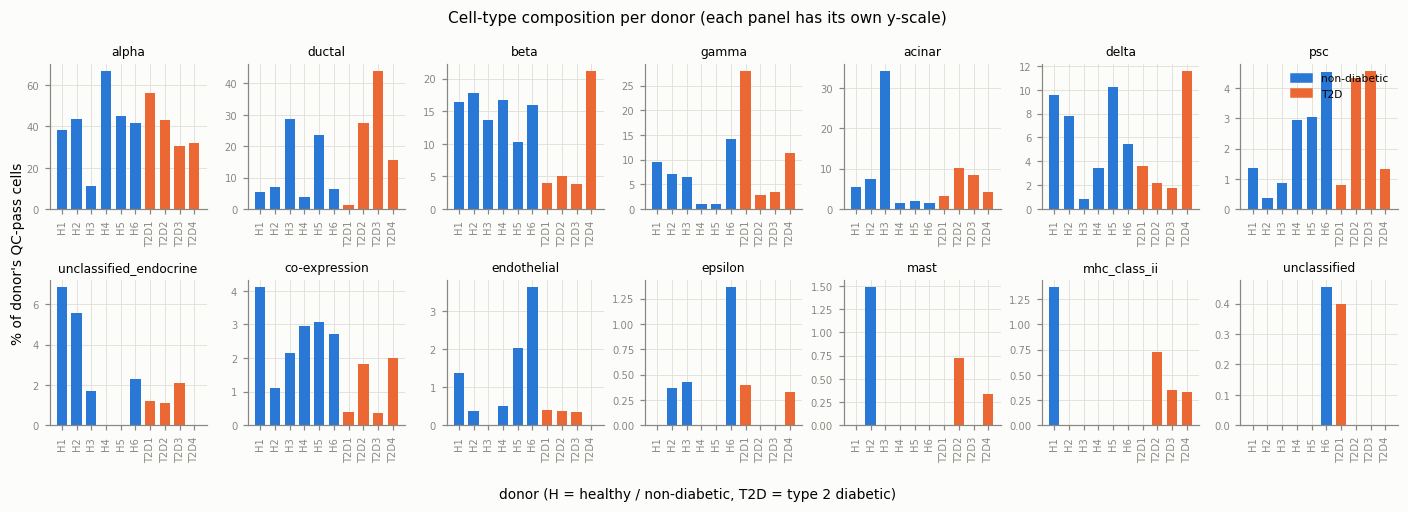

donor,H1,H2,H3,H4,H5,H6,T2D1,T2D2,T2D3,T2D4
condition,non-diabetic,non-diabetic,non-diabetic,non-diabetic,non-diabetic,non-diabetic,T2D,T2D,T2D,T2D
sex,male,male,female,male,male,male,male,female,male,female
age,43,25,48,22,27,23,57,37,52,55
bmi,30.8,24.7,35.0,32.9,31.8,21.5,24.0,39.6,34.4,29.8
clinical_info,HbA1c 5.0%,HbA1c 5.3%,HbA1c 5.7%,HbA1c 5.4%,not available,HbA1c 5.5%,HbA1c 7.0%,HbA1c 7.3%,HbA1c 7.7%,HbA1c 7.4%
n_wells,96,352,383,383,383,383,383,383,384,384
n_qc_pass,73,269,234,203,98,220,250,276,284,302


In [10]:
# Cell-type composition per donor (fractions); small multiples per class, bars coloured by condition.
frac_d = xt_d.div(xt_d.sum(axis=0), axis=1) * 100
ncol = 7
fig, axes = plt.subplots(int(np.ceil(len(frac_d) / ncol)), ncol, figsize=(13, 4.6))
for ax, t in zip(axes.ravel(), frac_d.index):
    ax.bar(range(len(DONOR_ORDER_D)), frac_d.loc[t].to_numpy(), width=0.7,
           color=[COND_COLOR[donor_meta_d.loc[d, "condition"]] for d in DONOR_ORDER_D])
    ax.set_title(t, fontsize=8)
    ax.set_xticks(range(len(DONOR_ORDER_D)), DONOR_ORDER_D, rotation=90)
    ax.tick_params(labelsize=6.5)
for ax in axes.ravel()[len(frac_d):]:
    ax.axis("off")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in COND_COLOR.values()]
axes.ravel()[ncol - 1].legend(handles, COND_COLOR.keys(), fontsize=7, loc="upper right")
fig.supxlabel("donor (H = healthy / non-diabetic, T2D = type 2 diabetic)", fontsize=9)
fig.supylabel("% of donor's QC-pass cells", fontsize=9)
fig.suptitle("Cell-type composition per donor (each panel has its own y-scale)", fontsize=10)
fig.tight_layout(); plt.show()
display(donor_meta_d.drop(columns="_k").loc[DONOR_ORDER_D].T)

**Label observations**
* **Every one of the 2,209 QC-pass wells has a label, and no other well has one.** The author label and the
  author QC verdict are therefore the same split; `author_qc_pass` is the natural cell filter (D.4).
* **14 author labels, 11 of them real cell types:** alpha 886 (40%), ductal 386, beta 270, gamma 197, acinar 185,
  delta 114, PSC (pancreatic stellate) 54, endothelial 16, epsilon 7, mast 7, MHC class II 5, plus three
  "uncertain" labels: `unclassified_endocrine` 41, `co-expression` 39 and `unclassified` 2. Imbalance is 443×,
  the largest so far (Baron 361×). This is the **richest class set after Baron**, and the only one besides Baron
  with immune cells (mast, MHC class II).
* **Alpha cells are the majority**, as in Xin, whereas beta cells were in Baron; beta cells are only 12% here.
* **10 donors (6 non-diabetic, 4 T2D)** with 73–302 QC-pass cells each; the condition groups are balanced (1,097
  ND / 1,112 T2D cells).
* **Composition differs strongly between donors**: 80 of the 185 acinar cells come from H3, 125 of the 386 ductal
  cells from T2D3 and 70 of the 197 gamma cells from T2D1. Beta cells are clearly rarer in T2D donors (99 of 1,112
  T2D cells vs 171 of 1,097 ND cells), which the figure shows for T2D1–T2D3, with T2D4 as the exception. So the
  condition shift here also changes the class prior.
* Classes below the 20-cell minimum proposed in `data_preview.ipynb`: endothelial (16), epsilon (7), mast (7),
  MHC class II (5) and `unclassified` (2).

## D.4 Per-cell quality metrics: library size, detected genes, spike-in share
Smart-seq2 gives **read counts** (not UMIs) together with RPKM. Library size here is the number of reads assigned to
genes (spike-ins and eGFP excluded). Like Muraro, the matrix is **unfiltered**: all 3,514 wells are deposited, and the
authors' verdict is in `quality`. This section therefore asks whether the authors' QC is visible in the data and
whether a simple shared rule would reproduce it.

In [11]:
X_d = seg.X
qc_d = pd.DataFrame({
    "total_counts": tot_cnt_d,
    "n_genes": np.asarray((X_d[:, bio_d] > 0).sum(1)).ravel(),
    "pct_ercc": 100 * np.asarray(X_d[:, ercc_d].sum(1)).ravel() / np.maximum(np.asarray(X_d.sum(1)).ravel(), 1e-9),
    "top_gene_frac": np.asarray(X_d[:, bio_d].max(1).todense()).ravel() / np.maximum(tot_cnt_d, 1e-9),
    "quality": seg.obs["quality"].to_numpy(), "donor": seg.obs["donor"].to_numpy(),
    "condition": seg.obs["condition"].to_numpy(), "cell_type": seg.obs["cell_type1"].to_numpy(),
}, index=seg.obs_names)
qc_d["lineage"] = qc_d["cell_type"].map(LINEAGE)
display(qc_d[["total_counts", "n_genes", "pct_ercc", "top_gene_frac"]].describe().round(3).T)
print("Medians by the authors' quality verdict:")
display(qc_d.groupby("quality")[["total_counts", "n_genes", "pct_ercc", "top_gene_frac"]].median().round(2)
        .assign(n_wells=qc_d.quality.value_counts()))
# Would the shared rule proposed for A/B/C (>= 500 genes, >= 1,000 counts) reproduce the authors' QC?
SHARED_D = (qc_d.n_genes >= 500) & (qc_d.total_counts >= 1000)
display(pd.crosstab(qc_d.quality, SHARED_D.rename("shared rule").map({True: "passes >=500 genes & >=1k counts", False: "fails"}), margins=True))
thr = [0, 500, 1000, 2000, 3000, 5000]
display(pd.DataFrame({"wells with >= t genes": [(qc_d.n_genes >= t).sum() for t in thr],
                      "... of which author OK": [((qc_d.n_genes >= t) & PASS_D).sum() for t in thr]}, index=thr).T)

,count,mean,std,min,25%,50%,75%,max
total_counts,3514.0,312699.031,443892.312,22.000,6304.500,173297.000,418073.250,5168369.000
n_genes,3514.0,4497.367,2945.950,18.000,1262.000,4940.000,7059.500,12216.000
pct_ercc,3514.0,14.466,28.604,0.000,0.409,0.743,3.138,99.158
top_gene_frac,3514.0,0.154,0.130,0.006,0.061,0.121,0.209,0.784


Medians by the authors' quality verdict:


,total_counts,n_genes,pct_ercc,top_gene_frac,n_wells
quality,,,,,
OK,323058.0,6553.0,0.520000,0.12,2209
"control, 2-cell well",196468.5,5612.0,0.670000,0.08,32
"control, empty well",821.0,460.5,69.339996,0.11,96
low quality cell,2533.0,805.0,20.250000,0.12,1177


shared rule,fails,passes >=500 genes & >=1k counts,All
quality,,,
OK,0,2209,2209
"control, 2-cell well",6,26,32
"control, empty well",60,36,96
low quality cell,413,764,1177
All,479,3035,3514


,0,500,1000,2000,3000,5000
wells with >= t genes,3514,3087,2744,2487,2310,1741
... of which author OK,2209,2209,2209,2164,2089,1626


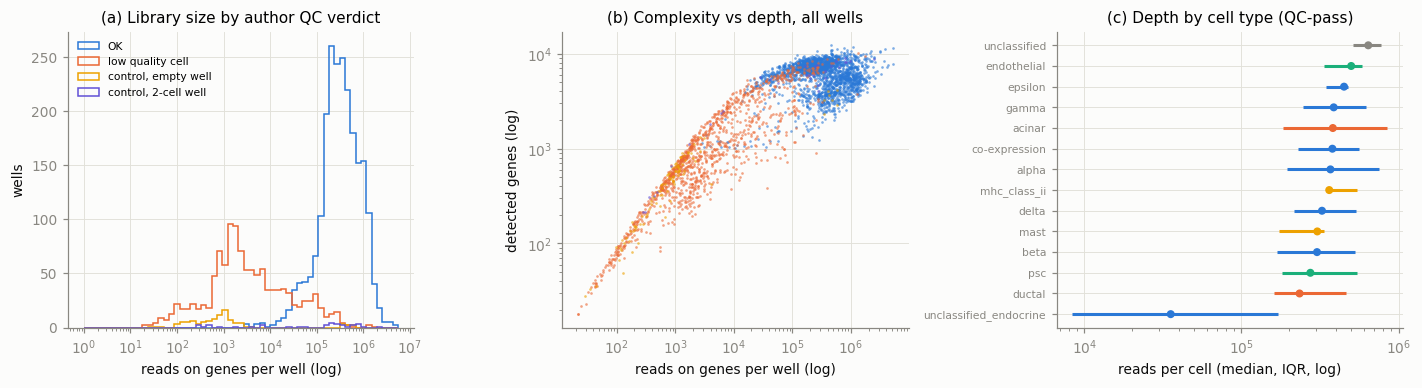

QC-pass cells: minimum reads / detected genes: 2889 / 1024
Author-QC pass rate per donor (%): {'H1': 76.0, 'H2': 76.4, 'H3': 61.1, 'H4': 53.0, 'H5': 25.6, 'H6': 57.4, 'T2D1': 65.3, 'T2D2': 72.1, 'T2D3': 74.0, 'T2D4': 78.6}
Median reads per donor (QC-pass): {'H1': 722106.0, 'H2': 897573.0, 'H3': 248810.0, 'H4': 194418.0, 'H5': 132219.0, 'H6': 367882.0, 'T2D1': 754442.0, 'T2D2': 380740.0, 'T2D3': 184526.0, 'T2D4': 304398.0}
Median detected genes by condition (QC-pass): {'T2D': 6923.0, 'non-diabetic': 5374.0}
Median top-gene fraction by type (QC-pass):
 cell_type
delta                     0.311
alpha                     0.165
gamma                     0.162
unclassified_endocrine    0.160
co-expression             0.102
beta                      0.097
acinar                    0.097
epsilon                   0.050
mhc_class_ii              0.040
unclassified              0.036
psc                       0.025
endothelial               0.025
mast                      0.023
ductal           

In [12]:
QUAL_COLOR = {"OK": PALETTE[0], "low quality cell": PALETTE[1], "control, empty well": PALETTE[3], "control, 2-cell well": PALETTE[6]}
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
# (a) library-size distribution per author-QC verdict (log x-axis)
bins = np.logspace(0, np.log10(qc_d.total_counts.max() * 1.1), 60)
for q_, c in QUAL_COLOR.items():
    axes[0].hist(qc_d.loc[qc_d.quality == q_, "total_counts"].clip(lower=1), bins=bins, histtype="step", lw=1.5, color=c, label=q_)
axes[0].set_xscale("log"); axes[0].set_xlabel("reads on genes per well (log)"); axes[0].set_ylabel("wells")
axes[0].set_title("(a) Library size by author QC verdict"); axes[0].legend(fontsize=7)
# (b) detected genes vs reads, coloured by author QC verdict
for q_, c in QUAL_COLOR.items():
    s = qc_d.quality == q_
    axes[1].scatter(qc_d.total_counts[s].clip(lower=1), qc_d.n_genes[s].clip(lower=1), s=3, alpha=0.6, color=c, label=q_, linewidths=0)
axes[1].set_xscale("log"); axes[1].set_yscale("log")
axes[1].set_xlabel("reads on genes per well (log)"); axes[1].set_ylabel("detected genes (log)")
axes[1].set_title("(b) Complexity vs depth, all wells")
# (c) library size per cell type (QC-pass cells, median and IQR), coloured by lineage
q = qc_d[PASS_D]
g = q.groupby("cell_type")["total_counts"]
order = g.median().sort_values().index
med, q1, q3 = g.median()[order], g.quantile(.25)[order], g.quantile(.75)[order]
y = np.arange(len(order)); cols = [LINEAGE_COLOR[LINEAGE[t]] for t in order]
axes[2].hlines(y, q1, q3, color=cols, lw=2); axes[2].scatter(med, y, color=cols, s=18, zorder=3)
axes[2].set_yticks(y, order, fontsize=7); axes[2].set_xscale("log"); axes[2].set_xlabel("reads per cell (median, IQR, log)")
axes[2].set_title("(c) Depth by cell type (QC-pass)")
fig.tight_layout(); plt.show()

print("QC-pass cells: minimum reads / detected genes:", int(q.total_counts.min()), "/", int(q.n_genes.min()))
print("Author-QC pass rate per donor (%):", (seg.obs.groupby("donor").author_qc_pass.mean() * 100).round(1)[DONOR_ORDER_D].to_dict())
print("Median reads per donor (QC-pass):", q.groupby("donor").total_counts.median().round(0)[DONOR_ORDER_D].to_dict())
print("Median detected genes by condition (QC-pass):", q.groupby("condition").n_genes.median().to_dict())
print("Median top-gene fraction by type (QC-pass):\n", q.groupby("cell_type").top_gene_frac.median().sort_values(ascending=False).round(3).to_string())

**QC observations**
* **The matrix is unfiltered, but the authors' QC verdict is in the SDRF and is clearly visible in the data.** In (a)
  the OK wells form one mode at about 10⁵–10⁶ reads (median 323k reads, 6,553 genes), the "low quality" wells a
  broad mode around 10³ reads (median 2,533 reads, 805 genes), and the empty-well controls sit at about 800 reads
  with 69% of their reads on ERCC. In (b) the OK wells form a tight band at high depth and complexity.
* **The shared rule (≥ 500 genes, ≥ 1,000 counts) does not reproduce the authors' QC.** It keeps all 2,209 OK wells,
  but also **764 of the 1,177 low-quality wells, 36 of the 96 empty wells and 26 of the 32 two-cell wells**. No
  single gene threshold separates them either: ≥ 2,000 genes keeps 2,487 wells, of which only 2,164 are OK. The
  authors must have used more than depth and complexity. Note that the empty-well controls are not empty in reads:
  Smart-seq2 picks up enough ambient RNA in an empty well to pass a 500-gene threshold in a third of them.
* **The 32 two-cell control wells are a built-in doublet test set**: they look like good single cells (median 196k
  reads, 5,612 genes, i.e. not more complex than singles), so a depth/complexity rule cannot catch them.
* **Pass rates differ by donor**: H5 has only 25.6% OK wells, the others 53–79%. Among OK cells, depth differs
  almost 7-fold between donors (median 132k reads for H5 to 898k for H2). T2D cells are *more* complex than ND cells
  (median 6,923 vs 5,374 genes), the opposite of Xin, which points to donor/plate effects rather than disease.
* **Depth by cell type** (c) varies much less than in Baron (medians 2.3–6.4 × 10⁵ reads), except for the 41
  `unclassified_endocrine` cells, which are much shallower (median 3.5 × 10⁴ reads). They are probably
  low-quality cells that still passed QC.
* **Hormone dominance is again strong**: the top gene takes 31% of a median delta cell's reads and 16–17% in alpha
  and gamma cells (Baron: 35% delta, 10% alpha).

## D.5 Gene-level behaviour: detection, top genes, mean–variance relationship
Computed on the 2,209 QC-pass cells and without spike-ins / eGFP, on read counts.

In [13]:
seg_g = seg[PASS_D, bio_d].copy()
print(f"QC-pass cells x biological genes: {seg_g.n_obs} x {seg_g.n_vars}")
n_expr_d, mean_d, var_d = gene_level(seg_g, "reads")

QC-pass cells x biological genes: 2209 x 26178
Genes detected in at most k cells:
  <=  0 cells:  3354  (12.8%)
  <=  2 cells:  5196  (19.8%)
  <=  9 cells:  7285  (27.8%)
  <= 19 cells:  8591  (32.8%)
  <= 49 cells: 10352  (39.5%)

Top-15 genes by share of all reads (%):
GCG       8.30
TTR       3.45
MALAT1    3.29
SST       1.83
PPY       1.80
INS       1.51
REG1A     1.04
CHGB      1.00
B2M       0.93
FTL       0.60
CLU       0.47
PRSS1     0.45
SCG5      0.34
REG3A     0.32
PSAP      0.30


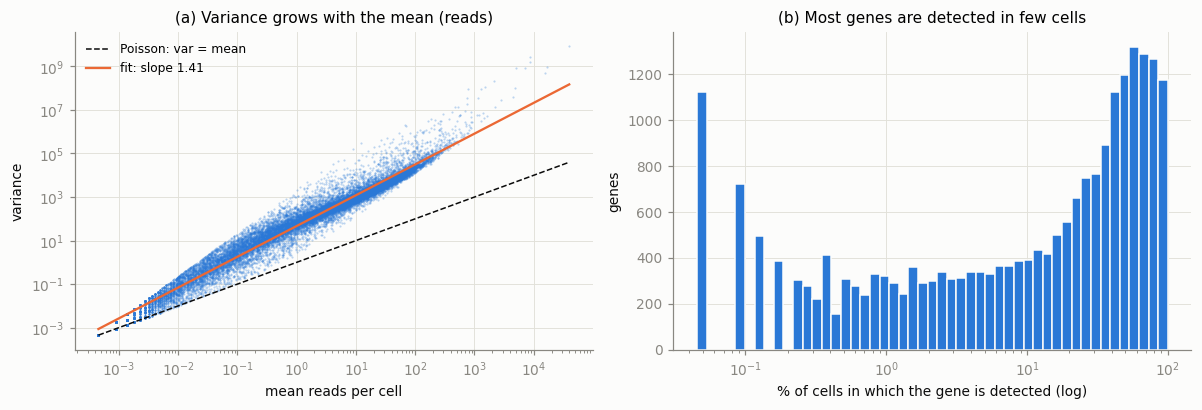

Fitted log-log slope of variance vs mean: 1.41


In [14]:
slope_d = plot_gene_level(n_expr_d, mean_d, var_d, seg_g.n_obs, "reads")
print(f"Fitted log-log slope of variance vs mean: {slope_d:.2f}")

**Gene-level observations** (2,209 QC-pass cells, 26,178 genes)
* **Variance grows faster than the mean (log-log slope 1.41)**, between Baron's UMI counts (≈ 1.1) and Xin's RPKM
  (≈ 1.5). Full-length read counts carry PCR-amplification noise that UMIs remove, so log1p (or another
  variance-stabilising step) matters more here than for Baron.
* **Top genes:** GCG takes 8.3% of all reads (alpha cells are the majority), then TTR, MALAT1, SST, PPY, INS, REG1A
  and CHGB. INS is only 1.5% (Baron 5.3%), partly because beta cells are only 12% of the cells.
* **Detection is far more sensitive than in the UMI datasets.** Panel (b) has its mode at genes detected in about
  50–80% of cells, whereas for Baron most genes are detected in few cells. Still, 12.8% of genes are never seen, 27.8%
  in fewer than 10 cells and 39.5% in fewer than 50, much of it the duplicated/merged RefSeq rows of D.2.

## D.6 Labels vs markers, and how "clean" are the markers?
Same marker panel as for Baron, plus the independent endocrine markers used for Xin (IRX2/ARX alpha, MAFA beta, HHEX
delta, CHGA pan-endocrine), on the QC-pass cells grouped by author label, followed by the independent check panel of
C.6 for the non-endocrine labels. Then the hormone-purity check from B.6, with GHRL added because Segerstolpe has
epsilon cells, and a look at the authors' `co-expression` and `unclassified_endocrine` cells.

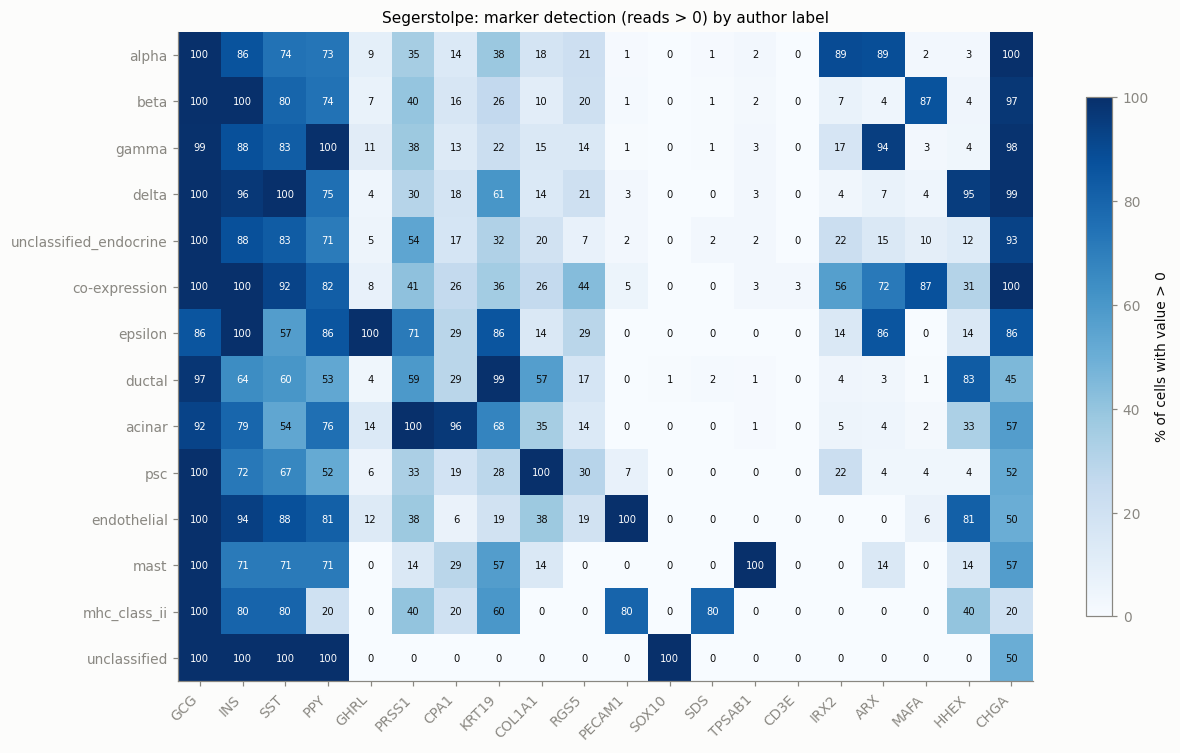

Panel markers not present (exactly once) in this dataset: []


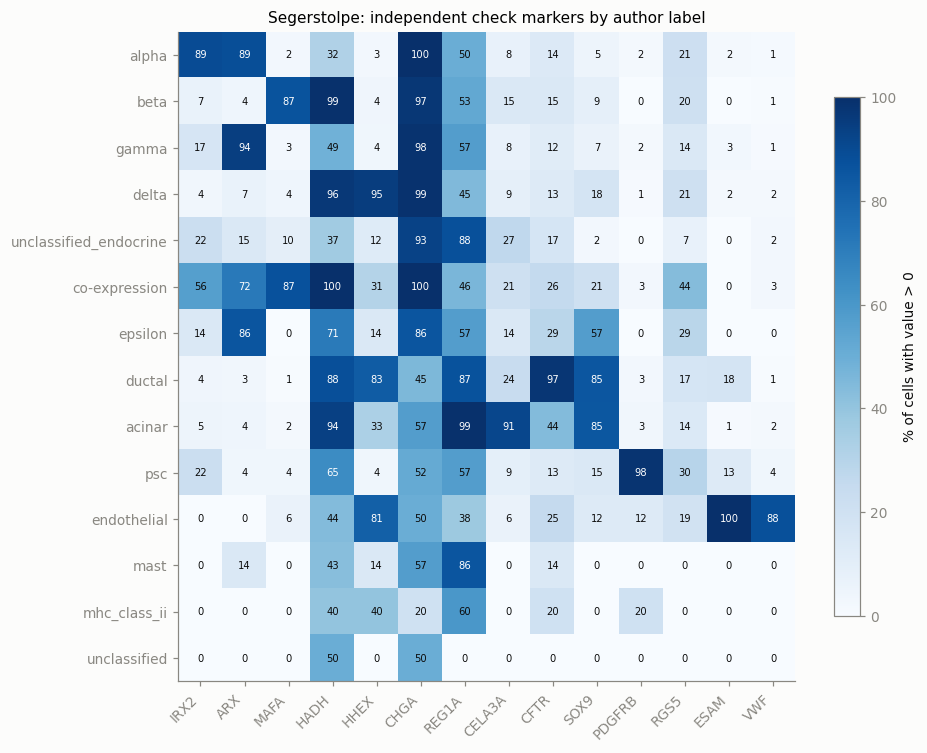

In [15]:
order_d = type_order(ct_d)
detect_d = detection_heatmap(seg_g, list(MARKERS.values()) + EXTRA_ENDOCRINE, ct_d, order_d,
                             "Segerstolpe: marker detection (reads > 0) by author label")
missing = [g for g in dict.fromkeys(list(MARKERS.values()) + EXTRA_ENDOCRINE + CHECK) if (seg_g.var["symbol"] == g).sum() != 1]
print("Panel markers not present (exactly once) in this dataset:", missing)
check_d = detection_heatmap(seg_g, CHECK, ct_d, order_d, "Segerstolpe: independent check markers by author label")

In [16]:
HORMONE_D = {"alpha": "GCG", "beta": "INS", "delta": "SST", "gamma": "PPY", "epsilon": "GHRL"}
endo_d = [t for t in order_d if LINEAGE[t] == "endocrine"]
purity_d, top_h_d, mixed_d = hormone_purity(seg_g, ct_d, HORMONE_D, endo_d)
display(purity_d)
hormone_types = list(HORMONE_D)
lab_is_h = ct_d.isin(hormone_types).to_numpy()
print("Hormone-labelled cells:", int(lab_is_h.sum()), "| label != top hormone:", int((top_h_d != ct_d)[lab_is_h].sum()),
      "| 'mixed' (second hormone within 20%):", int(mixed_d[lab_is_h].sum()))
print("\nTop hormone of the 'co-expression' and 'unclassified_endocrine' cells:")
display(pd.crosstab(ct_d[ct_d.isin(["co-expression", "unclassified_endocrine"])],
                    top_h_d[ct_d.isin(["co-expression", "unclassified_endocrine"])].rename("top hormone")))

,n_cells,top hormone = label,top hormone != label,two hormones high (mixed)
alpha,886,875,11,18
beta,270,269,1,0
gamma,197,197,0,1
delta,114,114,0,2
unclassified_endocrine,41,0,41,10
co-expression,39,0,39,35
epsilon,7,7,0,0


Hormone-labelled cells: 1474 | label != top hormone: 12 | 'mixed' (second hormone within 20%): 21

Top hormone of the 'co-expression' and 'unclassified_endocrine' cells:


top hormone,alpha,beta,delta,epsilon,gamma
cell_type1,,,,,
co-expression,12,19,8,0,0
unclassified_endocrine,19,12,5,1,4


**Marker observations**
* **The author labels are biologically consistent.** On the independent panel: IRX2/ARX in 89% of alpha, MAFA in
  87% of beta, HHEX in 95% of delta, ARX in 94% of gamma (expected biology, as in Xin), GHRL in 100% of epsilon,
  KRT19/CFTR/SOX9 in 99/97/85% of ductal, PRSS1/CPA1/CELA3A in 100/96/91% of acinar, COL1A1/PDGFRB in 100/98% of
  PSC, PECAM1/ESAM/VWF in 100/100/88% of endothelial cells and TPSAB1 in 100% of mast cells. The 5 `mhc_class_ii`
  cells express SDS and PECAM1 (80% each), i.e. they look like Baron's macrophages, and the 2 `unclassified` cells
  express SOX10 (both), i.e. they look like Schwann cells.
* **Hormone purity is high:** for 1,462 of the 1,474 hormone-labelled cells (alpha, beta, gamma, delta, epsilon)
  the dominant hormone matches the label; 11 of the 12 mismatches are alpha cells, and 21 cells have a second
  hormone within 20% of the first.
* **The "uncertain" endocrine labels are what their names say.** 35 of the 39 `co-expression` cells have two
  hormones at nearly the same level (their dominant hormone is beta 19, alpha 12, delta 8), and they co-express
  ARX (72%) and MAFA (87%). They are either doublets or genuinely polyhormonal cells; the data alone cannot tell. The
  41 `unclassified_endocrine` cells have mixed dominant hormones (alpha 19, beta 12, delta 5, gamma 4, epsilon 1)
  and, as D.4 showed, low depth.
* **The ambient hormone signal is the broadest of all datasets so far.** GCG is detected in 92–100% of cells of
  every type (86% of the 7 epsilon cells), INS in 64–100%, SST in 54–100% and even PPY in 52–100% (except the 5 MHC class II cells). Baron had
  INS everywhere, Xin GCG everywhere, and Muraro GCG + SST everywhere. Read-based detection (a single read
  suffices, no UMI) and full-length coverage make Smart-seq2 the most sensitive to ambient RNA, so "presence of a
  hormone" is useless as a feature here and only its level separates types. This is a further distinct ambient
  profile for the shift descriptor (E6).

## D.7 Global structure: do cells group by type, by donor or by condition?
Same throw-away pipeline as for Baron (normalise to 10k → log1p → 2,000 HVGs → z-score → PCA), on the read counts
of the QC-pass cells. Because D is the only dataset with **both** counts and RPKM, the same pipeline is also run on
RPKM to see whether the choice of deposited unit changes the picture. Inspection only.

In [17]:
P_d, evr_d, load_d = throwaway_pca(seg_g)
sil_type_d = silhouette_score(P_d[:, :20], ct_d, random_state=SEED)
sil_donor_d = silhouette_score(P_d[:, :20], donor_d, random_state=SEED)
sil_cond_d = silhouette_score(P_d[:, :20], cond_d, random_state=SEED)
print(f"\nSilhouette by cell type: {sil_type_d:.3f}   by donor: {sil_donor_d:.3f}   by condition: {sil_cond_d:.3f}")
within_dd = {t: silhouette_score(P_d[(ct_d == t).to_numpy(), :20], donor_d[(ct_d == t).to_numpy()]) for t in ["alpha", "beta", "ductal", "acinar"]}
within_dc = {t: silhouette_score(P_d[(ct_d == t).to_numpy(), :20], cond_d[(ct_d == t).to_numpy()]) for t in ["alpha", "beta", "ductal", "acinar"]}
print("Silhouette *within* one cell type, by donor:", {k: round(v, 3) for k, v in within_dd.items()})
print("                                  by condition:", {k: round(v, 3) for k, v in within_dc.items()})
for pc in load_d:
    print(f"{pc} top +: {load_d[pc].nlargest(8).index.tolist()}\n    top -: {load_d[pc].nsmallest(8).index.tolist()}")

print("\nSame pipeline on the RPKM layer:")
seg_r = seg_g.copy(); seg_r.X = seg_r.layers["rpkm"].copy()
P_dr, evr_dr, _ = throwaway_pca(seg_r)
print(f"Silhouette by cell type (RPKM): {silhouette_score(P_dr[:, :20], ct_d, random_state=SEED):.3f}   "
      f"by donor: {silhouette_score(P_dr[:, :20], donor_d, random_state=SEED):.3f}")
del seg_r

Explained variance, PC1..PC10 (%): [9.4 6.5 3.5 2.6 1.9 1.8 1.4 1.3 1.2 1. ]
Cumulative variance in 20 / 50 PCs: 36.4% / 43.8%



Silhouette by cell type: 0.304   by donor: -0.103   by condition: 0.028
Silhouette *within* one cell type, by donor: {'alpha': 0.049, 'beta': 0.149, 'ductal': -0.035, 'acinar': 0.008}
                                  by condition: {'alpha': 0.077, 'beta': 0.23, 'ductal': 0.092, 'acinar': 0.129}
PC1 top +: ['IFITM3', 'LGALS3', 'SERPING1', 'TACSTD2', 'CDC42EP1', 'ZFP36L1', 'KRT7', 'CTSH']
    top -: ['MIR7-3HG', 'GNG4', 'CRYBA2', 'HEPACAM2', 'MLXIPL', 'G6PC2', 'CAMK2B', 'SH3GL2']
PC2 top +: ['SPARC', 'COL1A2', 'BGN', 'COL3A1', 'PDGFRB', 'COL6A3', 'COL5A1', 'NID1']
    top -: ['KRT18', 'TACSTD2', 'CFB', 'PRSS8', 'CLDN4', 'SDC4', 'KRT7', 'ANXA4']

Same pipeline on the RPKM layer:


Explained variance, PC1..PC10 (%): [8.9 6.  3.2 2.5 1.7 1.5 1.3 1.2 1.  0.9]
Cumulative variance in 20 / 50 PCs: 33.6% / 41.3%
Silhouette by cell type (RPKM): 0.191   by donor: -0.105


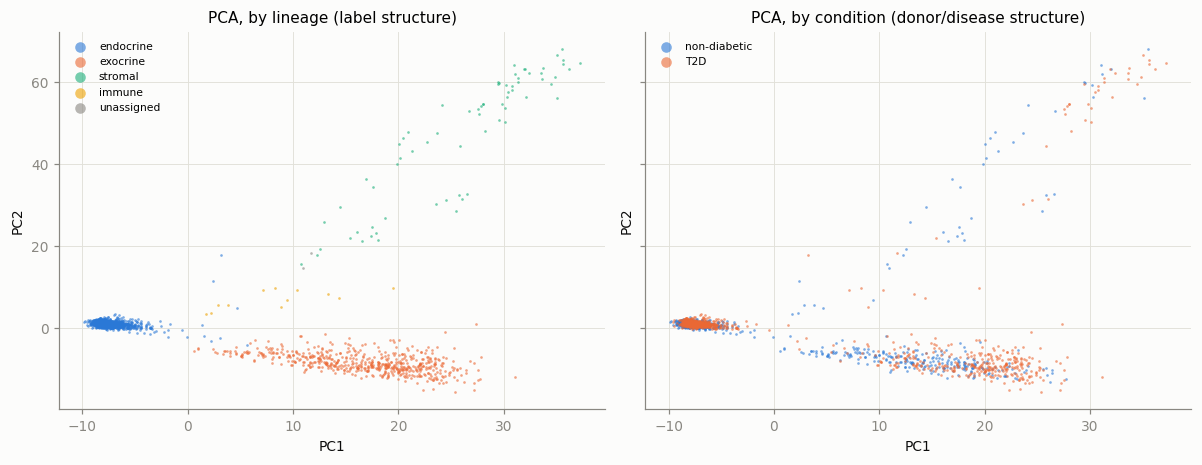

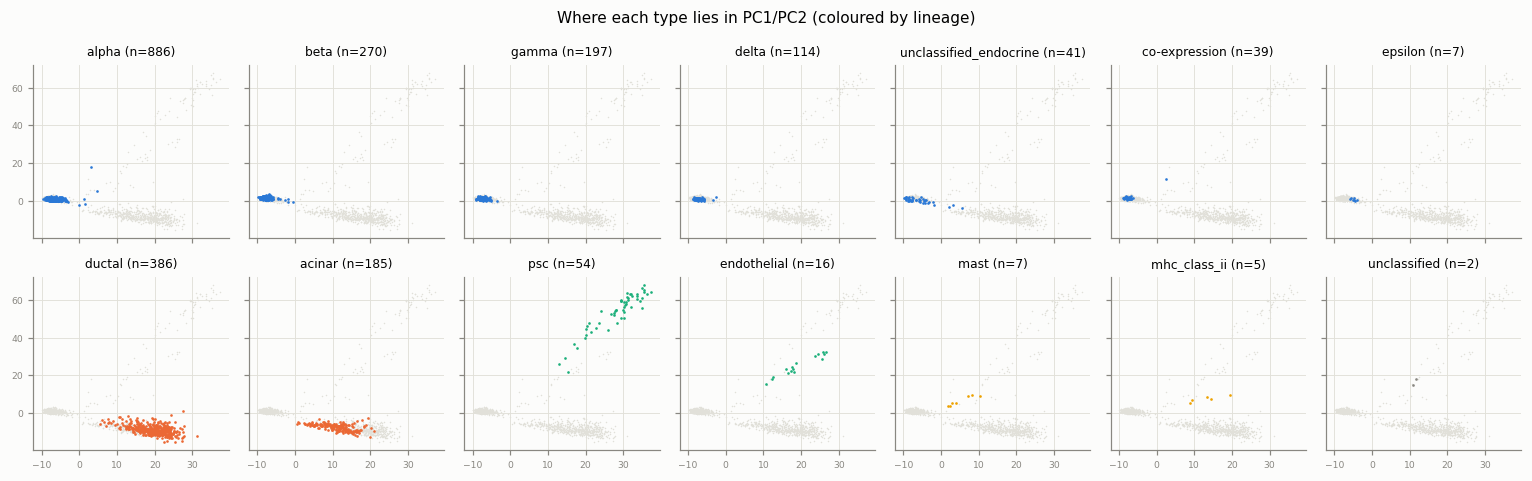

In [18]:
rng = np.random.default_rng(SEED)
perm_d = rng.permutation(seg_g.n_obs)        # random draw order so no group is always painted on top
lin_d = ct_d.map(LINEAGE).to_numpy()
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3), sharex=True, sharey=True)
scatter_groups(axes[0], P_d, lin_d, LINEAGE_COLOR, "PCA, by lineage (label structure)", perm_d)
scatter_groups(axes[1], P_d, cond_d, COND_COLOR, "PCA, by condition (donor/disease structure)", perm_d)
fig.tight_layout(); plt.show()

fig, axes = plt.subplots(2, 7, figsize=(14, 4.4), sharex=True, sharey=True)
for ax, t in zip(axes.ravel(), order_d):
    s = (ct_d == t).to_numpy()
    ax.scatter(P_d[~s, 0], P_d[~s, 1], s=1, color=GRID, linewidths=0)
    ax.scatter(P_d[s, 0], P_d[s, 1], s=3, color=LINEAGE_COLOR[LINEAGE[t]], linewidths=0)
    ax.set_title(f"{t} (n={s.sum()})", fontsize=8); ax.tick_params(labelsize=6)
for ax in axes.ravel()[len(order_d):]:
    ax.axis("off")
fig.suptitle("Where each type lies in PC1/PC2 (coloured by lineage)", fontsize=10)
fig.tight_layout(); plt.show()

**Structure observations**
* **Cell type dominates, donor does not** (silhouette 0.30 by type, −0.10 by donor, 0.03 by condition), very close
  to Baron (0.31 / 0.05). PC1 (9.4%) separates endocrine (MIR7-3HG, GNG4, G6PC2) from non-endocrine cells (IFITM3,
  LGALS3, KRT7); PC2 (6.5%) separates the stromal arm (SPARC, COL1A2, PDGFRB) from the exocrine arm (KRT18/7,
  CLDN4). Mast and MHC class II cells lie between the arms; the endocrine types overlap in PC1/PC2, as in Baron.
* **Within a cell type the donor effect is small** (alpha 0.05, beta 0.15, ductal −0.04, acinar 0.01; Baron
  0.12–0.17), **but the condition effect within beta cells is the largest so far (0.23)**, also visible for acinar
  (0.13). With only 4 T2D donors this cannot be separated from donor identity, but it suggests that an ND → T2D
  split in D is a real expression shift and not only a composition shift.
* 20 PCs hold 36.4% of the variance, more than Baron (30%) and far more than Xin (14%).
* **RPKM is the worse input:** the same pipeline on the RPKM layer gives a type silhouette of 0.19 instead of 0.30
  (donor −0.11). Gene-length normalisation adds noise for full-length data rather than removing it, which supports
  using the counts.

## D.8 Summary of the Segerstolpe inspection

| aspect | Segerstolpe (E-MTAB-5061) |
|---|---|
| wells × features | 3,514 × 26,271 (26,178 RefSeq genes + 92 ERCC + eGFP); 2,209 cells pass author QC |
| technology | Smart-seq2, full-length, FACS into 384-well plates, HiSeq 2000, single-end, no UMIs |
| values available | **raw read counts + RPKM** |
| labels | in the ArrayExpress SDRF (`inferred cell type`), only for QC-pass cells |
| missing values | none (HbA1c of H5 "not available") |
| prior QC | **no** in the matrix (all wells, incl. 96 empty and 32 two-cell controls), **yes** as an SDRF flag |
| MT genes | absent (no %MT QC); ERCC + eGFP present |
| classes | 14 labels = 11 types + 3 uncertain; alpha 886 … MHC class II 5, imbalance 443× |
| batch structure | 10 donors (6 ND / 4 T2D), 73–302 cells each, composition uneven, small expression effect |
| notable | broadest ambient hormone signal; duplicated/merged RefSeq rows; built-in doublet and empty-well controls |

## D.9 Proposed preprocessing for Segerstolpe (for discussion)
Same rules R1–R5 as in `data_preview.ipynb` Part 2; only what is specific to Segerstolpe is listed.

* **Step A — cell filtering (R4).** Use the **authors' QC flag** (`author_qc_pass`, 2,209 cells). The shared rule
  (≥ 500 genes, ≥ 1,000 counts) is satisfied by all of them, so it can still be applied as the common rule, but on
  its own it would keep 764 low-quality, 36 empty and 26 two-cell wells (D.4). Decision needed: is "shared rule
  **plus** author flag where one exists" acceptable under R4? (Muraro's author QC is the same kind of flag.) No %MT
  filter (no MT genes). Remove ERCC and eGFP after QC. The 32 two-cell wells can be kept aside as a labelled
  doublet set for the rejection analysis.
* **Step B — labels.** Keep the 11 real types. Exclude `co-expression` (39), `unclassified_endocrine` (41) and
  `unclassified` (2) from training and labelled evaluation (realistic "uncertain" query cells, like Camp's
  "Unknown"). Below 20 cells: endothelial 16, epsilon 7, mast 7, MHC class II 5 → rare/unseen pool, as for Baron.
  Harmonisation: `psc` ↔ Baron's two stellate states (parent node); `mhc_class_ii` ↔ `macrophage` (markers agree,
  D.6), to be confirmed.
* **Step C — genes (R2, R5).** Before intersecting: drop the `+`-joined rows, and sum (or drop) the rows that share a
  symbol. 18,936 symbols are shared with Baron (see the final section).
* **Step D — normalisation (R3).** `normalize_total` (10,000) + `log1p` on the **raw read counts**, exactly as for
  Baron; no deviation. RPKM is not used (D.7).
* **Role in the study:** the best **E2 partner for Baron** after Muraro: a different technology (Smart-seq2
  full-length reads vs inDrop 3' UMI) with most classes shared, including rare immune cells; in addition, **ND → T2D**
  is a condition-shift scenario with a visible beta-cell expression effect, and D → A tests Baron's T cells and
  Schwann cells as unseen types (E3).

---
# Dataset E — Lawlor et al. (GSE86469, human islets, Fluidigm C1 SMARTer)

## E.0 What is in the SOFT file, and conversion
The SOFT file was copied (not moved) from `~/Downloads/proj_data/` to `data/raw/lawlor_GSE86469/`.

In [19]:
gse_e = GEOparse.get_GEO(filepath=str(LAW_SOFT))
print("GEO accession:", gse_e.name, "|", gse_e.metadata["title"][0])
print("Platforms:", list(gse_e.gpls), "| number of samples (GSM):", len(gse_e.gsms))
print("Series supplementary files:", *gse_e.metadata["supplementary_file"], sep="\n  ")

meta_e = soft_samples(gse_e)
print("\nGSM tables with rows:", int((meta_e.table_rows > 0).sum()), "| GSM supplementary files:",
      meta_e.supplementary_file.value_counts().to_dict())
print("Characteristic keys:", [c for c in meta_e.columns if c not in
      ("title", "description", "platform", "source", "table_rows", "supplementary_file")])
print("\ndata_processing (identical for every GSM):")
for line in next(iter(gse_e.gsms.values())).metadata["data_processing"]:
    print("  *", line[:700] + (" ..." if len(line) > 700 else ""))
meta_e.head(3)

GEO accession: GSE86469 | Single cell transcriptomics defines human islet cell signatures and reveals cell-type-specific expression changes in type 2 diabetes [single cell]
Platforms: ['GPL18573'] | number of samples (GSM): 638
Series supplementary files:
  ftp://ftp.ncbi.nlm.nih.gov/geo/series/GSE86nnn/GSE86469/suppl/GSE86469_GEO.islet.single.cell.processed.data.RSEM.raw.expected.counts.csv.gz

GSM tables with rows: 0 | GSM supplementary files: {'NONE': 638}
Characteristic keys: ['cell type', 'tissue', 'Sex', 'disease', 'age', 'race', 'bmi', 'islet unos id']

data_processing (identical for every GSM):
  * Sequencing, Read Mapping, and Quality Control. All sequencing was performed on a NextSeq500 (Illumina) using the 75 cycle high output chip. RNA-seq reads were subjected to quality control using custom scripts developed at the computational sciences group at The Jackson Laboratory. Briefly, reads with more than 30% of bases with quality scores were removed from the analysis and sample

,title,description,platform,source,table_rows,supplementary_file,cell type,tissue,Sex,disease,age,race,bmi,islet unos id
GSM2303146,10th_C10_S104,,GPL18573,Pancreatic Islet,0,NONE,None/Other,Pancreatic Islet,Female,Type 2 Diabetic,55,White,29.8,ACIW009
GSM2303147,10th_C11_S96,,GPL18573,Pancreatic Islet,0,NONE,Beta,Pancreatic Islet,Female,Type 2 Diabetic,55,White,29.8,ACIW009
GSM2303148,10th_C13_S61,,GPL18573,Pancreatic Islet,0,NONE,Beta,Pancreatic Islet,Female,Type 2 Diabetic,55,White,29.8,ACIW009


**What the SOFT file contains.** Like Xin, **one GSM per cell** (638 GSMs, Fluidigm C1, one SRA run each), all GSM
tables empty and no GSM supplementary files. The characteristics carry the full per-cell metadata: **author label
(`cell type`), donor (`islet unos id`), disease (non-diabetic / type 2 diabetic), age, sex, race and BMI**, so the
labels come straight from GEO. The GSM titles (`10th_C10_S104` = C1 run, capture site, sample number) are the column
names of the matrix. Platform GPL18573 = Illumina NextSeq 500.

The `data_processing` text matters for what the labels mean: 978 cells passed read QC; **72 with fewer than 3,500
genes (≥ 5 TPM) were removed, and so were the 340 cells (35%) that expressed more than one of seven marker genes**
(INS, GCG, SST, PPY, KRT19, PRSS1, COL1A1), as presumed doublets. Each remaining cell was labelled by which single
marker a per-gene Gaussian mixture called "expressed". So the deposited data are pre-filtered and **the labels are
defined by seven markers**.

The expression matrix is the single series supplementary file
`GSE86469_GEO.islet.single.cell.processed.data.RSEM.raw.expected.counts.csv.gz` (12.7 MB), downloaded from the GEO
FTP site into `data/raw/lawlor_GSE86469/`. **The SOFT and the file disagree about its content**: `data_processing`
says "raw transcript per million (TPM) values", while the file name says "RSEM raw expected counts". E.1 checks this
on the values, and **the file holds RSEM expected counts, not TPM**.

Rows are **Ensembl gene IDs** (GRCh37, Ensembl v70) without symbols. Mapping them through NCBI `gene_info` (as was
done for Xin's Entrez IDs) resolved only 79% of IDs and none of the 13 mitochondrial genes, so instead the
**Ensembl release-70 GTF itself** (`Homo_sapiens.GRCh37.70.gtf.gz`, the exact release the authors used) was
downloaded from ftp.ensembl.org into `data/raw/ensembl_GRCh37_v70/`; every ID resolves. The conversion follows the
Xin route: cells × genes, `X` = the deposited assay, kept also as layer `expected_counts`, saved to
`data/interim/lawlor_human.h5ad`.

In [20]:
def build_lawlor():
    """GEO RSEM table (Ensembl genes x cells) + SOFT characteristics -> AnnData (cells x genes)."""
    tab = pd.read_csv(LAW_CSV, index_col=0)                                   # genes x cells
    print("Expression table (genes x cells):", tab.shape)

    # Cells: matrix column <-> GSM title (e.g. '10th_C10_S104'), checked one-to-one.
    m = meta_e.rename_axis("gsm").reset_index().set_index("title")
    assert m.index.is_unique and set(tab.columns) == set(m.index), "matrix columns and GSM titles do not match 1:1"
    o = (m.loc[tab.columns].rename(columns={"cell type": "cell_type1", "islet unos id": "donor", "Sex": "sex",
                                            "disease": "condition"}))
    o["condition"] = o["condition"].map({"Non-Diabetic": "non-diabetic", "Type 2 Diabetic": "T2D"})
    o["age"], o["bmi"] = o["age"].astype(int), o["bmi"].astype(float)
    o["c1_run"] = o.index.str.split(r"[_-]", regex=True).str[0]              # '10th' = 10th C1 chip run (title prefix)
    o = o[["gsm", "cell_type1", "donor", "condition", "age", "sex", "race", "bmi", "c1_run", "tissue", "platform"]]
    o.index = o.index.astype(str); o.index.name = "cell_id"

    # Genes: Ensembl gene IDs (GRCh37, Ensembl v70) -> gene name, biotype and chromosome from the Ensembl v70 GTF itself
    # (the release the authors mapped to), so every ID resolves and mitochondrial genes keep their 'MT-' names.
    gtf = pd.read_csv(ENS_GTF, sep="\t", header=None, comment="#", usecols=[0, 8], dtype=str)
    attr = gtf[8].str.extract(r'gene_id "([^"]+)".*gene_name "([^"]+)".*gene_biotype "([^"]+)"')
    ann = (pd.DataFrame({"ensembl_id": attr[0], "symbol": attr[1], "gene_type": attr[2], "chromosome": gtf[0]})
           .drop_duplicates("ensembl_id").set_index("ensembl_id"))
    var = ann.reindex(tab.index.astype(str)).rename_axis("ensembl_id").reset_index()
    print(f"Ensembl IDs found in the v70 GTF: {var.symbol.notna().sum()} of {len(var)}")
    assert var.symbol.notna().all()
    dup = var["symbol"].duplicated(keep=False)
    var.index = np.where(dup, var["symbol"] + "__" + var["ensembl_id"], var["symbol"])
    assert var.index.is_unique
    var.index.name = "gene_id"

    X = sp.csr_matrix(tab.to_numpy().T, dtype="float32")
    assert np.allclose(np.asarray(X.sum(1)).ravel(), tab.sum(axis=0).to_numpy(), rtol=1e-4), "conversion mismatch"
    print("Row sums of X match the GEO table column sums -> conversion is lossless (float32)")
    a = ad.AnnData(X=X, obs=o, var=var, layers={"expected_counts": X.copy()})
    a.uns["X_source_assay"] = "expected_counts"
    a.uns["source_files"] = [str(LAW_SOFT), str(LAW_CSV), str(ENS_GTF)]
    a.write_h5ad(LAW_H5, compression="gzip")
    print(f"-> {LAW_H5}: {a.n_obs} cells x {a.n_vars} genes")
    return a

law = build_lawlor()

Expression table (genes x cells): (26616, 638)


Ensembl IDs found in the v70 GTF: 26616 of 26616


Row sums of X match the GEO table column sums -> conversion is lossless (float32)


-> /home/professor/cell-type-annotaion-benchmark/data/interim/lawlor_human.h5ad: 638 cells x 26616 genes


## E.1 Overview of the Lawlor (GSE86469) object
The SOFT `data_processing` calls the values "raw TPM", the file name calls them "RSEM raw expected counts". The
per-cell totals and the integer fraction decide which it is.

In [21]:
print(law)
print("\nX is assay:", law.uns["X_source_assay"], "| dtype:", law.X.dtype, "| sparse:", sp.issparse(law.X))
print(f"Sparsity (fraction of zeros): {1 - law.X.nnz / np.prod(law.shape):.3f}")
tot_e = np.asarray(law.X.sum(1)).ravel()
print("Value range:", float(law.X.min()), "-", round(float(law.X.max()), 1),
      "| per-cell total:", pd.Series(tot_e).describe()[["min", "50%", "max"]].round(0).to_dict())
print(f"Non-zero entries that are integers: {np.mean(law.X.data == np.round(law.X.data)):.3f} | "
      f"all values rounded to 2 decimals: {np.allclose(law.X.data, np.round(law.X.data, 2), atol=1e-3)} | "
      f"smallest non-zero: {law.X.data.min():.2f}")
print(f"Cells whose total is within 1% of 1e6 (what TPM would give): {int((np.abs(tot_e - 1e6) < 1e4).sum())}")
print(f"Non-zero entries below 1 expected count: {np.mean(law.X.data < 1):.3f} | below 0.5: {np.mean(law.X.data < 0.5):.3f}")
print("Cells per C1 run:", law.obs.c1_run.value_counts().to_dict())
law.obs.head(3)

AnnData object with n_obs × n_vars = 638 × 26616
    obs: 'gsm', 'cell_type1', 'donor', 'condition', 'age', 'sex', 'race', 'bmi', 'c1_run', 'tissue', 'platform'
    var: 'ensembl_id', 'symbol', 'gene_type', 'chromosome'
    uns: 'X_source_assay', 'source_files'
    layers: 'expected_counts', None (.X)

X is assay: expected_counts | dtype: float32 | sparse: True
Sparsity (fraction of zeros): 0.687
Value range: 0.0 - 1453667.0 | per-cell total: {'min': 346163.0, '50%': 1502768.0, 'max': 3834270.0}
Non-zero entries that are integers: 0.399 | all values rounded to 2 decimals: True | smallest non-zero: 0.01
Cells whose total is within 1% of 1e6 (what TPM would give): 10
Non-zero entries below 1 expected count: 0.029 | below 0.5: 0.009
Cells per C1 run: {'4th': 57, '9th': 57, '12th': 57, '10th': 56, '7th': 55, '3rd': 53, '13th': 51, '2nd': 49, '6th': 48, '5th': 45, '8th': 39, '11th': 37, '1st': 34}


,gsm,cell_type1,donor,condition,age,sex,race,bmi,c1_run,tissue,platform
cell_id,,,,,,,,,,,
10th_C10_S104,GSM2303146,None/Other,ACIW009,T2D,55,Female,White,29.8,10th,Pancreatic Islet,GPL18573
10th_C11_S96,GSM2303147,Beta,ACIW009,T2D,55,Female,White,29.8,10th,Pancreatic Islet,GPL18573
10th_C13_S61,GSM2303148,Beta,ACIW009,T2D,55,Female,White,29.8,10th,Pancreatic Islet,GPL18573


**What we have:** 638 cells × 26,616 genes (protein-coding and lincRNA only), a single assay:

* **The values are RSEM expected counts, not TPM.** Per-cell totals range from 346k to 3.83M (median 1.50M); TPM
  would sum to about 10⁶ in every cell, and only 10 of 638 cells are within 1% of that. 40% of the non-zero values
  are integers and all are rounded to two decimals (smallest 0.01), which is how RSEM reports expected counts
  (reads shared between genes are split fractionally). Only 2.9% of non-zero entries are below 1. **The SOFT's
  "TPM" statement is wrong for this file; the file name is right.**
* So, unlike Xin (the other C1 dataset, RPKM only), **E is count-like and supports R3**, up to the fractional
  values.

68.7% of entries are zero, the least sparse dataset so far (C1 full-length data, and cells with < 3,500 genes were
removed). Cells come from 13 C1 runs (34–57 cells each). `obs` has the GSM, author label, donor, condition, age,
sex, race, BMI, C1 run, and two constant columns.

**Where the expression values live.** As for Segerstolpe: `law.X` is the cells × genes matrix (for Lawlor: RSEM expected counts), its columns are
named by `law.var_names`, and `law.obs` / `law.var` only describe its rows / columns. One example cell per type
against the marker genes:

In [ ]:
# Where the expression values live: law.X is the cells x genes matrix; its rows are named by law.obs_names (cells)
# and its columns by law.var_names (genes). law.obs / law.var describe those rows / columns and hold no expression.
print("X:", type(law.X).__name__, law.X.shape, "| holds:", law.uns["X_source_assay"],
      "| other versions in layers:", [k for k in law.layers.keys() if k is not None])   # None = X itself in this anndata
print("Gene names = column names of X (var_names):", list(law.var_names[:5]), "...")
print(f"Stored non-zero values: {law.X.nnz:,} of {np.prod(law.shape):,} entries")

# A small window into X: one example cell per type (rows) x the marker gene of each type (columns).
ex_types = ['Alpha', 'Beta', 'Delta', 'Gamma/PP', 'Acinar', 'Ductal']
ex_genes = ['GCG', 'INS', 'SST', 'PPY', 'PRSS1', 'KRT19']
ex_cells = [law.obs_names[law.obs["cell_type1"] == t][0] for t in ex_types]
ex_window = law[ex_cells, ex_genes].to_df()
ex_window.insert(0, "cell_type1", law.obs.loc[ex_cells, "cell_type1"].values)
ex_window

X: csr_matrix (638, 26616) | holds: expected_counts | other versions in layers: ['expected_counts']
Gene names = column names of X (var_names): ['LINC00362', 'RP11-632L2.1', 'SACS-AS1', 'LINC00327', 'LINC00352'] ...
Stored non-zero values: 5,307,880 of 16,981,008 entries


gene_id,cell_type1,GCG,INS,SST,PPY,PRSS1,KRT19
cell_id,,,,,,,
10th_C28_S91,Alpha,520845.0,0.0,0.0,0.0,0.000000,0.0
10th_C11_S96,Beta,343.0,33774.0,0.0,0.0,0.000000,0.0
10th_C76_S128,Delta,12.0,88.0,85728.0,0.0,45.950001,0.0
10th_C58_S111,Gamma/PP,9.0,1.0,1.0,26514.0,0.000000,0.0
10th_C42_S109,Acinar,11.0,1.0,0.0,0.0,15990.459961,0.0
10th_C24_S90,Ductal,59.0,1.0,0.0,0.0,0.000000,1403.0


## E.2 Data integrity and missing values
Same checklist. RSEM expected counts are fractional by construction (reads shared between genes are split by
probability), so "non-integer" is expected and not a defect.

In [22]:
display(integrity_checks(law, integer_expected=False))
constant_cols = [c for c in law.obs.columns if law.obs[c].nunique() == 1]
print(f"{len(constant_cols)} constant obs columns (no information):", constant_cols)
dup_e = law.var.symbol[law.var.symbol.duplicated(keep=False)]
print(f"Symbols shared by several Ensembl IDs: {dup_e.nunique()} (kept apart as '<symbol>__<ENSG>'), e.g. {dup_e.unique()[:5].tolist()}")

,count,expected
NaN/Inf in matrix,0,0
negative values,0,0
non-integer values,3188219,n/a (not counts)
NaN cells in obs,0,0
NaN cells in var,0,0
duplicated cell IDs,0,0
duplicated gene names,0,0
cells with zero total,0,0
genes detected in 0 cells,4162,-


2 constant obs columns (no information): ['tissue', 'platform']
Symbols shared by several Ensembl IDs: 120 (kept apart as '<symbol>__<ENSG>'), e.g. ['POTEB', 'IER3IP1', 'SOX7', 'SPECC1L', 'CSNK2B']


In [23]:
# Gene-name hygiene: mitochondrial / ribosomal / spike-in / odd names.
names_e = law.var["symbol"]
mt_e = (law.var["chromosome"] == "MT").to_numpy()
print("genes on chrM:          ", int(mt_e.sum()), list(names_e[mt_e]))
rib_e = names_e.str.match(r"^RP[LS]\d")
print("RPL/RPS ribosomal names:", int(rib_e.sum()), "| of which protein-coding:",
      int((rib_e & (law.var.gene_type == "protein_coding")).sum()))
print("names starting 'ERCC':  ", list(names_e[names_e.str.startswith("ERCC")][:10]))
print("gene types (Ensembl biotype):", law.var["gene_type"].value_counts().head(6).to_dict())
print("chromosomes:", law.var["chromosome"].value_counts().to_dict())

genes on chrM:           13 ['MT-ND1', 'MT-ND2', 'MT-CO1', 'MT-CO2', 'MT-ATP8', 'MT-ATP6', 'MT-CO3', 'MT-ND3', 'MT-ND4L', 'MT-ND4', 'MT-ND5', 'MT-ND6', 'MT-CYB']
RPL/RPS ribosomal names: 100 | of which protein-coding: 98
names starting 'ERCC':   ['ERCC6L', 'ERCC6', 'ERCC2', 'ERCC1', 'ERCC3', 'ERCC5', 'ERCC4', 'ERCC6L2', 'ERCC8']
gene types (Ensembl biotype): {'protein_coding': 20194, 'lincRNA': 5859, 'processed_transcript': 445, 'antisense': 67, 'pseudogene': 24, 'non_coding': 8}
chromosomes: {'1': 2593, '2': 1764, '19': 1731, '11': 1581, '17': 1507, '12': 1429, '3': 1365, '6': 1328, '5': 1310, '16': 1186, '7': 1136, '4': 1120, '8': 1047, '9': 1047, '10': 1003, 'X': 951, '14': 920, '15': 861, '20': 698, '22': 544, '13': 504, '18': 502, '21': 374, 'Y': 102, 'MT': 13}


**Integrity results**
* **No missing values**, no negative values, no duplicated cell or gene IDs, no empty cells; the conversion is
  lossless. 3.19M non-integer entries are RSEM's fractional expected counts, as expected.
* **4,162 genes (15.6%) are never detected.**
* **All 26,616 Ensembl IDs resolve in the v70 GTF**; 120 symbols are shared by several IDs (kept apart as
  `<symbol>__<ENSG>`). Gene names are 2012/2013 Ensembl names, so a few may differ from the names in the other
  datasets.
* **Mitochondrial genes are present (all 13 protein-coding `MT-` genes)**, with the standard `MT-` prefix, unlike
  Xin's unprefixed NCBI names. Lawlor and Xin (both C1) are the only two datasets so far where %MT can be measured.
* **No ERCC spike-ins** (the `ERCC*` names are the real DNA-repair genes). 100 RPL/RPS names, 98 of them
  protein-coding.
* **PECAM1 (the Baron endothelial marker) is not among the 26,616 genes** (D.6 / E.6 / final section); the matrix
  is a fixed subset of protein-coding and lincRNA genes, and this one is missing from it.

## E.3 Cell-type labels: what are we classifying?
The labels are in the SOFT file (`cell type`). They are lower-cased for the lineage lookup; `gamma/pp` is kept as the
authors wrote it and is the same type as Baron's `gamma`.

In [24]:
LINEAGE["gamma/pp"] = "endocrine"
ct_e = law.obs["cell_type1"].astype(str).str.lower()
donor_e = law.obs["donor"].astype(str)
cond_e = law.obs["condition"].astype(str)
counts_e = ct_e.value_counts()
display(pd.DataFrame({"n_cells": counts_e, "fraction_%": (100 * counts_e / counts_e.sum()).round(2),
                      "lineage": counts_e.index.map(LINEAGE)}))
lab_e = counts_e.drop("none/other", errors="ignore")
print(f"{ct_e.nunique()} labels ({len(lab_e)} cell types + none/other); imbalance ratio largest/smallest type = "
      f"{lab_e.max() / lab_e.min():.0f}x")
donor_meta_e = (law.obs.groupby("donor", observed=True)[["condition", "age", "sex", "race", "bmi"]].first()
                .assign(n_cells=donor_e.value_counts()))
DONOR_ORDER_E = donor_meta_e.sort_values(["condition", "age"], ascending=[False, True]).index.tolist()
print(f"{len(DONOR_ORDER_E)} donors: {(donor_meta_e.condition == 'T2D').sum()} T2D, "
      f"{(donor_meta_e.condition == 'non-diabetic').sum()} non-diabetic; cells per donor "
      f"{donor_e.value_counts().min()}-{donor_e.value_counts().max()}")
xt_e = pd.crosstab(ct_e, donor_e).loc[counts_e.index, DONOR_ORDER_E]
display(xt_e.style.background_gradient(cmap="Blues", axis=None))
display(pd.crosstab(ct_e, cond_e, margins=True).loc[list(counts_e.index) + ["All"]])

,n_cells,fraction_%,lineage
cell_type1,,,
beta,264,41.38,endocrine
alpha,239,37.46,endocrine
ductal,28,4.39,exocrine
delta,25,3.92,endocrine
acinar,24,3.76,exocrine
none/other,21,3.29,unassigned
stellate,19,2.98,stromal
gamma/pp,18,2.82,endocrine


8 labels (7 cell types + none/other); imbalance ratio largest/smallest type = 15x
8 donors: 3 T2D, 5 non-diabetic; cells per donor 39-136


donor,ACCG268,ACEL337,ACHY057,ACEK420A,ACIB065,ACJV399,ACCR015A,ACIW009
cell_type1,,,,,,,,
beta,50,71,12,10,25,57,12,27
alpha,68,18,20,10,22,40,36,25
ductal,1,3,2,4,2,3,2,11
delta,6,4,2,3,1,1,3,5
acinar,0,1,0,14,0,2,2,5
none/other,0,4,0,3,3,2,2,7
stellate,7,0,0,0,2,3,0,7
gamma/pp,4,2,3,1,2,0,0,6


condition,T2D,non-diabetic,All
cell_type1,,,
beta,96,168,264
alpha,101,138,239
ductal,16,12,28
delta,9,16,25
acinar,9,15,24
none/other,11,10,21
stellate,10,9,19
gamma/pp,6,12,18
All,258,380,638


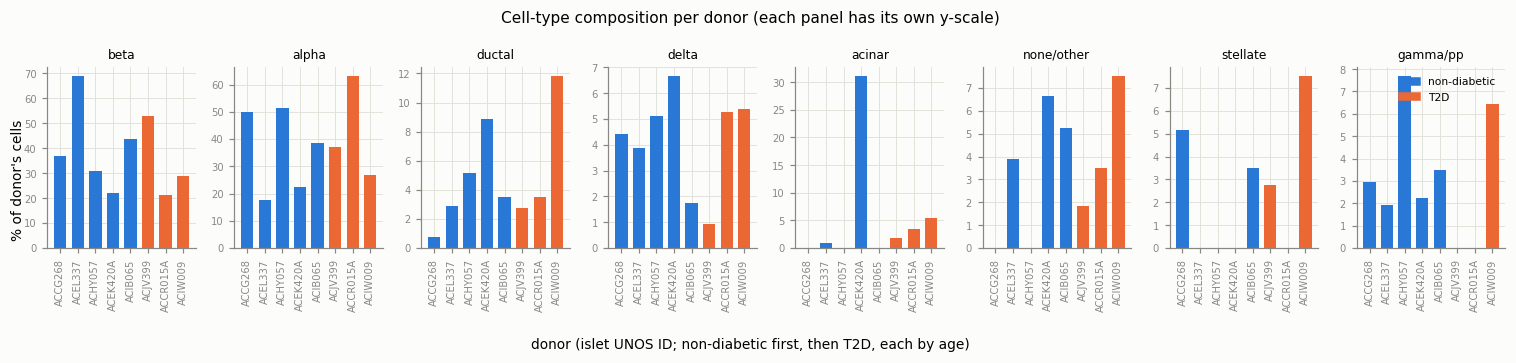

donor,ACCG268,ACEL337,ACHY057,ACEK420A,ACIB065,ACJV399,ACCR015A,ACIW009
condition,non-diabetic,non-diabetic,non-diabetic,non-diabetic,non-diabetic,T2D,T2D,T2D
age,22,29,30,53,56,42,51,55
sex,Male,Male,Male,Female,Female,Female,Male,Female
race,African American,White,African American,White,White,Hispanic,Hispanic,White
bmi,32.95,23.0,55.0,22.0,26.6,43.0,35.8,29.8
n_cells,136,103,39,45,57,108,57,93


In [25]:
frac_e = xt_e.div(xt_e.sum(axis=0), axis=1) * 100
fig, axes = plt.subplots(1, len(frac_e), figsize=(14, 3.2))
for ax, t in zip(axes, frac_e.index):
    ax.bar(range(len(DONOR_ORDER_E)), frac_e.loc[t].to_numpy(), width=0.7,
           color=[COND_COLOR[donor_meta_e.loc[d, "condition"]] for d in DONOR_ORDER_E])
    ax.set_title(t, fontsize=8)
    ax.set_xticks(range(len(DONOR_ORDER_E)), DONOR_ORDER_E, rotation=90)
    ax.tick_params(labelsize=6.5)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in COND_COLOR.values()]
axes[-1].legend(handles, COND_COLOR.keys(), fontsize=7, loc="upper right")
fig.supxlabel("donor (islet UNOS ID; non-diabetic first, then T2D, each by age)", fontsize=9)
fig.supylabel("% of donor's cells", fontsize=9)
fig.suptitle("Cell-type composition per donor (each panel has its own y-scale)", fontsize=10)
fig.tight_layout(); plt.show()
display(donor_meta_e.loc[DONOR_ORDER_E].T)

**Label observations**
* **8 labels = 7 cell types + `None/Other`:** beta 264 (41%), alpha 239 (37%), ductal 28, delta 25, acinar 24,
  stellate 19, gamma/PP 18, and 21 `none/other` cells (no marker called expressed). Imbalance among real types is
  15×. **Beta cells are the majority**, as in Baron, while alpha cells were in Xin and Segerstolpe.
* **No multi-hormone or doublet-like class exists by construction**: the 340 cells that expressed more than one
  marker were removed before deposition (E.0). The labelled query is therefore "cleaner" than a real one.
* **Gamma/PP has only 18 cells**, below the 20-cell minimum; all other types are ≥ 19 (stellate 19).
* **8 donors (5 non-diabetic, 3 T2D)**, 39–136 cells each (258 T2D / 380 ND cells), with all types present in both
  groups.
* **Composition is uneven across donors:** 14 of the 24 acinar cells come from one donor (ACEK420A, 31% of its
  cells); beta cells make up 69% of ACEL337 but 22% of ACEK420A; stellate cells occur in only 4 donors, and gamma/PP
  is absent in two of the three T2D donors.

## E.4 Per-cell quality metrics: depth, detected genes, mitochondrial share
Unlike Xin's RPKM, RSEM expected counts **are** a library-size measure (estimated reads per gene), so depth can be
used as for Baron. The SOFT text says the authors already removed cells with < 3,500 genes at ≥ 5 TPM and all cells
expressing more than one of their marker genes; this section checks that the deposited cells look filtered.

In [26]:
X_e = law.X
TYPE_COLOR_E = dict(zip(type_order(ct_e), PALETTE))
qc_e = pd.DataFrame({
    "total_counts": tot_e,
    "n_genes": np.asarray((X_e > 0).sum(1)).ravel(),
    "n_genes_ge5": np.asarray((X_e >= 5).sum(1)).ravel(),
    "pct_mt": 100 * np.asarray(X_e[:, mt_e].sum(1)).ravel() / tot_e,
    "top_gene_frac": np.asarray(X_e.max(1).todense()).ravel() / tot_e,
    "cell_type": ct_e.to_numpy(), "donor": donor_e.to_numpy(), "condition": cond_e.to_numpy(),
}, index=law.obs_names)
display(qc_e[["total_counts", "n_genes", "n_genes_ge5", "pct_mt", "top_gene_frac"]].describe().round(3).T)

,count,mean,std,min,25%,50%,75%,max
total_counts,638.0,1590879.750,571259.562,346163.094,1195123.031,1502767.500,1951571.844,3834270.500
n_genes,638.0,8319.561,1044.023,5687.000,7617.250,8333.500,9074.750,11034.000
n_genes_ge5,638.0,5980.597,1012.023,3529.000,5270.250,6009.000,6676.250,8451.000
pct_mt,638.0,10.847,8.349,0.387,5.024,9.190,14.279,72.235
top_gene_frac,638.0,0.131,0.118,0.010,0.045,0.071,0.209,0.509


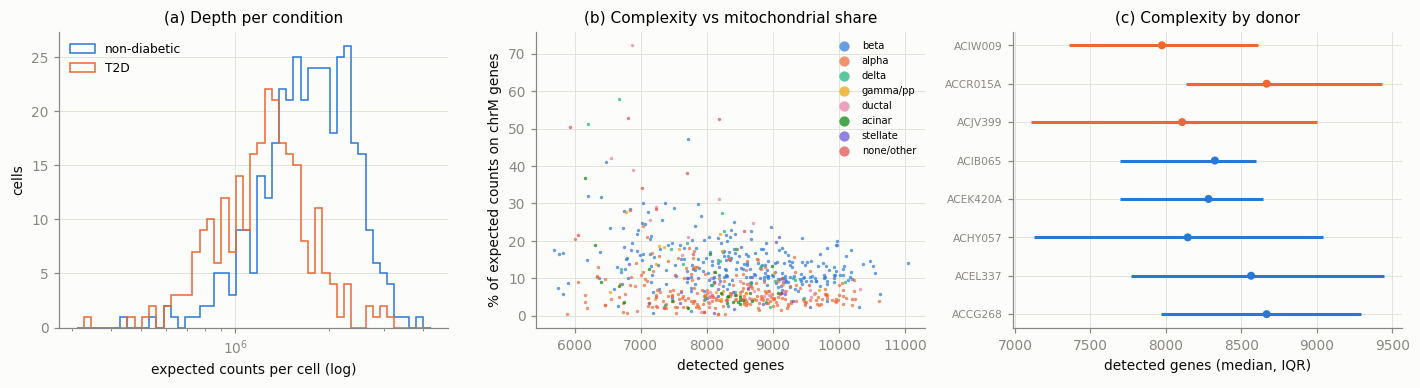

Minimum detected genes (> 0 / >= 5 expected counts): 5687 / 3529 | cells < 1,000 / < 2,000 genes: 0 / 0
Minimum expected counts per cell: 346163
Cells with > 10% / > 20% on chrM: 290 / 64
Median detected genes / %MT / top-gene fraction / depth by type and by condition:
            n_genes  pct_mt  top_gene_frac  total_counts
cell_type                                               
acinar       8318.5   5.283          0.078   1960517.438
alpha        8356.0   5.110          0.250   1586903.250
beta         8416.5  12.827          0.048   1510569.188
delta        8252.0  10.032          0.100   1179120.625
ductal       8345.0   8.306          0.028   1230942.438
gamma/pp     8209.0   9.879          0.071   1187617.500
none/other   7790.0  10.878          0.054   1009631.250
stellate     8406.0   6.151          0.027   1572266.875
              n_genes  pct_mt  top_gene_frac  total_counts
condition                                                 
T2D            8171.0   8.343          0.0

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
# (a) depth per condition
bins = np.logspace(np.log10(qc_e.total_counts.min() * 0.9), np.log10(qc_e.total_counts.max() * 1.1), 50)
for c, col in COND_COLOR.items():
    axes[0].hist(qc_e.loc[qc_e.condition == c, "total_counts"], bins=bins, histtype="step", lw=1.5, color=col, label=c)
axes[0].set_xscale("log"); axes[0].set_xlabel("expected counts per cell (log)"); axes[0].set_ylabel("cells")
axes[0].set_title("(a) Depth per condition"); axes[0].legend(fontsize=8)
# (b) detected genes vs %MT, coloured by cell type
for t, col in TYPE_COLOR_E.items():
    s = qc_e.cell_type == t
    axes[1].scatter(qc_e.n_genes[s], qc_e.pct_mt[s], s=5, alpha=0.7, color=col, label=t, linewidths=0)
axes[1].set_xlabel("detected genes"); axes[1].set_ylabel("% of expected counts on chrM genes")
axes[1].set_title("(b) Complexity vs mitochondrial share"); axes[1].legend(markerscale=3, fontsize=6.5)
# (c) detected genes per donor (median and IQR)
g = qc_e.groupby("donor")["n_genes"]
med, q1, q3 = g.median()[DONOR_ORDER_E], g.quantile(.25)[DONOR_ORDER_E], g.quantile(.75)[DONOR_ORDER_E]
y = np.arange(len(DONOR_ORDER_E)); cols = [COND_COLOR[donor_meta_e.loc[d, "condition"]] for d in DONOR_ORDER_E]
axes[2].hlines(y, q1, q3, color=cols, lw=2); axes[2].scatter(med, y, color=cols, s=18, zorder=3)
axes[2].set_yticks(y, DONOR_ORDER_E, fontsize=7); axes[2].set_xlabel("detected genes (median, IQR)")
axes[2].set_title("(c) Complexity by donor")
fig.tight_layout(); plt.show()

print("Minimum detected genes (> 0 / >= 5 expected counts):", int(qc_e.n_genes.min()), "/", int(qc_e.n_genes_ge5.min()),
      "| cells < 1,000 / < 2,000 genes:", int((qc_e.n_genes < 1000).sum()), "/", int((qc_e.n_genes < 2000).sum()))
print("Minimum expected counts per cell:", int(qc_e.total_counts.min()))
print("Cells with > 10% / > 20% on chrM:", int((qc_e.pct_mt > 10).sum()), "/", int((qc_e.pct_mt > 20).sum()))
print("Median detected genes / %MT / top-gene fraction / depth by type and by condition:")
cols_ = ["n_genes", "pct_mt", "top_gene_frac", "total_counts"]
print(qc_e.groupby("cell_type")[cols_].median().round(3).to_string())
print(qc_e.groupby("condition")[cols_].median().round(3).to_string())
print("Median depth per C1 run:", qc_e.groupby(law.obs.c1_run.to_numpy()).total_counts.median().round(0).to_dict())

**QC observations**
* **The data are filtered, as the SOFT says.** Every cell has ≥ 5,687 detected genes (median 8,334, the highest of
  all datasets) and ≥ 3,529 genes with ≥ 5 expected counts. This matches the authors' "≥ 3,500 genes at ≥ 5 TPM" rule,
  although our check is on expected counts, not TPM. The shared rule removes nothing. Depth is very high (median
  1.50M expected counts, minimum 346k).
* **%MT is measurable and again type-dependent:** median 9.2%, 290 cells above 10% and 64 above 20% (maximum 72%);
  beta cells have a median of 12.8%, alpha cells 5.1% (Xin: 27% vs 12%, the same direction). A fixed %MT cut-off
  would again remove a beta-biased subset. This supports the "no %MT filter" decision.
* **T2D cells are shallower** (median 1.26M vs 1.74M) and slightly less complex (8,171 vs about 8,460 genes), as in Xin.
* **Depth drifts with the C1 run:** run medians range from 0.91M (13th run) to 1.99M (1st run), with the early
  runs deepest. Every C1 run holds cells of a single donor (1–3 runs per donor), so run and donor effects cannot
  be separated; this is a donor/batch effect on depth that library-size normalisation removes.
* **A single gene dominates alpha cells:** in a median alpha cell 25% of all expected counts are one gene (GCG),
  vs 5% for beta cells.

## E.5 Gene-level behaviour: detection, top genes, mean–variance relationship

In [28]:
n_expr_e, mean_e, var_e = gene_level(law, "expected counts")

Genes detected in at most k cells:
  <=  0 cells:  4162  (15.6%)
  <=  2 cells:  6689  (25.1%)
  <=  9 cells:  8913  (33.5%)
  <= 19 cells: 10195  (38.3%)
  <= 49 cells: 12071  (45.4%)

Top-15 genes by share of all expected counts (%):
GCG        10.21
MT-CO1      3.22
MALAT1      2.07
TTR         1.87
MT-ND4      1.70
INS         1.40
MT-CO2      1.26
MT-CYB      1.15
MT-CO3      0.84
EEF1A1      0.70
MT-ND2      0.67
FTL         0.63
MT-ATP6     0.60
IAPP        0.52
B2M         0.45


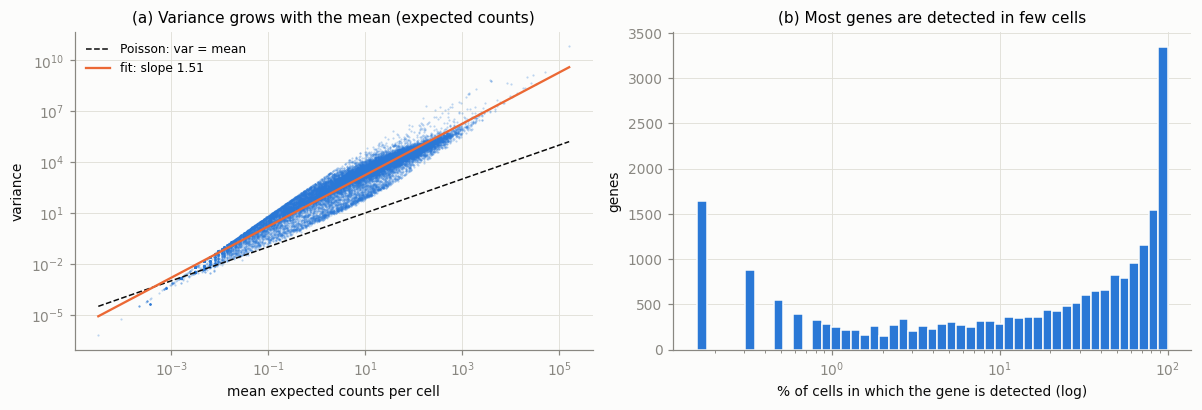

Fitted log-log slope of variance vs mean: 1.51


In [29]:
slope_e = plot_gene_level(n_expr_e, mean_e, var_e, law.n_obs, "expected counts")
print(f"Fitted log-log slope of variance vs mean: {slope_e:.2f}")

**Gene-level observations**
* **The variance grows much faster than the mean (log-log slope 1.51)**, the same as Xin's C1 RPKM (≈ 1.5) and
  steeper than Segerstolpe's reads (1.41). The C1/SMARTer amplification noise, not the unit, seems to be the main
  factor.
* **GCG alone is 10.2% of all expected counts**, and **7 of the top 15 genes are mitochondrial** (MT-CO1, MT-ND4,
  MT-CO2, MT-CYB, MT-CO3, MT-ND2, MT-ATP6), exactly the pattern seen for Xin. They disappear at the intersection with
  Baron (no MT genes).
* **Detection is bimodal** (b): many genes are detected in nearly every cell (the highest bar is at ~100%), the
  rest in few. 15.6% are never detected, 33.5% in fewer than 10 cells and 45.4% in fewer than 50. With only 638
  cells, "fewer than 10 cells" is a stricter criterion than in Baron.

## E.6 Labels vs markers, and how "clean" are the markers?
Lawlor's labels were assigned by a **Gaussian mixture on exactly seven marker genes** (INS, GCG, SST, PPY, KRT19,
PRSS1, COL1A1; SOFT `data_processing`), and cells expressing more than one of them were removed before deposition. On
the Baron panel the diagonal is therefore partly circular. The real test is the **independent check panel** from C.6
(markers not used by the authors), followed by the hormone-purity check of B.6.

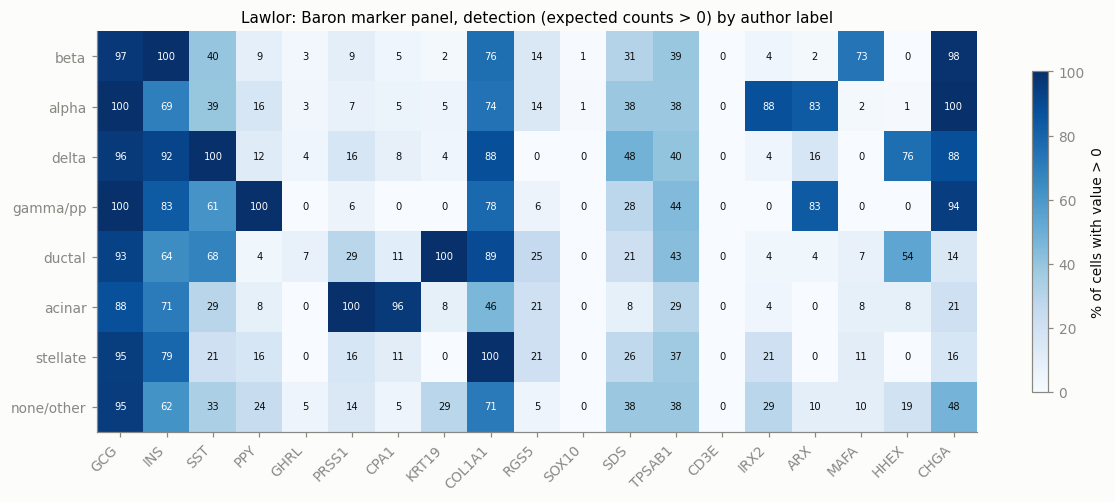

Panel markers not present (exactly once) in this dataset: ['PECAM1']


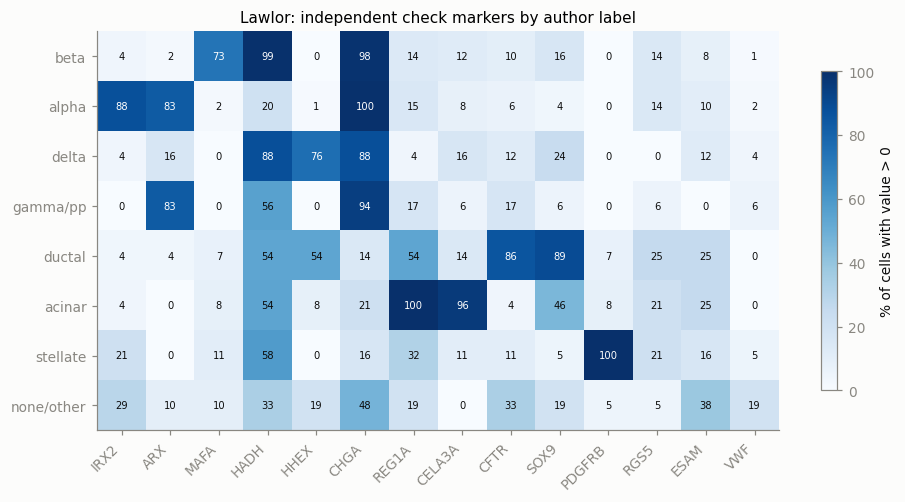

In [30]:
order_e = type_order(ct_e)
detect_e = detection_heatmap(law, list(MARKERS.values()) + EXTRA_ENDOCRINE, ct_e, order_e,
                             "Lawlor: Baron marker panel, detection (expected counts > 0) by author label")
missing = [g for g in dict.fromkeys(list(MARKERS.values()) + EXTRA_ENDOCRINE + CHECK) if (law.var["symbol"] == g).sum() != 1]
print("Panel markers not present (exactly once) in this dataset:", missing)
check_e = detection_heatmap(law, CHECK, ct_e, order_e, "Lawlor: independent check markers by author label")

In [31]:
HORMONE_E = {"alpha": "GCG", "beta": "INS", "delta": "SST", "gamma/pp": "PPY"}
purity_e, top_h_e, mixed_e = hormone_purity(law, ct_e, HORMONE_E, list(HORMONE_E))
display(purity_e)
lab_is_h_e = ct_e.isin(list(HORMONE_E)).to_numpy()
print("Hormone-labelled cells:", int(lab_is_h_e.sum()), "| label != top hormone:", int((top_h_e != ct_e)[lab_is_h_e].sum()),
      "| 'mixed':", int(mixed_e[lab_is_h_e].sum()))
# Raw hormone levels in non-endocrine cells: how much ambient/carry-over hormone signal is there?
ne = ct_e.isin(["ductal", "acinar", "stellate"]).to_numpy()
print("Median expected counts of GCG / INS in ductal+acinar+stellate cells:",
      np.median(gene_vec(law, "GCG")[ne]).round(1), "/", np.median(gene_vec(law, "INS")[ne]).round(1),
      "| in alpha / beta cells:", np.median(gene_vec(law, "GCG")[(ct_e == "alpha").to_numpy()]).round(0), "/",
      np.median(gene_vec(law, "INS")[(ct_e == "beta").to_numpy()]).round(0))
# RSEM splits multi-mapping reads into fractional expected counts, so "> 0" may count fragments of reads.
# Same detection table for a few cross-detected markers, with "> 0" vs ">= 1 expected count".
xdet = {}
for g in ["GCG", "INS", "SST", "COL1A1", "TPSAB1", "SDS", "KRT19", "PRSS1"]:
    v = gene_vec(law, g)
    xdet[(g, "> 0")] = pd.Series(v > 0, index=law.obs_names).groupby(ct_e.to_numpy()).mean() * 100
    xdet[(g, ">= 1")] = pd.Series(v >= 1, index=law.obs_names).groupby(ct_e.to_numpy()).mean() * 100
display(pd.DataFrame(xdet).loc[order_e].round(0).astype(int))

,n_cells,top hormone = label,top hormone != label,two hormones high (mixed)
alpha,239,239,0,0
beta,264,263,1,6
delta,25,25,0,1
gamma/pp,18,18,0,1


Hormone-labelled cells: 546 | label != top hormone: 1 | 'mixed': 8
Median expected counts of GCG / INS in ductal+acinar+stellate cells: 14.0 / 2.0 | in alpha / beta cells: 386882.0 / 48690.0


GCG       INS       SST      COL1A1      TPSAB1      SDS       \
            > 0 >= 1  > 0 >= 1  > 0 >= 1    > 0 >= 1    > 0 >= 1 > 0 >= 1   
beta         97   97  100  100   40   40     76   72     39   32  31   28   
alpha       100  100   69   69   39   39     74   66     38   26  38   33   
delta        96   96   92   92  100  100     88   80     40   28  48   48   
gamma/pp    100  100   83   83   61   61     78   78     44   33  28   28   
ductal       93   93   64   64   68   68     89   86     43   29  21   18   
acinar       88   88   71   71   29   29     46   38     29   29   8    8   
stellate     95   95   79   79   21   21    100  100     37   26  26   26   
none/other   95   95   62   62   33   33     71   71     38   24  38   33   

           KRT19      PRSS1       
             > 0 >= 1   > 0 >= 1  
beta           2    2     9    9  
alpha          5    5     7    7  
delta          4    4    16   16  
gamma/pp       0    0     6    6  
ductal       100  100    29   29  
acinar         8    8   100  100  
stellate       0    0    16   16  
none/other    29   29    14   14

**Marker observations**
* **On the authors' own seven markers the diagonal is 100% for every type** (GCG alpha, INS beta, SST delta, PPY
  gamma/PP, KRT19 ductal, PRSS1 acinar, COL1A1 stellate). This is circular: the labels were assigned from these
  genes.
* **The independent check panel supports the labels:** IRX2/ARX in 88/83% of alpha, MAFA in 73% and HADH in 99% of
  beta, HHEX in 76% of delta, ARX in 83% of gamma/PP, CFTR/SOX9 in 86/89% of ductal, REG1A/CELA3A in 100/96% of acinar
  and PDGFRB in 100% of stellate cells. ESAM and VWF are low everywhere (≤ 38% / ≤ 19%, highest in `none/other`), so
  there is no endothelial label, though a few of the 21 `none/other` cells may be endothelial.
* **"Expressed" (GMM) is not the same as "detected".** GCG is detected in 88–100% of cells of every type, INS in
  62–100%, and **COL1A1 in 46–100%** (74–76% of alpha and beta cells), even though the authors removed every cell in
  which a second marker was called expressed. TPSAB1 (mast cells) is detected in 29–44% of every type, although E has
  no mast-cell label. This is **not an artefact of RSEM's fractional values**: with a threshold of ≥ 1 expected count
  the rates barely change (COL1A1 66–72% in alpha/beta, TPSAB1 24–33%). The levels differ by orders of magnitude,
  though: the median GCG in ductal/acinar/stellate cells is 14 expected counts vs 386,882 in alpha cells, and INS
  2 vs 48,690 in beta cells. The ambient profile of E is therefore "GCG + INS + COL1A1 at low level everywhere".
* **Hormone purity:** 545 of the 546 hormone-labelled cells have their own hormone on top, and only 8 have a second
  hormone close to the first. This was expected after the authors' multi-marker filter.

## E.7 Global structure: do cells group by type, by donor or by condition?
Same throw-away pipeline as for Baron, on the expected counts (treated as counts). Inspection only.

In [32]:
P_e, evr_e, load_e = throwaway_pca(law)
known_e = (ct_e != "none/other").to_numpy()
sil_type_e = silhouette_score(P_e[known_e, :20], ct_e[known_e], random_state=SEED)
sil_donor_e = silhouette_score(P_e[:, :20], donor_e, random_state=SEED)
sil_cond_e = silhouette_score(P_e[:, :20], cond_e, random_state=SEED)
sil_run_e = silhouette_score(P_e[:, :20], law.obs.c1_run.astype(str), random_state=SEED)
print(f"\nSilhouette by cell type (without none/other): {sil_type_e:.3f}   by donor: {sil_donor_e:.3f}   "
      f"by condition: {sil_cond_e:.3f}   by C1 run: {sil_run_e:.3f}")
within_ed = {t: silhouette_score(P_e[(ct_e == t).to_numpy(), :20], donor_e[(ct_e == t).to_numpy()]) for t in ["alpha", "beta"]}
within_ec = {t: silhouette_score(P_e[(ct_e == t).to_numpy(), :20], cond_e[(ct_e == t).to_numpy()]) for t in ["alpha", "beta"]}
print("Silhouette *within* one cell type, by donor:", {k: round(v, 3) for k, v in within_ed.items()},
      "| by condition:", {k: round(v, 3) for k, v in within_ec.items()})
for pc in load_e:
    print(f"{pc} top +: {load_e[pc].nlargest(8).index.tolist()}\n    top -: {load_e[pc].nsmallest(8).index.tolist()}")
print("HVG gene types:", law.var.loc[load_e.index, "gene_type"].value_counts().head(4).to_dict())

Explained variance, PC1..PC10 (%): [5.1 3.3 2.  1.9 1.6 0.9 0.8 0.7 0.6 0.6]
Cumulative variance in 20 / 50 PCs: 22.4% / 33.4%

Silhouette by cell type (without none/other): 0.361   by donor: -0.103   by condition: 0.030   by C1 run: -0.171
Silhouette *within* one cell type, by donor: {'alpha': -0.141, 'beta': -0.051} | by condition: {'alpha': 0.055, 'beta': 0.035}
PC1 top +: ['IFITM3', 'LGALS1', 'COL4A1', 'SPARC', 'COL4A2', 'PXDN', 'IFITM2', 'SERPINE1']
    top -: ['G6PC2', 'PCSK1', 'FXYD2', 'IAPP', 'PEG10', 'PFKFB2', 'HADH', 'CDKN1C']
PC2 top +: ['SERPINA3', 'PDZK1IP1', 'LCN2', 'REG1A', 'IL32', 'CFB__ENSG00000243649', 'TM4SF1', 'KRT7']
    top -: ['COL3A1', 'COL15A1', 'COL1A2', 'COL1A1', 'BGN', 'SPARC', 'NID1', 'LUM']
HVG gene types: {'protein_coding': 1935, 'lincRNA': 57, 'processed_transcript': 4, 'sense_overlapping': 2}


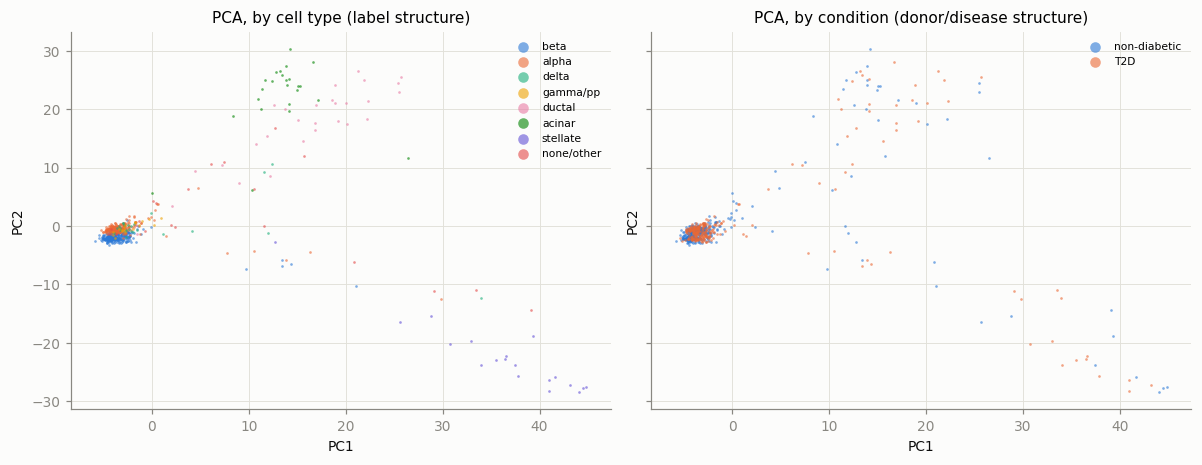

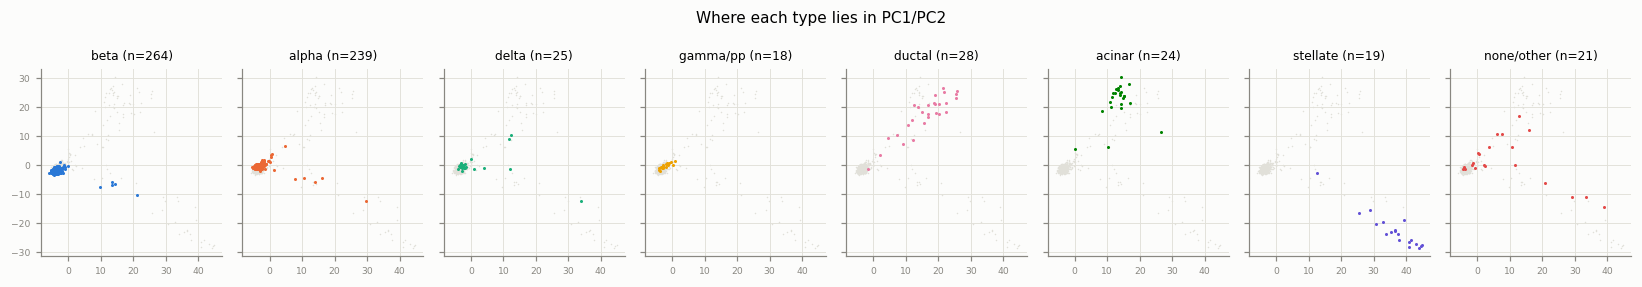

In [33]:
rng = np.random.default_rng(SEED)
perm_e = rng.permutation(law.n_obs)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3), sharex=True, sharey=True)
scatter_groups(axes[0], P_e, ct_e, TYPE_COLOR_E, "PCA, by cell type (label structure)", perm_e)
scatter_groups(axes[1], P_e, cond_e, COND_COLOR, "PCA, by condition (donor/disease structure)", perm_e)
fig.tight_layout(); plt.show()

fig, axes = plt.subplots(1, len(order_e), figsize=(15, 2.6), sharex=True, sharey=True)
for ax, t in zip(axes, order_e):
    s = (ct_e == t).to_numpy()
    ax.scatter(P_e[~s, 0], P_e[~s, 1], s=1, color=GRID, linewidths=0)
    ax.scatter(P_e[s, 0], P_e[s, 1], s=4, color=TYPE_COLOR_E[t], linewidths=0)
    ax.set_title(f"{t} (n={s.sum()})", fontsize=8); ax.tick_params(labelsize=6)
fig.suptitle("Where each type lies in PC1/PC2", fontsize=10)
fig.tight_layout(); plt.show()

**Structure observations**
* **Cell type dominates; donor, condition and C1 run do not** (silhouette 0.36 by type without `none/other`, −0.10
  by donor, 0.03 by condition, −0.17 by C1 run; within alpha and beta the donor silhouette is negative, the
  condition silhouette 0.04–0.06). The type silhouette is the highest of the author-labelled datasets, as expected
  after removing multi-marker cells.
* PC1 (5.1%) separates the non-endocrine cells (IFITM3, LGALS1, SPARC, COL4A1/2) from the endocrine core (G6PC2,
  PCSK1, IAPP, HADH); PC2 (3.3%) separates the exocrine arm (SERPINA3, LCN2, REG1A, KRT7) from the stellate arm
  (COL1A1/2, COL3A1, LUM). 86% of the cells are endocrine and overlap at the origin, so the first PCs are driven by
  the ~70 non-endocrine cells, as for Xin; 20 PCs hold 22.4% of the variance.
* **`none/other` cells are scattered** between the endocrine core and both arms: they are not one population but a
  mix of low-marker cells of several lineages, which is what the label says.
* The HVGs are almost all protein-coding (1,935 of 2,000; the matrix has no pseudogenes).

## E.8 Summary of the Lawlor inspection

| aspect | Lawlor (GSE86469) |
|---|---|
| cells × genes | 638 × 26,616 (protein-coding + lincRNA, Ensembl v70) |
| technology | Fluidigm C1 + SMARTer, full-length, NextSeq 500 |
| values available | **RSEM expected counts** (fractional); the SOFT wrongly calls them TPM |
| labels | in the GEO SOFT file (`cell type`), defined by 7 markers via a Gaussian mixture |
| missing values | none |
| prior QC | yes (≥ 3,500 genes at ≥ 5 TPM; 340 multi-marker cells removed) |
| MT genes | present (13, `MT-` prefix); %MT median 9%, type-dependent |
| classes | 7 types + 21 none/other; beta 264 … gamma/PP 18, imbalance 15× |
| batch structure | 8 donors (5 ND / 3 T2D), 39–136 cells each; 13 C1 runs; small expression effect |
| notable | labels "clean by construction"; COL1A1/TPSAB1 detected in most cells; PECAM1 absent from the matrix |

## E.9 Proposed preprocessing for Lawlor (for discussion)

* **Step A — cell filtering (R4).** The shared rule removes nothing (minimum 5,687 genes); no %MT filter, for the
  same reasons as Xin (E.4). Nothing dataset-specific is needed.
* **Step B — labels.** Labels from GEO; `none/other` (21) excluded from training and labelled evaluation.
  `Gamma/PP` → `gamma`, `stellate` → the stellate parent node. Gamma/PP has 18 cells (< 20). **Caveat for every
  result on E:** the 340 multi-marker cells were removed before deposition, so E is an easier query than a raw one;
  rejection rates on E will be optimistic.
* **Step C — genes (R2, R5).** Use the Ensembl v70 names; sum or drop the 120 duplicated symbols; MT genes drop out
  at the intersection with Baron. 18,143 genes are shared with Baron. PECAM1 is absent, so any endothelial-marker
  feature is unavailable for E.
* **Step D — normalisation (R3).** `normalize_total` (10,000) + `log1p` on the expected counts, as for Baron. The
  only deviation is that the "counts" are fractional (small: 2.9% of non-zero values are below 1); rounding is an
  option but not necessary.
* **Role in the study:** small (638 cells) but well annotated; with Xin it forms a **same-technology (C1),
  different-lab pair** (B ↔ E), which separates lab effects from technology effects. As a query for **A → E**, all
  seven types exist in Baron. It also adds an ND → T2D split (5 vs 3 donors).

---
# Dataset F — Enge et al. (GSE81547, human pancreas across ages, Smart-seq2)

## F.0 What is in the SOFT file, and conversion
The SOFT file was copied (not moved) from `~/Downloads/proj_data/` to `data/raw/enge_GSE81547/`.

In [34]:
gse_f = GEOparse.get_GEO(filepath=str(ENGE_SOFT))
print("GEO accession:", gse_f.name, "|", gse_f.metadata["title"][0])
print("Platforms:", list(gse_f.gpls), "| number of samples (GSM):", len(gse_f.gsms))
print("Series supplementary files:", *gse_f.metadata["supplementary_file"], sep="\n  ")

meta_f = soft_samples(gse_f)
print("\nGSM tables with rows:", int((meta_f.table_rows > 0).sum()), "| GSMs with a supplementary file:",
      int((meta_f.supplementary_file != "NONE").sum()), "| e.g.", meta_f.supplementary_file.iloc[0])
print("Characteristic keys:", [c for c in meta_f.columns if c not in
      ("title", "description", "platform", "source", "table_rows", "supplementary_file")])
print("\ndata_processing (identical for every GSM):")
for line in next(iter(gse_f.gsms.values())).metadata["data_processing"]:
    print("  *", line)
meta_f.head(3)

GEO accession: GSE81547 | Single cell transcriptome analysis of human pancreas reveals transcriptional signatures of aging and somatic mutation patterns.
Platforms: ['GPL18573'] | number of samples (GSM): 2544
Series supplementary files:
  ftp://ftp.ncbi.nlm.nih.gov/geo/series/GSE81nnn/GSE81547/suppl/GSE81547_RAW.tar

GSM tables with rows: 0 | GSMs with a supplementary file: 2544 | e.g. ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM2171nnn/GSM2171880/suppl/GSM2171880_1000010011.A07.csv.gz
Characteristic keys: ['donor_age', 'gender', 'inferred_cell_type']

data_processing (identical for every GSM):
  * Sequencing reads were trimmed, adapter sequences removed and the reads aligned using STAR with default parameters.
  * Duplicate reads were removed using picard. Transcript counts were obtained using HT-Seq and hg19 UCSC exon/transcript annotations.
  * Genome_build: hg19
  * Supplementary_files_format_and_content: tab-delimited text files with raw read values for each sample


,title,description,platform,source,table_rows,supplementary_file,donor_age,gender,inferred_cell_type
GSM2171880,21yr_male_cell1,Single cell from human pancreas,GPL18573,Pancreatic islet,0,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM2171...,21,male,alpha
GSM2171881,21yr_male_cell2,Single cell from human pancreas,GPL18573,Pancreatic islet,0,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM2171...,21,male,alpha
GSM2171882,21yr_male_cell3,Single cell from human pancreas,GPL18573,Pancreatic islet,0,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM2171...,21,male,acinar


**What the SOFT file contains.** One GSM per cell (2,544 GSMs), empty GSM tables, and three characteristics:
`donor_age`, `gender` and `inferred_cell_type` (the author label; the name says it was inferred from the data).
**There is no donor ID**; donors can only be identified by age and sex (F.3). Unlike the other GEO series, **every
GSM has its own supplementary file** (`GSM…_<plate>.<well>.csv.gz`), and the series-level supplementary file
`GSE81547_RAW.tar` (176 MB) is just the bundle of these 2,544 files. It was downloaded from the GEO FTP site into
`data/raw/enge_GSE81547/`, checked to contain only 2,544 regular files, and unpacked into its own new folder
`RAW/`. Platform GPL18573 = Illumina NextSeq 500.

The processing description: STAR alignment to hg19, **duplicate reads removed with picard**, counts from **HTSeq on
UCSC hg19 annotation** ("raw read values"). The extract protocol is a Smart-seq2-style plate protocol (96-well
plates, LNA template-switch oligo, 21 pre-amplification cycles), and **only wells with a successful cDNA profile
(> 0.06 ng/µl, no degradation on the Fragment Analyzer) were sequenced**, i.e. a wet-lab QC before deposition.

Each file is one HTSeq output: 23,460 features (genes + ERCC) followed by HTSeq's five bookkeeping rows
(`no_feature`, `ambiguous`, …). The conversion reads all 2,544 files (checked to have the identical gene list),
moves the bookkeeping rows into per-cell `obs` columns (`htseq_*`), and writes cells × features with `X` = raw
counts (also layer `counts`) to `data/interim/enge_human.h5ad`, the same layout as before.

In [35]:
HTSEQ_SPECIAL = ["no_feature", "ambiguous", "too_low_aQual", "not_aligned", "alignment_not_unique"]

def build_enge():
    """2,544 per-cell HTSeq count files (GEO GSM supplementary) + SOFT characteristics -> AnnData (cells x genes)."""
    files = {f.name.split("_")[0]: f for f in ENGE_RAW.glob("GSM*.csv.gz")}
    assert set(files) == set(meta_f.index), "RAW.tar members and GSMs do not match 1:1"
    rows, genes = [], None
    for gsm in meta_f.index:
        s = pd.read_csv(files[gsm], sep="\t", header=None, index_col=0, dtype={0: str, 1: np.int64}).iloc[:, 0]
        if genes is None:
            genes = s.index
        else:
            assert s.index.equals(genes), f"{gsm}: different gene list"
        rows.append(s.to_numpy())
    M = np.vstack(rows)                                                     # cells x features
    print(f"{len(rows)} files, each with {len(genes)} rows -> matrix {M.shape}; every file has the same gene list")
    special = np.isin(genes, HTSEQ_SPECIAL)

    o = meta_f.rename(columns={"inferred_cell_type": "cell_type1", "gender": "sex"})
    o["age"] = o["donor_age"].astype(int)
    o["donor"] = o["age"].astype(str) + "yr_" + o["sex"]                    # one donor per age (checked in F.3)
    stem = o["supplementary_file"].str.rsplit("/", n=1).str[1].str.split("_", n=1).str[1].str.replace(".csv.gz", "", regex=False)
    o["plate"], o["well"] = stem.str.split(".").str[0], stem.str.split(".").str[1]   # '1000010011.A07'
    o = o.rename_axis("gsm").reset_index()
    o.index = o["title"].astype(str); o.index.name = "cell_id"
    for j, k in zip(np.flatnonzero(special), genes[special]):              # HTSeq bookkeeping rows -> per-cell QC columns
        o[f"htseq_{k}"] = M[:, j]
    o = o[["gsm", "cell_type1", "donor", "age", "sex", "plate", "well"] + [f"htseq_{k}" for k in genes[special]]
          + ["source", "platform"]]

    var = pd.DataFrame({"symbol": genes[~special].astype(str)})
    var["is_ercc"] = var["symbol"].str.startswith("ERCC-")
    var.index = var["symbol"].to_numpy(); var.index.name = "gene_id"
    assert var.index.is_unique

    X = sp.csr_matrix(M[:, ~special], dtype="float32")
    assert np.array_equal(np.asarray(X.sum(1)).ravel().astype(np.int64), M[:, ~special].sum(1)), "conversion mismatch"
    print("Row sums of X equal the per-file totals -> conversion is lossless (integers stored as float32)")
    a = ad.AnnData(X=X, obs=o, var=var, layers={"counts": X.copy()})
    a.uns["X_source_assay"] = "counts"
    a.uns["source_files"] = [str(ENGE_SOFT), str(ENGE_TAR)]
    a.write_h5ad(ENGE_H5, compression="gzip")
    print(f"-> {ENGE_H5}: {a.n_obs} cells x {a.n_vars} features")
    return a

enge = build_enge()

2544 files, each with 23465 rows -> matrix (2544, 23465); every file has the same gene list


Row sums of X equal the per-file totals -> conversion is lossless (integers stored as float32)


-> /home/professor/cell-type-annotaion-benchmark/data/interim/enge_human.h5ad: 2544 cells x 23460 features


## F.1 Overview of the Enge (GSE81547) object

In [36]:
print(enge)
print("\nX is assay:", enge.uns["X_source_assay"], "| dtype:", enge.X.dtype, "| sparse:", sp.issparse(enge.X))
print(f"Sparsity (fraction of zeros): {1 - enge.X.nnz / np.prod(enge.shape):.3f}")
ercc_f = enge.var["is_ercc"].to_numpy()
print(f"Features: {(~ercc_f).sum()} genes + {ercc_f.sum()} ERCC spike-ins")
tot_f = np.asarray(enge.X[:, ~ercc_f].sum(1)).ravel()
print("Per-cell reads on genes:", pd.Series(tot_f).describe()[["min", "50%", "max"]].round(0).to_dict())
hts = enge.obs[[c for c in enge.obs.columns if c.startswith("htseq_")]]
all_reads = hts.sum(axis=1).to_numpy() + np.asarray(enge.X.sum(1)).ravel()
print("Median share of each cell's reads (HTSeq categories, %):")
print((pd.concat([hts, pd.DataFrame({"genes": tot_f, "ERCC": np.asarray(enge.X[:, ercc_f].sum(1)).ravel()},
                                    index=enge.obs_names)], axis=1).div(all_reads, axis=0) * 100).median().round(1).to_string())
print("Cells per donor:", enge.obs.donor.value_counts().to_dict(), "| plates:", enge.obs.plate.nunique())
enge.obs.head(3)

AnnData object with n_obs × n_vars = 2544 × 23460
    obs: 'gsm', 'cell_type1', 'donor', 'age', 'sex', 'plate', 'well', 'htseq_no_feature', 'htseq_ambiguous', 'htseq_too_low_aQual', 'htseq_not_aligned', 'htseq_alignment_not_unique', 'source', 'platform'
    var: 'symbol', 'is_ercc'
    uns: 'X_source_assay', 'source_files'
    layers: 'counts', None (.X)

X is assay: counts | dtype: float32 | sparse: True
Sparsity (fraction of zeros): 0.856
Features: 23368 genes + 92 ERCC spike-ins
Per-cell reads on genes: {'min': 100243.0, '50%': 458190.0, 'max': 4239388.0}
Median share of each cell's reads (HTSeq categories, %):
htseq_no_feature              30.9
htseq_ambiguous                0.8
htseq_too_low_aQual            0.0
htseq_not_aligned              0.0
htseq_alignment_not_unique    10.4
genes                         51.5
ERCC                           4.7
Cells per donor: {'21yr_male': 505, '38yr_female': 474, '5yr_male': 331, '22yr_male': 286, '44yr_female': 277, '54yr_male': 272, '1yr

,gsm,cell_type1,donor,age,sex,plate,well,htseq_no_feature,htseq_ambiguous,htseq_too_low_aQual,htseq_not_aligned,htseq_alignment_not_unique,source,platform
cell_id,,,,,,,,,,,,,,
21yr_male_cell1,GSM2171880,alpha,21yr_male,21,male,1000010011,A07,407558,3754,0,0,85563,Pancreatic islet,GPL18573
21yr_male_cell2,GSM2171881,alpha,21yr_male,21,male,1000010011,D12,359410,4592,0,0,70223,Pancreatic islet,GPL18573
21yr_male_cell3,GSM2171882,acinar,21yr_male,21,male,1000010012,H10,172353,4473,0,0,39277,Pancreatic islet,GPL18573


**What we have:** 2,544 cells × 23,460 features (23,368 genes + 92 ERCC spike-ins), raw **read counts** after
deduplication (integers, no UMIs), so R3 applies directly. About 86% of entries are zero.

* Every cell has **at least 100,243 reads on genes** (median 458k, maximum 4.2M). No empty or failed wells were
  deposited (see F.4).
* **Only about half of each cell's reads are on genes** (median 51.5%). 30.9% fall outside any annotated exon
  (`no_feature`), 10.4% are multi-mapping and 4.7% are on ERCC. The large `no_feature` share is typical for
  full-length data counted against a RefSeq/UCSC exon model (intronic and unannotated reads).
* 8 donors with 178–505 cells each, on 42 plates; each plate holds cells of a single donor (F.2).

**Where the expression values live.** As for Segerstolpe and Lawlor: `enge.X` is the cells × genes matrix (for Enge: raw read counts), its columns are
named by `enge.var_names`, and `enge.obs` / `enge.var` only describe its rows / columns. Enge has no PP class, so PPY is shown only for comparison. One example cell per type
against the marker genes:

In [ ]:
# Where the expression values live: enge.X is the cells x genes matrix; its rows are named by enge.obs_names (cells)
# and its columns by enge.var_names (genes). enge.obs / enge.var describe those rows / columns and hold no expression.
print("X:", type(enge.X).__name__, enge.X.shape, "| holds:", enge.uns["X_source_assay"],
      "| other versions in layers:", [k for k in enge.layers.keys() if k is not None])   # None = X itself in this anndata
print("Gene names = column names of X (var_names):", list(enge.var_names[:5]), "...")
print(f"Stored non-zero values: {enge.X.nnz:,} of {np.prod(enge.shape):,} entries")

# A small window into X: one example cell per type (rows) x the marker gene of each type (columns).
ex_types = ['alpha', 'beta', 'delta', 'acinar', 'ductal']
ex_genes = ['GCG', 'INS', 'SST', 'PPY', 'PRSS1', 'KRT19']
ex_cells = [enge.obs_names[enge.obs["cell_type1"] == t][0] for t in ex_types]
ex_window = enge[ex_cells, ex_genes].to_df()
ex_window.insert(0, "cell_type1", enge.obs.loc[ex_cells, "cell_type1"].values)
ex_window

X: csr_matrix (2544, 23460) | holds: counts | other versions in layers: ['counts']
Gene names = column names of X (var_names): ['1/2-SBSRNA4', 'A1BG', 'A1BG-AS1', 'A1CF', 'A2LD1'] ...
Stored non-zero values: 8,588,886 of 59,682,240 entries


gene_id,cell_type1,GCG,INS,SST,PPY,PRSS1,KRT19
cell_id,,,,,,,
21yr_male_cell1,alpha,16900.0,0.0,0.0,0.0,0.0,0.0
21yr_male_cell196,beta,2.0,920.0,0.0,0.0,0.0,0.0
21yr_male_cell55,delta,3.0,0.0,4233.0,0.0,0.0,4.0
21yr_male_cell3,acinar,2.0,0.0,0.0,0.0,1553.0,0.0
21yr_male_cell320,ductal,16.0,0.0,0.0,0.0,0.0,493.0


## F.2 Data integrity and missing values
Same checklist; HTSeq counts must be integers.

In [37]:
display(integrity_checks(enge, integer_expected=True))
constant_cols = [c for c in enge.obs.columns if enge.obs[c].nunique() == 1]
print(f"{len(constant_cols)} constant obs columns (no information):", constant_cols)
print("plates per donor:", enge.obs.groupby("donor").plate.nunique().to_dict())
print("donors per plate (max):", enge.obs.groupby("plate").donor.nunique().max())

,count,expected
NaN/Inf in matrix,0,0
negative values,0,0
non-integer values,0,0
NaN cells in obs,0,0
NaN cells in var,0,0
duplicated cell IDs,0,0
duplicated gene names,0,0
cells with zero total,0,0
genes detected in 0 cells,1994,-


4 constant obs columns (no information): ['htseq_too_low_aQual', 'htseq_not_aligned', 'source', 'platform']
plates per donor: {'1yr_male': 6, '5yr_male': 7, '6yr_male': 2, '21yr_male': 6, '22yr_male': 4, '38yr_female': 8, '44yr_female': 4, '54yr_male': 5}
donors per plate (max): 1


In [38]:
# Gene-name hygiene: mitochondrial / ribosomal / spike-in / odd names.
names_f = enge.var["symbol"][~ercc_f]
print("names starting 'MT-':   ", int(names_f.str.startswith("MT-").sum()), "| MTRNR2L*:", int(names_f.str.startswith("MTRNR2L").sum()),
      "| mitochondrially encoded names without prefix:",
      int(names_f.isin(["ND1", "ND2", "ND3", "ND4", "ND4L", "ND5", "ND6", "COX1", "COX2", "COX3", "ATP6", "ATP8", "CYTB"]).sum()))
print("RPL/RPS ribosomal genes:", int(names_f.str.match(r"^RP[LS]\d").sum()))
print("ERCC spike-ins:         ", int(ercc_f.sum()), list(enge.var.symbol[ercc_f][:3]))
print("ERCC* real genes:       ", list(names_f[names_f.str.match(r"^ERCC\d|.*-ERCC")]))
print("lower-case / odd names: ", list(names_f[names_f.str.match(r"^[a-z0-9]")][:10]))
print("LOC* / 'orf' names:     ", int(names_f.str.startswith("LOC").sum()), "/", int(names_f.str.contains("orf").sum()))

names starting 'MT-':    0 | MTRNR2L*: 9 | mitochondrially encoded names without prefix: 0
RPL/RPS ribosomal genes: 122
ERCC spike-ins:          92 ['ERCC-00002', 'ERCC-00003', 'ERCC-00004']
ERCC* real genes:        ['BIVM-ERCC5', 'ERCC1', 'ERCC2', 'ERCC3', 'ERCC4', 'ERCC5', 'ERCC6', 'ERCC6L', 'ERCC8']
lower-case / odd names:  ['1/2-SBSRNA4', 'tAKR']
LOC* / 'orf' names:      1282 / 873


**Integrity results**
* **No missing values**, no negative or non-integer counts, no duplicated IDs, no empty cells; the conversion is
  exact (integers). 1,994 genes (8.5%) are never detected.
* **Donor and plate are confounded:** every plate holds cells of exactly one donor (2–8 plates per donor). Any donor
  effect in F.7 is also a plate effect.
* **No mitochondrial genes** (no `MT-` names, no unprefixed ones; the UCSC hg19 annotation used has no chrM genes in
  this table), so no %MT filter, as for Baron, Muraro and Segerstolpe; 9 nuclear `MTRNR2L*` genes.
* **92 ERCC spike-ins** (`ERCC-000nn`) next to the real `ERCC1…8` genes and a `BIVM-ERCC5` read-through gene, so the
  spike-in rule must use `ERCC-`. 122 RPL/RPS genes.
* Annotation artefacts to clean at the intersection step: `1/2-SBSRNA4`, `tAKR`, 1,282 `LOC*` and 873 `…orf…`
  names.
* Two HTSeq bookkeeping columns (`too_low_aQual`, `not_aligned`) are always 0 and carry no information.

## F.3 Cell-type labels: what are we classifying?
The labels are in the SOFT file (`inferred_cell_type`); the name already says they were inferred by the authors from
the expression data. The donor is not given as an ID: each donor is identified by **age and sex**, and the check
below confirms that every (age, sex) pair is one donor.

In [39]:
ct_f = enge.obs["cell_type1"].astype(str)
donor_f = enge.obs["donor"].astype(str)
counts_f = ct_f.value_counts()
display(pd.DataFrame({"n_cells": counts_f, "fraction_%": (100 * counts_f / counts_f.sum()).round(2),
                      "lineage": counts_f.index.map(LINEAGE)}))
lab_f = counts_f.drop("unsure", errors="ignore")
print(f"{ct_f.nunique()} labels ({len(lab_f)} cell types + unsure); imbalance ratio largest/smallest type = {lab_f.max() / lab_f.min():.0f}x")
display(pd.crosstab(enge.obs.age, enge.obs.sex))
donor_meta_f = (enge.obs.groupby("donor", observed=True)[["age", "sex"]].first()
                .assign(n_cells=donor_f.value_counts(), n_plates=enge.obs.groupby("donor").plate.nunique()))
DONOR_ORDER_F = donor_meta_f.sort_values("age").index.tolist()
print(f"{len(DONOR_ORDER_F)} donors, ages {donor_meta_f.age.min()}-{donor_meta_f.age.max()} years; cells per donor "
      f"{donor_f.value_counts().min()}-{donor_f.value_counts().max()}")
xt_f = pd.crosstab(ct_f, donor_f).loc[counts_f.index, DONOR_ORDER_F]
display(xt_f.style.background_gradient(cmap="Blues", axis=None))

,n_cells,fraction_%,lineage
cell_type1,,,
alpha,998,39.23,endocrine
acinar,411,16.16,exocrine
ductal,389,15.29,exocrine
beta,348,13.68,endocrine
unsure,262,10.30,unassigned
delta,83,3.26,endocrine
mesenchymal,53,2.08,stromal


7 labels (6 cell types + unsure); imbalance ratio largest/smallest type = 19x


sex,female,male
age,,
1,0,221
5,0,331
6,0,178
21,0,505
22,0,286
38,474,0
44,277,0
54,0,272


8 donors, ages 1-54 years; cells per donor 178-505


donor,1yr_male,5yr_male,6yr_male,21yr_male,22yr_male,38yr_female,44yr_female,54yr_male
cell_type1,,,,,,,,
alpha,38,61,71,157,133,226,141,171
acinar,54,108,35,74,10,76,18,36
ductal,43,81,0,89,5,86,75,10
beta,48,35,43,4,89,69,24,36
unsure,12,5,26,167,28,1,10,13
delta,25,7,2,14,14,10,9,2
mesenchymal,1,34,1,0,7,6,0,4


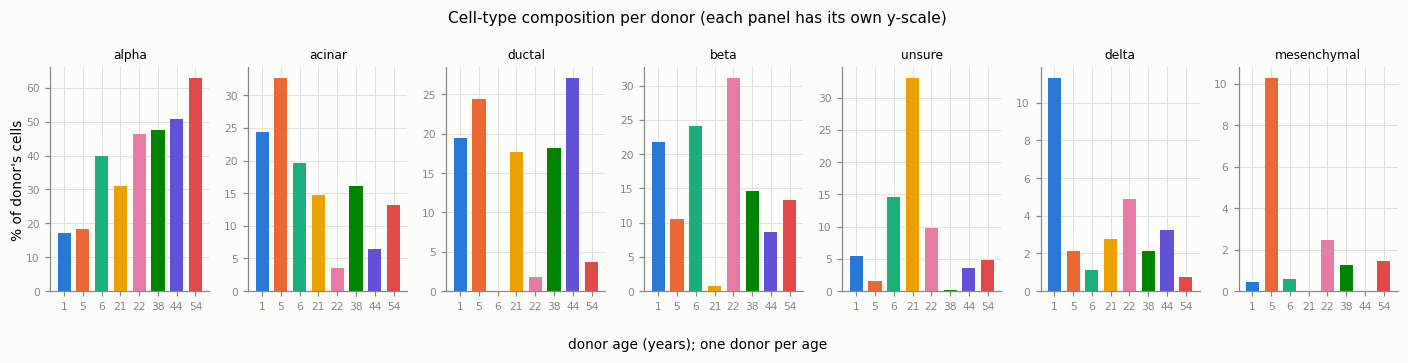

donor,1yr_male,5yr_male,6yr_male,21yr_male,22yr_male,38yr_female,44yr_female,54yr_male
age,1,5,6,21,22,38,44,54
sex,male,male,male,male,male,female,female,male
n_cells,221,331,178,505,286,474,277,272
n_plates,6,7,2,6,4,8,4,5


In [40]:
DONOR_COLOR_F = {d: PALETTE[i] for i, d in enumerate(DONOR_ORDER_F)}
frac_f = xt_f.div(xt_f.sum(axis=0), axis=1) * 100
fig, axes = plt.subplots(1, len(frac_f), figsize=(13, 3.2))
for ax, t in zip(axes, frac_f.index):
    ax.bar(range(len(DONOR_ORDER_F)), frac_f.loc[t].to_numpy(), width=0.7, color=list(DONOR_COLOR_F.values()))
    ax.set_title(t, fontsize=8)
    ax.set_xticks(range(len(DONOR_ORDER_F)), [str(donor_meta_f.loc[d, "age"]) for d in DONOR_ORDER_F])
    ax.tick_params(labelsize=7)
fig.supxlabel("donor age (years); one donor per age", fontsize=9)
fig.supylabel("% of donor's cells", fontsize=9)
fig.suptitle("Cell-type composition per donor (each panel has its own y-scale)", fontsize=10)
fig.tight_layout(); plt.show()
display(donor_meta_f.loc[DONOR_ORDER_F].T)

**Label observations**
* **7 labels = 6 types + `unsure`:** alpha 998 (39%), acinar 411, ductal 389, beta 348, delta 83, mesenchymal 53,
  and **262 `unsure` cells (10%)**. Imbalance among real types is 19×.
* **There is no gamma/PP, epsilon, endothelial, immune or Schwann label at all.** F.6 shows that PP cells do exist
  in the data but are not labelled.
* **8 donors, ages 1, 5, 6, 21, 22, 38, 44 and 54 years** (6 male, 2 female); each (age, sex) pair is one donor.
  Three children (≤ 6 y) and five adults. This is the study's design axis (ageing), and the only dataset with
  children.
* **One donor's labels look incomplete:** the 21-year-old donor has 505 cells but only **4 beta cells and 167
  `unsure` cells** (33% of its cells, versus 0.2–15% for the other donors). F.6 shows that most of these
  are beta cells.
* Other strong donor-specific compositions: the 6-year-old has no ductal cells, 34 of the 53 mesenchymal cells come
  from the 5-year-old, and the 22-year-old has almost no exocrine cells (15 of 286).

## F.4 Per-cell quality metrics: library size, detected genes, spike-in share
Read counts (duplicates removed with picard, per the SOFT), so library size is again meaningful. The question, as
for Muraro and Segerstolpe, is whether the deposited cells were already filtered.

In [41]:
X_f = enge.X
qc_f = pd.DataFrame({
    "total_counts": tot_f,
    "n_genes": np.asarray((X_f[:, ~ercc_f] > 0).sum(1)).ravel(),
    "pct_ercc": 100 * np.asarray(X_f[:, ercc_f].sum(1)).ravel() / np.maximum(np.asarray(X_f.sum(1)).ravel(), 1e-9),
    "pct_no_feature": 100 * enge.obs["htseq_no_feature"].to_numpy() / all_reads,
    "top_gene_frac": np.asarray(X_f[:, ~ercc_f].max(1).todense()).ravel() / np.maximum(tot_f, 1e-9),
    "donor": donor_f.to_numpy(), "cell_type": ct_f.to_numpy(), "plate": enge.obs.plate.to_numpy(),
}, index=enge.obs_names)
qc_f["lineage"] = qc_f["cell_type"].map(LINEAGE)
display(qc_f[["total_counts", "n_genes", "pct_ercc", "pct_no_feature", "top_gene_frac"]].describe().round(3).T)
thr = [0, 500, 1000, 2000, 5000, 10000]
display(pd.DataFrame({"cells with >= t reads on genes": [(tot_f >= t).sum() for t in thr],
                      "cells with >= t detected genes": [(qc_f.n_genes >= t).sum() for t in thr]}, index=thr).T)
GATE_F = ((qc_f.n_genes >= 500) & (qc_f.total_counts >= 1000)).to_numpy()   # shared rule proposed for A/B/C
print(f"Cells passing the shared rule (>= 500 genes and >= 1,000 reads): {GATE_F.sum()} of {enge.n_obs}")
display(pd.crosstab(ct_f, pd.Series(GATE_F, index=enge.obs_names, name="shared rule").map({True: "pass", False: "fail"}), margins=True))

,count,mean,std,min,25%,50%,75%,max
total_counts,2544.0,531501.625,335704.969,100243.000,297255.500,458190.000,683927.000,4239388.000
n_genes,2544.0,3347.498,1276.595,257.000,2399.250,3203.500,4250.250,9678.000
pct_ercc,2544.0,10.139,9.139,0.259,3.892,8.057,13.491,79.591
pct_no_feature,2544.0,31.841,11.624,5.355,23.213,30.872,38.433,73.085
top_gene_frac,2544.0,0.068,0.045,0.006,0.030,0.063,0.094,0.336


,0,500,1000,2000,5000,10000
cells with >= t reads on genes,2544,2544,2544,2544,2544,2544
cells with >= t detected genes,2544,2538,2512,2171,278,0


Cells passing the shared rule (>= 500 genes and >= 1,000 reads): 2538 of 2544


shared rule,fail,pass,All
cell_type1,,,
acinar,2,409,411
alpha,1,997,998
beta,2,346,348
delta,1,82,83
ductal,0,389,389
mesenchymal,0,53,53
unsure,0,262,262
All,6,2538,2544


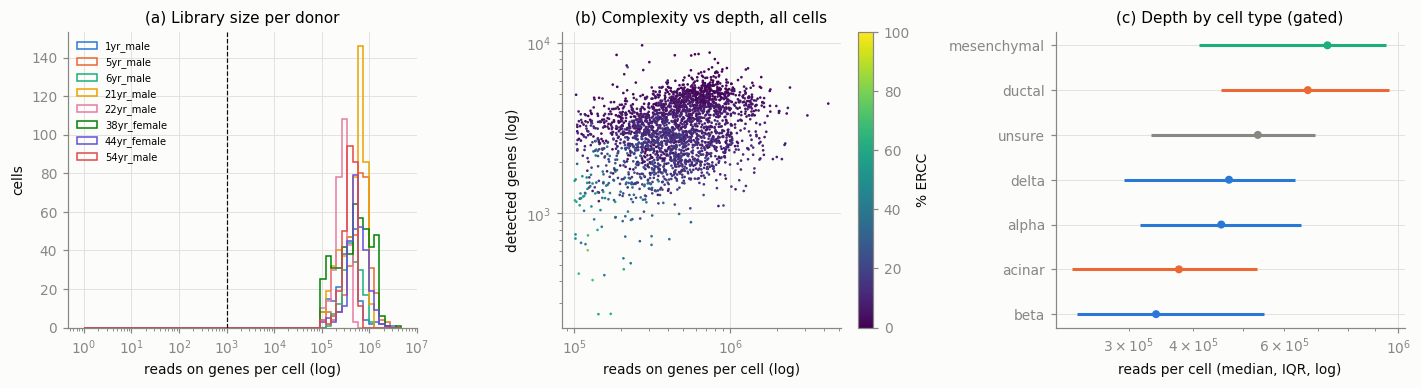

Shared-rule pass rate per donor (%): {'1yr_male': 100.0, '5yr_male': 99.4, '6yr_male': 99.4, '21yr_male': 100.0, '22yr_male': 100.0, '38yr_female': 99.6, '44yr_female': 100.0, '54yr_male': 99.6}
Pass rate per plate (%): min 96.6, median 100.0, max 100.0; plates below 60%: 0 of 42
Median reads per donor (gated): {'1yr_male': 378931.0, '5yr_male': 707350.0, '6yr_male': 440011.0, '21yr_male': 570642.0, '22yr_male': 272162.0, '38yr_female': 510576.0, '44yr_female': 551063.0, '54yr_male': 416741.0}
Median detected genes per donor (gated): {'1yr_male': 2063.0, '5yr_male': 2576.0, '6yr_male': 2127.0, '21yr_male': 4726.0, '22yr_male': 2960.0, '38yr_female': 3762.0, '44yr_female': 4143.0, '54yr_male': 2796.0}
Median top-gene fraction by type (gated):
 cell_type
alpha          0.091
acinar         0.074
delta          0.059
beta           0.055
unsure         0.023
mesenchymal    0.023
ductal         0.017


In [42]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
# (a) library-size distribution per donor (log x-axis)
bins = np.logspace(0, np.log10(qc_f.total_counts.max() * 1.1), 60)
for d, c in DONOR_COLOR_F.items():
    axes[0].hist(qc_f.loc[qc_f.donor == d, "total_counts"].clip(lower=1), bins=bins, histtype="step", lw=1.3, color=c, label=d)
axes[0].axvline(1000, color=INK, lw=0.8, ls="--")
axes[0].set_xscale("log"); axes[0].set_xlabel("reads on genes per cell (log)"); axes[0].set_ylabel("cells")
axes[0].set_title("(a) Library size per donor"); axes[0].legend(fontsize=6.5)
# (b) detected genes vs reads, coloured by %ERCC
sca = axes[1].scatter(qc_f.total_counts.clip(lower=1), qc_f.n_genes.clip(lower=1), c=qc_f.pct_ercc, s=3,
                      cmap="viridis", vmin=0, vmax=100, linewidths=0)
fig.colorbar(sca, ax=axes[1], label="% ERCC")
axes[1].set_xscale("log"); axes[1].set_yscale("log")
axes[1].set_xlabel("reads on genes per cell (log)"); axes[1].set_ylabel("detected genes (log)")
axes[1].set_title("(b) Complexity vs depth, all cells")
# (c) library size per cell type (gated cells, median and IQR)
q = qc_f[GATE_F]
g = q.groupby("cell_type")["total_counts"]
order = g.median().sort_values().index
med, q1, q3 = g.median()[order], g.quantile(.25)[order], g.quantile(.75)[order]
y = np.arange(len(order)); cols = [LINEAGE_COLOR[LINEAGE[t]] for t in order]
axes[2].hlines(y, q1, q3, color=cols, lw=2); axes[2].scatter(med, y, color=cols, s=18, zorder=3)
axes[2].set_yticks(y, order); axes[2].set_xscale("log"); axes[2].set_xlabel("reads per cell (median, IQR, log)")
axes[2].set_title("(c) Depth by cell type (gated)")
fig.tight_layout(); plt.show()

print("Shared-rule pass rate per donor (%):", (pd.Series(GATE_F).groupby(donor_f.to_numpy()).mean() * 100).round(1)[DONOR_ORDER_F].to_dict())
plate_pass = pd.Series(GATE_F).groupby(qc_f.plate.to_numpy()).mean() * 100
print(f"Pass rate per plate (%): min {plate_pass.min():.1f}, median {plate_pass.median():.1f}, max {plate_pass.max():.1f};"
      f" plates below 60%: {int((plate_pass < 60).sum())} of {len(plate_pass)}")
print("Median reads per donor (gated):", q.groupby("donor").total_counts.median().round(0)[DONOR_ORDER_F].to_dict())
print("Median detected genes per donor (gated):", q.groupby("donor").n_genes.median().round(0)[DONOR_ORDER_F].to_dict())
print("Median top-gene fraction by type (gated):\n", q.groupby("cell_type").top_gene_frac.median().sort_values(ascending=False).round(3).to_string())

**QC observations**
* **The data have already been filtered**, in the wet lab (only wells with good cDNA were sequenced, F.0), and the
  distributions confirm it. In (a) every cell has ≥ 100k reads on genes and there is no low-depth mode; the shared
  rule (≥ 500 genes, ≥ 1,000 reads) removes only **6 of 2,544 cells** (2 acinar, 2 beta, 1 alpha, 1 delta), and every
  plate keeps ≥ 96.6% of its cells.
* **But complexity is modest for so many reads:** median 3,204 detected genes, 32 cells below 1,000 and 373 below
  2,000 genes. In (b) the cells with fewer genes are those with a high ERCC share (up to 80%), which marks cells with
  little endogenous RNA. Duplicate removal also limits how many reads a highly expressed gene can keep.
* **Children's cells are less complex:** median detected genes are 2,063 / 2,576 / 2,127 for the 1-, 5- and
  6-year-old, but 2,796–4,726 for the adults (4,726 for the 21-year-old). Since donor = plate, this mixes biology
  (age), donor and plate effects, and cannot be separated here. Median depth per donor ranges from 272k
  (22-year-old) to 707k (5-year-old) reads.
* **Depth by type** (c): mesenchymal and ductal cells are deepest and beta cells shallowest; the top gene takes at
  most 9% of a median cell's reads (alpha), far less than in Baron, Xin or Segerstolpe.

## F.5 Gene-level behaviour: detection, top genes, mean–variance relationship
Computed on the cells passing the shared rule and without ERCC spike-ins.

In [43]:
enge_g = enge[GATE_F, ~ercc_f].copy()
print(f"Gated cells x biological genes: {enge_g.n_obs} x {enge_g.n_vars}")
n_expr_f, mean_f, var_f = gene_level(enge_g, "reads")

Gated cells x biological genes: 2538 x 23368


Genes detected in at most k cells:
  <=  0 cells:  1994  (8.5%)
  <=  2 cells:  3812  (16.3%)
  <=  9 cells:  6120  (26.2%)
  <= 19 cells:  7412  (31.7%)
  <= 49 cells:  9282  (39.7%)

Top-15 genes by share of all reads (%):
GCG       3.29
MALAT1    1.75
TTR       1.34
PRSS1     0.86
CPA1      0.60
REG1A     0.56
CPB1      0.53
ACTB      0.53
PNLIP     0.47
CLU       0.46
INS       0.46
SCG5      0.42
EEF1A1    0.40
B2M       0.40
CELA3A    0.38


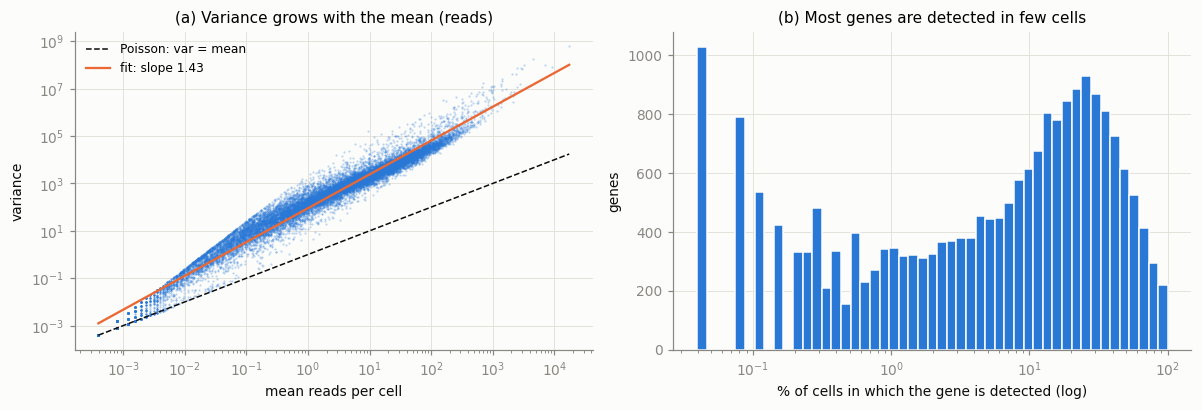

Fitted log-log slope of variance vs mean: 1.43


In [44]:
slope_f = plot_gene_level(n_expr_f, mean_f, var_f, enge_g.n_obs, "reads")
print(f"Fitted log-log slope of variance vs mean: {slope_f:.2f}")

**Gene-level observations** (2,538 cells passing the shared rule, 23,368 genes)
* **Log-log slope 1.43**, the same as Segerstolpe's Smart-seq2 reads (1.41): full-length, PCR-amplified read counts
  are clearly overdispersed even after deduplication. log1p as before.
* **Top genes:** GCG 3.3%, MALAT1, TTR, then acinar enzymes (PRSS1, CPA1, CPB1, PNLIP, CELA3A) and REG1A, reflecting
  the large exocrine share (31% of cells). **INS is only 0.46% of all reads** (Baron 5.3%); beta cells are 14% of the
  cells and the shallowest type, and some beta cells are hidden under `unsure`.
* **Detection is intermediate:** 8.5% of genes are never detected, 26.2% in fewer than 10 cells and 39.7% in fewer
  than 50; panel (b) has its mode around 20–30% of cells, between the UMI datasets and Segerstolpe.

## F.6 Labels vs markers, and how "clean" are the markers?
Baron panel + independent endocrine markers, then the independent check panel of C.6, both on the gated cells by
author label. Enge has **no gamma/PP, epsilon, endothelial or immune label**, so the corresponding markers test whether
such cells are hidden in other labels; the hormone-purity check includes PPY for the same reason.

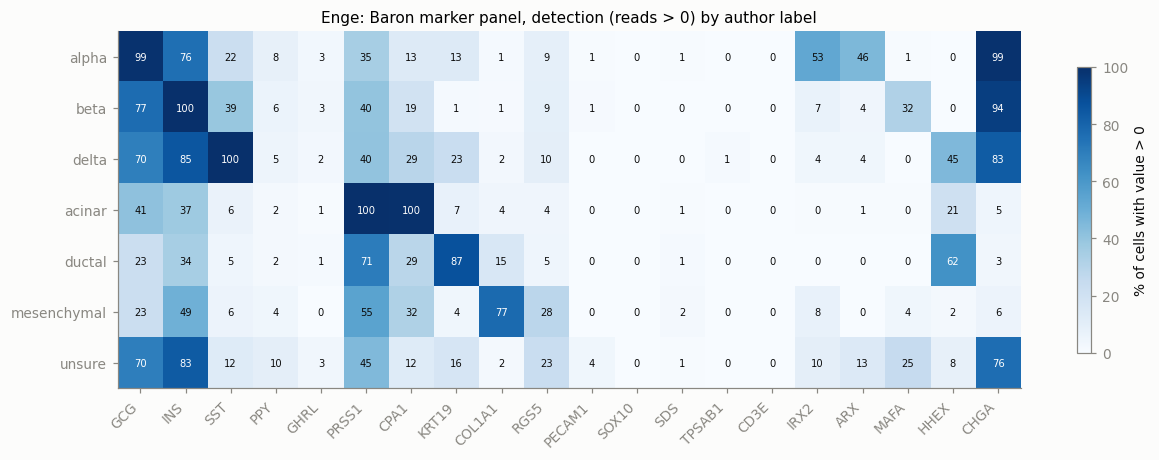

Panel markers not present (exactly once) in this dataset: []


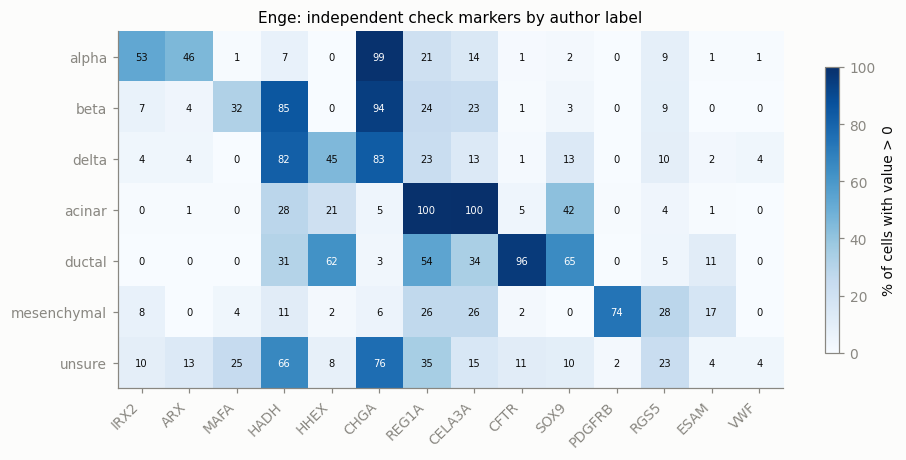

In [45]:
ct_fg = ct_f[GATE_F]
order_f = type_order(ct_fg)
detect_f = detection_heatmap(enge_g, list(MARKERS.values()) + EXTRA_ENDOCRINE, ct_fg, order_f,
                             "Enge: Baron marker panel, detection (reads > 0) by author label")
missing = [g for g in dict.fromkeys(list(MARKERS.values()) + EXTRA_ENDOCRINE + CHECK) if (enge_g.var["symbol"] == g).sum() != 1]
print("Panel markers not present (exactly once) in this dataset:", missing)
check_f = detection_heatmap(enge_g, CHECK, ct_fg, order_f, "Enge: independent check markers by author label")

In [46]:
HORMONE_F = {"alpha": "GCG", "beta": "INS", "delta": "SST", "gamma": "PPY"}
purity_f, top_h_f, mixed_f = hormone_purity(enge_g, ct_fg, HORMONE_F, ["alpha", "beta", "delta"])
display(purity_f)
print("Top hormone among cells labelled alpha / beta / delta / unsure:")
sel = ct_fg.isin(["alpha", "beta", "delta", "unsure"]).to_numpy()
display(pd.crosstab(ct_fg[sel], top_h_f[sel].rename("top hormone"), margins=True))
ppy_f = gene_vec(enge_g, "PPY")
print("Cells whose top hormone is PPY:", int((top_h_f == "gamma").sum()), "| of them labelled:",
      ct_fg[(top_h_f == "gamma").to_numpy()].value_counts().to_dict())
print("\n'unsure' cells: donor x top hormone")
uns = (ct_fg == "unsure").to_numpy()
display(pd.crosstab(don_fg_all := donor_f[GATE_F][uns], top_h_f[uns].rename("top hormone"), margins=True)
        .reindex([d for d in DONOR_ORDER_F if d in set(don_fg_all)] + ["All"]))
print("Cells labelled beta per donor:", ct_fg[ct_fg == "beta"].groupby(donor_f[GATE_F][ct_fg == "beta"]).size()
      .reindex(DONOR_ORDER_F).fillna(0).astype(int).to_dict())

,n_cells,top hormone = label,top hormone != label,two hormones high (mixed)
alpha,997,981,16,5
beta,346,321,25,21
delta,82,78,4,7


Top hormone among cells labelled alpha / beta / delta / unsure:


top hormone,alpha,beta,delta,gamma,All
cell_type1,,,,,
alpha,981,14,1,1,997
beta,25,321,0,0,346
delta,4,0,78,0,82
unsure,59,179,4,20,262
All,1069,514,83,21,1687


Cells whose top hormone is PPY: 30 | of them labelled: {'unsure': 20, 'ductal': 5, 'acinar': 4, 'alpha': 1}

'unsure' cells: donor x top hormone


top hormone,alpha,beta,delta,gamma,All
donor,,,,,
1yr_male,4,5,1,2,12
5yr_male,5,0,0,0,5
6yr_male,14,8,0,4,26
21yr_male,22,144,1,0,167
22yr_male,7,16,2,3,28
38yr_female,1,0,0,0,1
44yr_female,4,1,0,5,10
54yr_male,2,5,0,6,13
All,59,179,4,20,262


Cells labelled beta per donor: {'1yr_male': 48, '5yr_male': 35, '6yr_male': 43, '21yr_male': 4, '22yr_male': 89, '38yr_female': 68, '44yr_female': 24, '54yr_male': 35}


**Marker observations**
* **The labelled types are consistent with their markers, though sensitivity is lower than in D/E:** IRX2/ARX in
  53/46% of alpha (83–89% in D/E), MAFA in 32% and HADH in 85% of beta, HHEX in 45% of delta, PRSS1/CPA1 and
  REG1A/CELA3A in 100% of acinar, KRT19/CFTR in 87/96% of ductal, and COL1A1/PDGFRB in 77/74% of mesenchymal cells.
  Immune and Schwann markers (SDS, TPSAB1, CD3E, SOX10) are essentially absent, and PECAM1 (≤ 4%) / ESAM (≤ 17%)
  show no endothelial population.
* **The ambient hormone signal is weaker than in Segerstolpe:** GCG is detected in 70–77% of other endocrine cells
  but only 23–41% of exocrine/mesenchymal cells, and INS in 34–85% of non-beta cells.
* **Hormone purity of the labelled endocrine cells is good but not perfect:** 981 of 997 alpha, 321 of 346 beta (25
  have GCG on top) and 78 of 82 delta cells have their own hormone on top.
* **The `unsure` cells are mostly unlabelled endocrine cells, and they come mainly from one donor.** Among the 262
  `unsure` cells the dominant hormone is INS in 179, GCG in 59, PPY in 20 and SST in 4. **144 of the 21-year-old's
  167 `unsure` cells have INS on top**, while that donor has only 4 cells labelled beta (every other donor has
  24–89). The authors evidently did not assign that donor's beta cells. This is a labelling gap, not biology.
* **PP cells exist but have no label:** 30 cells have PPY as their dominant hormone, labelled `unsure` (20), ductal
  (5), acinar (4) and alpha (1). A classifier that correctly predicts "gamma" on F would be scored as wrong.

## F.7 Global structure: do cells group by type, by donor or by age?
Same throw-away pipeline as for Baron, on the gated cells without spike-ins. Enge's design axis is **age**, so
besides donor the silhouette is also computed for child (1, 5, 6 years) vs adult (21–54 years) donors.

In [47]:
P_f, evr_f, load_f = throwaway_pca(enge_g)
don_fg = donor_f[GATE_F]
age_grp_f = np.where(enge_g.obs.age.to_numpy() <= 6, "child (<= 6 y)", "adult (>= 21 y)")
known_f = (ct_fg != "unsure").to_numpy()
sil_type_f = silhouette_score(P_f[known_f, :20], ct_fg[known_f], random_state=SEED)
sil_donor_f = silhouette_score(P_f[:, :20], don_fg, random_state=SEED)
sil_age_f = silhouette_score(P_f[:, :20], age_grp_f, random_state=SEED)
print(f"\nSilhouette by cell type (without unsure): {sil_type_f:.3f}   by donor: {sil_donor_f:.3f}   by age group: {sil_age_f:.3f}")
within_fd = {t: silhouette_score(P_f[(ct_fg == t).to_numpy(), :20], don_fg[(ct_fg == t).to_numpy()]) for t in ["alpha", "beta", "ductal", "acinar"]}
within_fa = {t: silhouette_score(P_f[(ct_fg == t).to_numpy(), :20], age_grp_f[(ct_fg == t).to_numpy()]) for t in ["alpha", "beta", "ductal", "acinar"]}
print("Silhouette *within* one cell type, by donor:", {k: round(v, 3) for k, v in within_fd.items()})
print("                                  by age group:", {k: round(v, 3) for k, v in within_fa.items()})
for pc in load_f:
    print(f"{pc} top +: {load_f[pc].nlargest(8).index.tolist()}\n    top -: {load_f[pc].nsmallest(8).index.tolist()}")

Explained variance, PC1..PC10 (%): [5.8 3.8 3.  1.5 1.1 1.  0.9 0.7 0.7 0.6]
Cumulative variance in 20 / 50 PCs: 22.8% / 28.8%



Silhouette by cell type (without unsure): 0.292   by donor: 0.018   by age group: 0.085
Silhouette *within* one cell type, by donor: {'alpha': 0.256, 'beta': 0.13, 'ductal': 0.38, 'acinar': 0.224}
                                  by age group: {'alpha': 0.07, 'beta': 0.124, 'ductal': 0.196, 'acinar': 0.194}
PC1 top +: ['SERPING1', 'IFITM3', 'LGALS3', 'CLDN1', 'SDC4', 'LITAF', 'TACSTD2', 'CCL2']
    top -: ['TTR', 'ABCC8', 'MALAT1', 'GCG', 'CRYBA2', 'UCHL1', 'FLJ43390', 'G6PC2']
PC2 top +: ['DCN', 'MGP', 'SPARC', 'C7', 'FBLN1', 'TIMP3', 'COL1A2', 'LUM']
    top -: ['CLDN1', 'TACSTD2', 'KRT19', 'ANXA4', 'PRSS8', 'CLDN4', 'MMP7', 'SERPINA5']


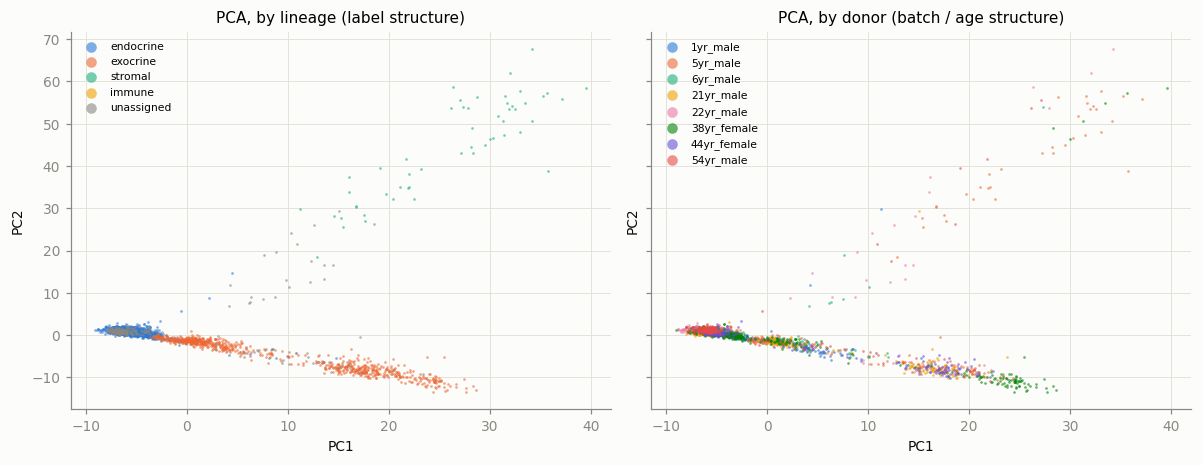

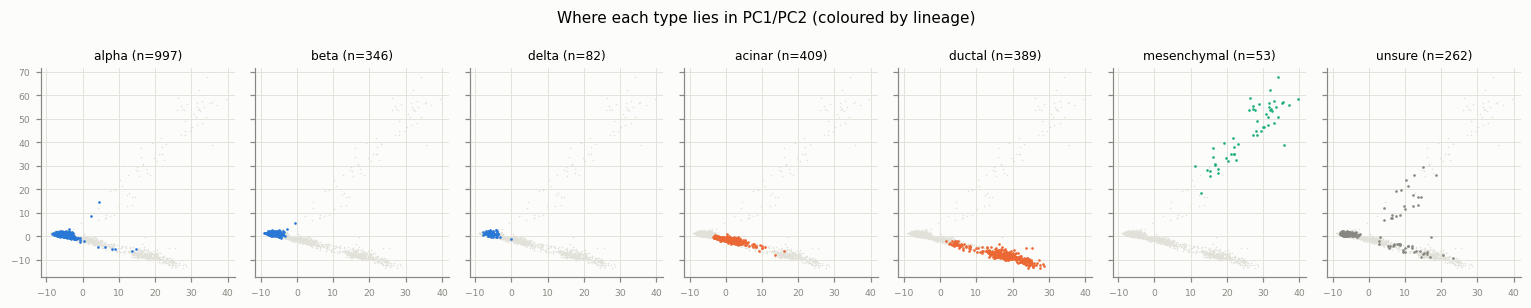

In [48]:
rng = np.random.default_rng(SEED)
perm_f = rng.permutation(enge_g.n_obs)
lin_f = ct_fg.map(LINEAGE).to_numpy()
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3), sharex=True, sharey=True)
scatter_groups(axes[0], P_f, lin_f, LINEAGE_COLOR, "PCA, by lineage (label structure)", perm_f)
scatter_groups(axes[1], P_f, don_fg, DONOR_COLOR_F, "PCA, by donor (batch / age structure)", perm_f)
fig.tight_layout(); plt.show()

fig, axes = plt.subplots(1, len(order_f), figsize=(14, 2.8), sharex=True, sharey=True)
for ax, t in zip(axes, order_f):
    s = (ct_fg == t).to_numpy()
    ax.scatter(P_f[~s, 0], P_f[~s, 1], s=1, color=GRID, linewidths=0)
    ax.scatter(P_f[s, 0], P_f[s, 1], s=3, color=LINEAGE_COLOR[LINEAGE[t]], linewidths=0)
    ax.set_title(f"{t} (n={s.sum()})", fontsize=8); ax.tick_params(labelsize=6)
fig.suptitle("Where each type lies in PC1/PC2 (coloured by lineage)", fontsize=10)
fig.tight_layout(); plt.show()

**Structure observations**
* **Cell type dominates the overall structure** (silhouette 0.29 by type without `unsure`), with the same layout as
  D/E: PC1 (5.8%) endocrine (TTR, ABCC8, GCG, G6PC2) vs non-endocrine (SERPING1, IFITM3, LGALS3, TACSTD2); PC2
  (3.8%) mesenchymal (DCN, MGP, SPARC, COL1A2, LUM) vs ductal (CLDN1, KRT19, MMP7). 20 PCs hold 22.8% of the
  variance.
* **The donor effect within a type is the strongest of all six datasets:** donor silhouettes are 0.26 (alpha),
  0.13 (beta), 0.38 (ductal) and 0.22 (acinar), compared with 0.12–0.17 in Baron, ≤ 0.15 in Segerstolpe and negative
  values in Xin and Lawlor. In the donor panel the exocrine arm is visibly ordered by donor. The overall donor
  silhouette (0.02) hides this because types dominate. Since donor = plate = age here, this is a batch effect and
  possibly an age effect at the same time (by age group: 0.07–0.20 within types).
* **`unsure` cells sit mostly in the endocrine cluster** (consistent with F.6), with a minority spread along the
  exocrine and mesenchymal arms.

## F.8 Summary of the Enge inspection

| aspect | Enge (GSE81547) |
|---|---|
| cells × features | 2,544 × 23,460 (23,368 genes + 92 ERCC) |
| technology | Smart-seq2-style plate protocol, full-length, NextSeq 500, duplicates removed, HTSeq on UCSC hg19 |
| values available | raw read counts (one GEO file per cell) |
| labels | in the GEO SOFT file (`inferred_cell_type`); 262 `unsure`; no PP label |
| missing values | none |
| prior QC | yes (wet-lab cDNA QC; shared rule removes 6 cells) |
| MT genes | absent (no %MT QC); ERCC spike-ins present |
| classes | 6 types + unsure; alpha 998 … mesenchymal 53, imbalance 19× |
| batch structure | 8 donors aged 1–54 (no donor ID; donor = plate set), **strong donor/plate effect within types** |
| notable | 21-year-old's beta cells labelled `unsure`; PP cells unlabelled; age axis (children vs adults) |

## F.9 Proposed preprocessing for Enge (for discussion)

* **Step A — cell filtering (R4).** Shared rule (6 cells removed); no %MT filter; remove ERCC after QC.
* **Step B — labels (decision needed).** Exclude `unsure` (262) from training and labelled evaluation. Two problems
  remain that affect any evaluation on F: (1) the 21-year-old donor has almost no labelled beta cells (they are in
  `unsure`), and (2) **PP cells exist but are unlabelled**. Options: (a) use F only for types whose labels look
  complete (alpha, acinar, ductal, delta, mesenchymal) and treat beta/PP with care; (b) drop the 21-year-old from
  labelled evaluation; (c) keep F as an **unlabelled / open-set query**, where `unsure` cells are realistic
  "uncertain" cells. `mesenchymal` → stellate parent node, as for Muraro.
* **Step C — genes (R2, R5).** Drop ERCC and the HTSeq artefact names, then intersect (18,148 genes shared with
  Baron).
* **Step D — normalisation (R3).** `normalize_total` (10,000) + `log1p` on the raw read counts; no deviation.
* **Batch structure.** Donor, plate and age are fully confounded, and the within-type donor effect is strong. A
  **child (1–6 y) → adult (21–54 y)** split is a natural biological-shift scenario (age), but it cannot be separated
  from plate effects. Leave-one-donor-out within F would test robustness to a strong batch effect.
* **Role in the study:** an E2 query for **A → F** (3' UMI → full-length reads, plus an age shift), most of whose
  labelled types exist in Baron, and a stress test for donor/batch effects.

---
# Cross-dataset comparison: D (Segerstolpe), E (Lawlor), F (Enge), and A/B/C
Analogous to the cross-dataset section of `data_preview_dataset_B_and_C.ipynb`: gene overlap, label vocabularies and
one summary table. A, B and C are loaded from the existing `data/interim/{baron,xin,muraro}_human.h5ad` (read-only;
they are not rebuilt here). For C, the `cell_type1` column of the current `muraro_human.h5ad` is used (author labels
from ExperimentHub EH2693, NaN = removed by the authors' QC).

In [49]:
baron = ad.read_h5ad(BARON_H5)
xin = ad.read_h5ad(XIN_H5)
mur = ad.read_h5ad(MURARO_H5)
genes = {
    "A Baron": set(baron.var_names),
    "B Xin": set(xin.var.symbol[xin.var.mapped]),
    "C Muraro": set(mur.var.symbol[~mur.var.is_ercc]),
    "D Segerstolpe": set(seg.var.symbol[bio_d]),
    "E Lawlor": set(law.var.symbol),
    "F Enge": set(enge.var.symbol[~ercc_f]),
}
ov = pd.DataFrame({a: {b: len(genes[a] & genes[b]) for b in genes} for a in genes})
display(ov)
common_def = genes["D Segerstolpe"] & genes["E Lawlor"] & genes["F Enge"]
common_all = set.intersection(*genes.values())
print(f"Genes shared by D, E and F: {len(common_def)} | shared by all six datasets: {len(common_all)}")
key_markers = ["INS", "GCG", "SST", "PPY", "GHRL", "PRSS1", "CPA1", "KRT19", "COL1A1", "PECAM1", "IRX2", "ARX", "MAFA", "HHEX", "CHGA"]
print("Key markers missing from the six-way intersection:",
      {g: [k for k in genes if g not in genes[k]] for g in key_markers if g not in common_all})

,A Baron,B Xin,C Muraro,D Segerstolpe,E Lawlor,F Enge
A Baron,20125,18199,16475,18936,18143,18148
B Xin,18199,37987,16650,21732,17652,19736
C Muraro,16475,16650,19046,18361,16826,18237
D Segerstolpe,18936,21732,18361,25453,18909,21511
E Lawlor,18143,17652,16826,18909,26491,18797
F Enge,18148,19736,18237,21511,18797,23368


Genes shared by D, E and F: 18323 | shared by all six datasets: 14746
Key markers missing from the six-way intersection: {'PECAM1': ['E Lawlor']}


In [50]:
# Label vocabularies side by side. Only the spelling is harmonised (lower case; PP / pp / gamma/pp -> gamma; duct -> ductal);
# types are NOT merged (e.g. Segerstolpe 'psc', Lawlor 'stellate', Muraro/Enge 'mesenchymal' stay separate rows).
harm = lambda s: pd.Series(s).astype(str).str.lower().replace({"pp": "gamma", "gamma/pp": "gamma", "duct": "ductal"}).value_counts()
mur_lab = mur.obs["cell_type1"].dropna() if "cell_type1" in mur.obs else pd.Series(dtype=str)
labels = pd.DataFrame({
    "A Baron": harm(baron.obs.cell_type1),
    "B Xin": harm(xin.obs.cell_type1),
    "C Muraro": harm(mur_lab),
    "D Segerstolpe (QC-pass)": harm(ct_d),
    "E Lawlor": harm(ct_e),
    "F Enge (all)": harm(ct_f),
}).fillna(0).astype(int)
LINEAGE.setdefault("unclear", "unassigned")
labels["lineage"] = labels.index.map(lambda t: LINEAGE.get(t, "?"))
labels = labels.sort_values(["lineage", "A Baron"], ascending=[True, False])
display(labels)

ds = {"A Baron": (baron, baron.obs.cell_type1, baron.obs.human),
      "B Xin": (xin, xin.obs.cell_type1, xin.obs.donor),
      "C Muraro": (mur, mur_lab, mur.obs.donor),
      "D Segerstolpe": (seg, ct_d, seg.obs.donor),
      "E Lawlor": (law, ct_e, law.obs.donor),
      "F Enge": (enge, ct_f, enge.obs.donor)}
UNASSIGNED_LIKE = {"unclear", "none/other", "unsure", "unclassified", "unclassified_endocrine", "co-expression", "not_applicable"}
display(pd.DataFrame({k: {"cells deposited": a.n_obs, "features": a.n_vars, "labelled cells": len(l),
                          "author labels": pd.Series(l).nunique(),
                          "of which real types": len(set(pd.Series(l).astype(str).str.lower()) - UNASSIGNED_LIKE),
                          "donors": pd.Series(dn).nunique()} for k, (a, l, dn) in ds.items()}).T)

,A Baron,B Xin,C Muraro,D Segerstolpe (QC-pass),E Lawlor,F Enge (all),lineage
cell_type1,,,,,,,
beta,2525,503,448,270,264,348,endocrine
alpha,2326,946,812,886,239,998,endocrine
delta,601,58,193,114,25,83,endocrine
gamma,255,93,101,197,18,0,endocrine
epsilon,18,0,3,7,0,0,endocrine
co-expression,0,0,0,39,0,0,endocrine
unclassified_endocrine,0,0,0,41,0,0,endocrine
ductal,1077,0,245,386,28,389,exocrine
acinar,958,0,219,185,24,411,exocrine


,cells deposited,features,labelled cells,author labels,of which real types,donors
A Baron,8569,20125,8569,14,14,4
B Xin,1600,39851,1600,4,4,18
C Muraro,3072,19140,2126,10,9,4
D Segerstolpe,3514,26271,2209,14,11,10
E Lawlor,638,26616,638,8,7,8
F Enge,2544,23460,2544,7,6,8


## Summary across datasets

| aspect | A: Baron | B: Xin | C: Muraro | D: Segerstolpe | E: Lawlor | F: Enge |
|---|---|---|---|---|---|---|
| accession | GSE84133 | GSE81608 | GSE85241 | E-MTAB-5061 | GSE86469 | GSE81547 |
| cells deposited × features | 8,569 × 20,125 | 1,600 × 39,851 | 3,072 × 19,140 | 3,514 × 26,271 | 638 × 26,616 | 2,544 × 23,460 |
| technology | inDrop, 3' UMI | C1 SMARTer, full-length | CEL-seq2, 3' UMI | Smart-seq2, full-length | C1 SMARTer, full-length | Smart-seq2-like, full-length |
| values | raw UMI counts | **RPKM only** | UMI-corrected transcripts | **raw reads + RPKM** | **RSEM expected counts** (SOFT says TPM) | raw reads (deduplicated) |
| R3 possible as written | yes | no | yes | yes (counts) | yes (fractional counts) | yes |
| labelled cells / labels / real types | 8,569 / 14 / 14 | 1,600 / 4 / 4 | 2,126 / 10 / 9 | 2,209 / 14 / 11 | 638 / 8 / 7 | 2,544 / 7 / 6 |
| label source | curated `.rds` | GEO SOFT | ExperimentHub EH2693 | ArrayExpress SDRF | GEO SOFT | GEO SOFT |
| prior QC in matrix | yes | yes | no | **no** (author flag) | yes (+ multi-marker cells removed) | yes |
| MT genes | removed | present (no prefix) | absent | absent | present (`MT-`) | absent |
| spike-ins | none | none | 81 ERCC | 92 ERCC + eGFP | none | 92 ERCC |
| donors | 4 | 18 (12 ND / 6 T2D) | 4 | 10 (6 ND / 4 T2D) | 8 (5 ND / 3 T2D) | 8 (ages 1–54) |
| var/mean slope | ≈ 1.1 | ≈ 1.5 | ≈ 1.2 | 1.41 | 1.51 | 1.43 |
| silhouette type / donor | 0.31 / 0.05 | 0.27 / −0.12 | – | 0.30 / −0.10 | 0.36 / −0.10 | 0.29 / 0.02 (within types up to 0.38) |
| ambient profile | INS everywhere | GCG everywhere, INS often | GCG + SST everywhere | **all four hormones everywhere** | GCG + INS + COL1A1 low-level everywhere | GCG/INS, weaker |

The counts, label numbers and donors for A–C come from the table printed above (computed from the existing
`data/interim` files); the slopes and silhouettes for A and B are those printed in `data_preview.ipynb` and
`data_preview_dataset_B_and_C.ipynb`. C's slope is from the stored outputs of B_and_C; its silhouettes are left out
because those outputs used provisional labels.

**Gene overlap:** D, E and F share 18,323 symbols, and **all six datasets share 14,746** (A/B/C alone: 15,400 in
B_and_C). Every key marker is in the six-way intersection **except PECAM1, which is missing only from Lawlor's
matrix**. Each new dataset shares about 18,100–19,000 genes with Baron.

**Label overlap** (spelling harmonised only: PP/pp/Gamma/PP → gamma, duct → ductal): alpha, beta and delta exist
in all six datasets; ductal and acinar in all but Xin; gamma in all but Enge. Stellate-like cells
have five different names: Baron's activated/quiescent stellate, Segerstolpe's `psc`, Lawlor's `stellate`, and
Muraro's/Enge's `mesenchymal`. They need one parent node in the hierarchy. Immune cells exist only in A (macrophage,
mast, T cell) and D (mast, MHC class II); endothelial cells in A, C and D. Each new dataset also has its own
"uncertain" labels (D: `co-expression`, `unclassified_endocrine`, `unclassified`; E: `none/other`; F: `unsure`),
and these have to be kept out of the labelled class sets in the same way as Camp's "Unknown".

**Technology pattern across the six:** the four full-length datasets (B, D, E, F) all have steeper mean–variance
slopes (1.4–1.5) than the UMI datasets (1.1–1.2), and much higher per-cell gene detection. Each
dataset has its own ambient hormone profile. Both are technology-level differences that a Baron-trained model will
meet in every cross-technology scenario.

## Questions to agree on before preprocessing D, E and F
1. **Segerstolpe cell filter:** apply the authors' SDRF QC flag (2,209 cells) on top of the shared rule? The shared
   rule alone keeps 764 low-quality, 36 empty and 26 two-cell wells. Should the 32 two-cell wells be kept as a
   labelled doublet test set?
2. **"Uncertain" labels:** exclude `co-expression`, `unclassified_endocrine`, `unclassified` (D), `none/other` (E)
   and `unsure` (F) from training and labelled evaluation, and use them only as realistic uncertain query cells?
3. **Enge's incomplete labels:** the 21-year-old donor's beta cells sit in `unsure`, and PP cells are unlabelled.
   Use F only for its reliably labelled types, drop that donor from labelled evaluation, or treat F mainly as an
   open-set / unlabelled query?
4. **Stellate harmonisation:** map `psc` (D), `stellate` (E) and `mesenchymal` (C, F) to one parent node above
   Baron's activated/quiescent stellate, and `mhc_class_ii` (D) to `macrophage`? This is a hierarchy (HOE) decision.
5. **Units:** use D's raw counts (not RPKM) and E's RSEM expected counts as counts (unrounded), so that R3 applies
   to A, C, D, E and F as written and Xin remains the only documented deviation?
6. **Gene handling:** sum duplicated symbols (Segerstolpe's repeated RefSeq rows, Lawlor's 120 shared names) or drop
   them, and drop Segerstolpe's `+`-joined rows, before intersecting? With all six datasets the intersection is
   14,746 genes; is losing PECAM1 (absent in Lawlor) acceptable, or should Lawlor scenarios use a separate gene set?
7. **Scenarios:** A → D as the second main technology-shift test (Smart-seq2, most classes shared, including immune
   cells); B ↔ E as a same-technology, different-lab pair; ND → T2D within D (and E, B) as a condition shift;
   child → adult within F as an age shift (confounded with plate)?